<a href="https://colab.research.google.com/github/paddy960609/chicago_traffic_asset_management/blob/main/chicago_traffic_asset_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Executive Summary
## Chicago Transportation Congestion & Capital Investment Prioritization Strategy

### Project Overview

This project develops a data-driven framework to help the Chicago Department of Transportation (CDOT) prioritize transportation investments under constrained capital funding. It expands a congestion analytics project into a hypothetical five-year, $250 million capital program designed to identify high-need corridors, evaluate competing investment priorities, and translate analytical findings into a phased investment strategy.

The analysis integrates three dimensions of transportation need: **traffic congestion, roadway safety, and public transit exposure**. Using Python, geospatial analysis, and multi-criteria decision analysis, the project screens candidate corridors, evaluates potential interventions, and tests how budget, reserve, and implementation constraints affect capital allocation.

### Analytical Approach

The study evaluates 95 investment corridors derived from 99 connected traffic components, consolidating bidirectional components where appropriate to avoid double-counting investment needs.

- **Congestion:** Analyzed Chicago Traffic Tracker observations from June 2024 onward, using weekday operating conditions, baseline-relative speed reductions, and congestion frequency to develop corridor-level priority scores.
- **Roadway safety:** Integrated crash data and calculated crashes per mile to identify corridors with concentrated safety burdens.
- **Transit exposure:** Combined CTA bus route geometry with 2025 route-level ridership to estimate transit ridership exposure associated with qualifying routes. This serves as a comparative exposure proxy rather than a direct measure of corridor-level boardings.
- **Investment prioritization:** Applied percentile-based scoring and a preliminary weighted model assigning 40% to safety, 35% to transit exposure, and 25% to congestion. Congestion established the initial screening framework, while safety and transit exposure helped distinguish strategic, multimodal corridors from more targeted investment opportunities.

The resulting candidate pool included 13 higher-priority corridors with elevated safety and transit scores, supplemented by six targeted corridors selected to represent additional safety- or transit-led investment opportunities.

### Capital Allocation & Scenario Analysis

Five intervention categories were developed, ranging from operational and signal optimization to intersection safety improvements, corridor modernization, and transit-priority investments. Preliminary low, midpoint, and high cost estimates were assigned to each intervention category to support capital planning.

Under a $250 million total program cap, including a $25 million reserve, an illustrative optimized portfolio selected 11 projects with a combined midpoint cost of $222.5 million. The portfolio comprised nine Tier 1 corridors and two targeted Tier 2 corridors, leaving $2.5 million of uncommitted capacity at midpoint estimates.

The analysis also tested implementation constraints, including a maximum of $120 million in spending during Years 1–3 and a remaining $130 million allocation for Years 4–5. The selected portfolio's illustrative five-year spending profiles reconcile to the project midpoint costs and satisfy the early-period spending cap under the assumed phasing approach.

Cost sensitivity analysis highlights a material funding risk. The selected portfolio's estimated project cost ranges from $145 million under the low-cost scenario to $300 million under the high-cost scenario. Including the $25 million reserve, total commitment could reach $325 million—$75 million above the program cap. A separate scenario requiring at least nine Tier 1 projects was infeasible under a $200 million net capital budget after reserving $25 million from the overall $225 million budget.

### Key Findings & Recommendations

The analysis demonstrates that transportation investment prioritization is not simply a matter of ranking corridors by congestion or safety. The recommended portfolio depends on how decision-makers balance multimodal benefits, project costs, delivery capacity, and risk tolerance.

The study recommends that CDOT use a transparent, multi-criteria screening framework to establish investment priorities, followed by project-level feasibility review and capital programming. Before committing funding, the illustrative portfolio should be validated against detailed project scopes, engineering estimates, utility and construction constraints, and delivery readiness. Cost contingencies and alternative funding or deferral strategies should be established to manage the gap between midpoint and high-cost scenarios.

### Conclusion

This project demonstrates an end-to-end approach to infrastructure capital strategy, connecting transportation data and geospatial analytics to investment prioritization, constrained capital allocation, and phased implementation planning. Its principal contribution is a transparent decision-support framework that makes trade-offs visible and allows decision-makers to test how policy objectives, funding limits, and cost uncertainty shape a transportation investment program.

The results are intended as a **hypothetical planning scenario**, not an adopted CDOT capital plan. Final investment decisions would require validation with agency stakeholders, engineering feasibility studies, and more detailed project-level cost and benefit estimates.

In [1]:
import requests
import pandas as pd
!pip install pyarrow -q
import time
from pathlib import Path
import math

def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371000  # Earth radius in meters

    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    delta_phi = math.radians(lat2 - lat1)
    delta_lambda = math.radians(lon2 - lon1)

    a = math.sin(delta_phi / 2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(delta_lambda / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

    distance = R * c
    return distance

def normalize_street_name(x):
    if pd.isna(x):
        return None

    x = str(x).upper().strip()

    replacements = {
        ' AVE': '',
        ' AVENUE': '',
        ' ST': '',
        ' STREET': '',
        ' RD': '',
        ' ROAD': '',
        ' BLVD': '',
        ' BOULEVARD': '',
        ' DR': '',
        ' DRIVE': '',
        ' HWY': '',
        ' HIGHWAY': '',
    }

    for old, new in replacements.items():
        x = x.replace(old, new)

    return x

In [2]:
from collections import Counter

def get_network_endpoints_and_length(
    component_segments_df, # This is a subset of priority_ranking_df for a component
    coord_threshold=0.00001
):
    """
    Identifies the network endpoints of a component and sums its segment lengths.

    Args:
        component_segments_df (pd.DataFrame): DataFrame containing segments for a single component.
        coord_threshold (float): Threshold for considering coordinates to be the same.

    Returns:
        tuple: (start_lat, start_lon, end_lat, end_lon, total_length_m)
               Returns (None, None, None, None, 0) if endpoints can't be clearly determined
               or if component_segments_df is empty.
    """
    if component_segments_df.empty:
        return None, None, None, None, 0

    all_points = []
    for _, row in component_segments_df.iterrows():
        all_points.append((row['start_latitude'], row['start_longitude']))
        all_points.append((row['end_latitude'], row['end_longitude']))

    # Use KDTree to find unique canonical points given the threshold
    unique_coords_list = list(set(all_points))
    if not unique_coords_list:
        return None, None, None, None, 0

    kdtree_unique = KDTree(unique_coords_list)
    canonical_points = {}
    processed_indices = set()
    for i, coord in enumerate(unique_coords_list):
        if i in processed_indices:
            continue
        neighbors_indices = kdtree_unique.query_ball_point(coord, coord_threshold)
        canonical_coord = unique_coords_list[neighbors_indices[0]]
        for idx in neighbors_indices:
            canonical_points[unique_coords_list[idx]] = canonical_coord
            processed_indices.add(idx)

    # Count occurrences of canonical points as segment start/end points within this component
    point_counts = Counter()
    for _, row in component_segments_df.iterrows():
        start_point_canonical = canonical_points.get((row['start_latitude'], row['start_longitude']))
        end_point_canonical = canonical_points.get((row['end_latitude'], row['end_longitude']))
        if start_point_canonical: # Ensure not None
            point_counts[start_point_canonical] += 1
        if end_point_canonical: # Ensure not None
            point_counts[end_point_canonical] += 1

    terminal_points = [p for p, count in point_counts.items() if count == 1]

    component_total_length_m = component_segments_df['segment_geo_length_m'].sum()

    if len(terminal_points) == 2:
        # Identify northernmost as start, southernmost as end
        if terminal_points[0][0] > terminal_points[1][0]:
            component_start_latitude, component_start_longitude = terminal_points[0]
            component_end_latitude, component_end_longitude = terminal_points[1]
        else:
            component_start_latitude, component_start_longitude = terminal_points[1]
            component_end_latitude, component_end_longitude = terminal_points[0]
        return (
            component_start_latitude,
            component_start_longitude,
            component_end_latitude,
            component_end_longitude,
            component_total_length_m
        )
    elif len(terminal_points) > 2:
        # Handle branching components by taking geographical extremes as a fallback
        # In more complex graphs, this might need a more sophisticated graph traversal
        # For now, let's just pick the two most extreme latitudes
        print(f"Warning: Component has more than 2 terminal points. Falling back to max/min latitude for endpoints.")
        all_lats = component_segments_df['start_latitude'].tolist() + component_segments_df['end_latitude'].tolist()
        all_lons = component_segments_df['start_longitude'].tolist() + component_segments_df['end_longitude'].tolist()

        max_lat_idx = all_lats.index(max(all_lats))
        min_lat_idx = all_lats.index(min(all_lats))

        component_start_latitude = all_lats[max_lat_idx]
        component_start_longitude = all_lons[max_lat_idx]

        component_end_latitude = all_lats[min_lat_idx]
        component_end_longitude = all_lons[min_lat_idx]

        return (
            component_start_latitude,
            component_start_longitude,
            component_end_latitude,
            component_end_longitude,
            component_total_length_m
        )
    else:
        # Component is a loop or a single segment, or something ambiguous
        print(f"Warning: Component has 0 or 1 terminal points. Falling back to max/min latitude for endpoints.")
        component_start_latitude = component_segments_df['start_latitude'].max()
        component_start_longitude = component_segments_df[component_segments_df['start_latitude'] == component_start_latitude]['start_longitude'].iloc[0]

        component_end_latitude = component_segments_df['end_latitude'].min()
        component_end_longitude = component_segments_df[component_segments_df['end_latitude'] == component_end_latitude]['end_longitude'].iloc[0]

        return (
            component_start_latitude,
            component_start_longitude,
            component_end_latitude,
            component_end_longitude,
            component_total_length_m
        )

In [3]:
print('Executing cell to define normalize_street_name.')

Executing cell to define normalize_street_name.


In [4]:
# This cell is re-executed to ensure normalize_street_name is available


In [5]:
from google.colab import drive




drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:

import shutil
from pathlib import Path

source_dir = Path("/content/chicago_traffic")

drive_dir = Path(
    "/content/drive/MyDrive/chicago_traffic_project/data"
)

drive_dir.mkdir(
    parents=True,
    exist_ok=True
)

for file in source_dir.glob("*.parquet"):

    shutil.copy2(
        file,
        drive_dir / file.name
    )

print("Files copied to Google Drive:")
for file in sorted(drive_dir.glob("*.parquet")):
    print(file.name)

Files copied to Google Drive:
chicago_traffic_2024-06.parquet
chicago_traffic_2024-07.parquet
chicago_traffic_2024-08.parquet
chicago_traffic_2024-09.parquet
chicago_traffic_2024-10.parquet
chicago_traffic_2024-11.parquet
chicago_traffic_2024-12.parquet


In [7]:

!pip install duckdb -q
import duckdb
print(duckdb.__version__)

1.3.2


In [8]:
db_path = (
    "/content/drive/MyDrive/"
    "chicago_traffic_project/"
    "chicago_traffic.duckdb"
)

con = duckdb.connect(db_path)

In [9]:
parquet_path = (
    "/content/drive/MyDrive/"
    "chicago_traffic_project/data/"
    "*.parquet"
)

In [10]:

con.execute(f"""
    CREATE OR REPLACE VIEW traffic_raw AS

    SELECT *
    FROM read_parquet('{parquet_path}');
""")

In [11]:
con.sql("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT segment_id) AS segments,
        MIN(date) AS first_date,
        MAX(date) AS last_date
    FROM traffic_raw
""").show()

┌────────────┬──────────┬─────────────────────┬─────────────────────┐
│ total_rows │ segments │     first_date      │      last_date      │
│   int64    │  int64   │    timestamp_ns     │    timestamp_ns     │
├────────────┼──────────┼─────────────────────┼─────────────────────┤
│    5103078 │     1047 │ 2024-06-11 00:00:00 │ 2024-12-31 00:00:00 │
└────────────┴──────────┴─────────────────────┴─────────────────────┘



## 1. Data Quality & Profiling

### Question 1: How complete are the hourly speed observations?

In [12]:
con.sql("""
    SELECT
        COUNT(*) AS total_rows,

        SUM(
            CASE
                WHEN valid_speed_observations = 0 THEN 1
                ELSE 0
            END
        ) AS no_valid_speed_rows,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN valid_speed_observations = 0 THEN 1
                    ELSE 0
                END
            ) / COUNT(*), 2
        ) AS no_valid_speed_pct

    FROM traffic_raw
""").show()

# results shows there are 16.1% of the results has either null or invalid speed data

┌────────────┬─────────────────────┬────────────────────┐
│ total_rows │ no_valid_speed_rows │ no_valid_speed_pct │
│   int64    │       int128        │       double       │
├────────────┼─────────────────────┼────────────────────┤
│    5103078 │              821567 │               16.1 │
└────────────┴─────────────────────┴────────────────────┘



# Question 2: Find out the quality of the data in each hour
Finding out the data quality based on how many valid observations are available within the total observations.

In [13]:

con.sql("""
    CREATE OR REPLACE VIEW traffic_clean AS

    SELECT
        *,

        valid_speed_observations * 1.0
            / NULLIF(total_observations, 0) AS data_coverage_ratio,

        CASE
            WHEN valid_speed_observations * 1.0
                 / NULLIF(total_observations, 0) >= 2.0/3
                THEN 'High Quality'

            WHEN valid_speed_observations * 1.0
                 / NULLIF(total_observations, 0) >= 1.0/3
                THEN 'Moderate Quality'

            ELSE 'Low Quality'
        END AS data_quality

    FROM traffic_raw
""")

In [14]:
# find out the percentage of each data quality within the dataset
con.sql("""
    SELECT
        data_quality,
        COUNT(*) AS row_count,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_rows
    FROM traffic_clean
    GROUP BY data_quality
    ORDER BY row_count DESC
""").show()

# results shows that half of the data provided provides sufficient number of data points within the hour for the calculation to be reasonably accurate

┌──────────────────┬───────────┬─────────────┐
│   data_quality   │ row_count │ pct_of_rows │
│     varchar      │   int64   │   double    │
├──────────────────┼───────────┼─────────────┤
│ High Quality     │   2629116 │       51.52 │
│ Moderate Quality │   1397413 │       27.38 │
│ Low Quality      │   1076549 │        21.1 │
└──────────────────┴───────────┴─────────────┘



# Question 3: When is Chicago traffic worst?
Chicago traffic speeds are lowest during the afternoon peak, particularly from approximately 3–6 PM, with 5 PM showing the lowest citywide average speed.

In [15]:
con.sql("""
SELECT
    hour,
    AVG(avg_speed) AS hourly_avg_speed
FROM traffic_clean
WHERE data_quality = 'High Quality'
GROUP BY hour
ORDER BY hourly_avg_speed ASC
""").show()

┌───────┬────────────────────┐
│ hour  │  hourly_avg_speed  │
│ int64 │       double       │
├───────┼────────────────────┤
│    17 │ 23.655897230242747 │
│    16 │ 23.692639383716458 │
│    15 │ 23.937745459632833 │
│    18 │  24.10206047737023 │
│    14 │ 24.376499269559805 │
│     2 │ 24.397850850235635 │
│    13 │  24.48850637870899 │
│    19 │ 24.540695834122182 │
│    12 │ 24.607538755051053 │
│    20 │ 24.763785623715997 │
│     · │          ·         │
│     · │          ·         │
│     · │          ·         │
│    10 │ 25.078412342870802 │
│    22 │  25.08084674816986 │
│     9 │  25.16361431493647 │
│    23 │     25.31452991453 │
│     0 │ 25.353972445785757 │
│     1 │ 25.368518102205126 │
│     6 │ 25.645463598049663 │
│     5 │  25.81480256263044 │
│     4 │  25.95006382574221 │
│     3 │ 26.044760057042456 │
├───────┴────────────────────┤
│     24 rows (20 shown)     │
└────────────────────────────┘



# How do weekday and weekend patterns differ?
---
Weekday traffic shows clearer morning and afternoon slowdowns than weekend traffic. The largest observed weekday-weekend speed gap occurs around the morning commute, with weekend speeds approximately 1.6 mph faster at 8 AM. A second notable gap occurs during the afternoon commute around 4–5 PM.

In [16]:
con.sql("""
    SELECT
        hour,

        ROUND(AVG(
            CASE
                WHEN DAYOFWEEK(date) NOT IN (0, 6)
                THEN avg_speed
            END
        ),2) AS weekday_avg_speed,

        ROUND(AVG(
            CASE
                WHEN DAYOFWEEK(date) IN (0, 6)
                THEN avg_speed
            END
        ),2) AS weekend_avg_speed,

        ROUND(weekend_avg_speed - weekday_avg_speed,2) AS speed_difference

    FROM traffic_clean

    WHERE data_quality = 'High Quality'
          AND hour BETWEEN 6 AND 22
    GROUP BY hour
    order BY hour


""").show()

┌───────┬───────────────────┬───────────────────┬──────────────────┐
│ hour  │ weekday_avg_speed │ weekend_avg_speed │ speed_difference │
│ int64 │      double       │      double       │      double      │
├───────┼───────────────────┼───────────────────┼──────────────────┤
│     6 │             25.57 │             26.11 │             0.54 │
│     7 │             24.79 │             26.23 │             1.44 │
│     8 │             24.57 │             26.16 │             1.59 │
│     9 │             25.03 │             25.64 │             0.61 │
│    10 │             24.97 │             25.41 │             0.44 │
│    11 │              24.7 │             25.12 │             0.42 │
│    12 │             24.51 │             24.87 │             0.36 │
│    13 │             24.39 │             24.78 │             0.39 │
│    14 │             24.26 │             24.73 │             0.47 │
│    15 │             23.73 │             24.59 │             0.86 │
│    16 │             23.46 │     

### How much slower is each road during rush hour compared with its own normal/off-peak speed?

Segment-specific baseline speeds were calculated using average weekday speeds from 10 AM–1 PM, selected as the relatively stable inter-peak period. Overnight hours were excluded because the analysis focuses on operational conditions during meaningful daytime travel periods.

In [17]:
# finds out the baseline speed for each segment before calculating the slowdown severity
con.sql("""
WITH baseline AS (


    SELECT
      segment_id,
      hour,
      ROUND(avg(avg_speed),2) AS baseline_speed
    FROM traffic_clean
    WHERE data_quality = 'High Quality'
      AND hour BETWEEN 10 AND 13
    GROUP BY segment_id, hour
)
SELECT
    t.segment_id,
    t.hour,
    t.avg_speed,
    b.baseline_speed,
    ROUND((t.avg_speed - b.baseline_speed)/NULLIF(b.baseline_speed, 0) * 100) AS slowdown_pct
FROM traffic_clean t
JOIN baseline b
    ON t.segment_id = b.segment_id



""").show()

┌────────────┬───────┬────────────────────┬────────────────┬──────────────┐
│ segment_id │ hour  │     avg_speed      │ baseline_speed │ slowdown_pct │
│   int64    │ int64 │       double       │     double     │    double    │
├────────────┼───────┼────────────────────┼────────────────┼──────────────┤
│          1 │    13 │               26.5 │          25.05 │          6.0 │
│          1 │    14 │              28.25 │          25.05 │         13.0 │
│          1 │    15 │               23.5 │          25.05 │         -6.0 │
│          1 │    16 │               26.0 │          25.05 │          4.0 │
│          1 │    17 │               22.4 │          25.05 │        -11.0 │
│          1 │    18 │               25.0 │          25.05 │         -0.0 │
│          1 │    19 │               26.5 │          25.05 │          6.0 │
│          1 │    20 │               26.0 │          25.05 │          4.0 │
│          1 │    21 │               30.0 │          25.05 │         20.0 │
│          1

Relative to segment-specific weekday baseline speeds, Chicago traffic experiences its greatest network-wide slowdown during the afternoon peak. Average slowdown reaches approximately 5.1% at 5 PM, followed closely by 4.9% at 4 PM. Conditions improve substantially after 6 PM.

In [18]:
con.sql("""
WITH baseline AS (
    SELECT
        segment_id,
        AVG(avg_speed) AS baseline_speed
    FROM traffic_clean
    WHERE data_quality = 'High Quality'
      AND DAYOFWEEK(date) NOT IN (0, 6)
      AND hour BETWEEN 10 AND 13
    GROUP BY segment_id
),
slowdown AS (
    SELECT
        t.segment_id,
        t.hour,
        t.street,
        t.date,
        ROUND(
          (b.baseline_speed - t.avg_speed)
          / NULLIF(b.baseline_speed, 0) * 100
          ,2) AS slowdown_pct
    FROM traffic_clean t
    JOIN baseline b
        ON t.segment_id = b.segment_id
    WHERE t.data_quality = 'High Quality'
      AND DAYOFWEEK(date) NOT IN (0, 6)
      AND t.hour BETWEEN 6 AND 22


)
SELECT
    hour,
    ROUND(AVG(slowdown_pct), 2) AS avg_slowdown_pct

FROM slowdown
GROUP BY hour
ORDER BY avg_slowdown_pct DESC;



""").show()

┌───────┬──────────────────┐
│ hour  │ avg_slowdown_pct │
│ int64 │      double      │
├───────┼──────────────────┤
│    17 │             5.09 │
│    16 │              4.9 │
│    15 │             3.76 │
│    18 │             2.72 │
│    14 │             1.58 │
│    13 │             1.13 │
│    12 │              0.6 │
│    19 │             0.41 │
│     8 │             0.28 │
│    11 │            -0.27 │
│    20 │            -0.33 │
│     7 │            -0.96 │
│    21 │            -1.06 │
│    10 │            -1.44 │
│     9 │            -1.48 │
│    22 │            -2.84 │
│     6 │            -4.41 │
├───────┴──────────────────┤
│ 17 rows        2 columns │
└──────────────────────────┘



During exploratory analysis, three roadway segments had a computed baseline speed of 0 mph. Because slowdown is defined relative to baseline speed, these segments would produce undefined values. They were identified through validation checks and excluded from downstream congestion metrics.
Since these segments had only 1–3 High Quality observations within the baseline time window, they were excluded from subsequent congestion analyses. Segments where observation counts less than 100 are also excluded.

In [19]:
# created views for critial queries like baseline speed and slowdown frequency
con.sql("""
    CREATE OR REPLACE VIEW baseline AS
    SELECT
        segment_id,
        AVG(avg_speed) AS baseline_speed,
        COUNT(*) AS baseline_obs
    FROM traffic_clean
    WHERE data_quality = 'High Quality'
      AND DAYOFWEEK(date) NOT IN (0, 6)
      AND hour BETWEEN 10 AND 13
      AND avg_speed > 0
    GROUP BY segment_id
    HAVING
      COUNT(*) >= 100
      AND AVG(avg_speed) > 0;



""")

In [20]:
con.sql("""
    CREATE OR REPLACE VIEW slowdown AS
    SELECT
        t.segment_id,
        t.hour,
        t.street,
        t.date,
        ROUND(
            (b.baseline_speed - t.avg_speed)
            / NULLIF(b.baseline_speed, 0) * 100,
            2
        ) AS slowdown_pct,
        t.start_latitude,
        t.start_longitude,
        t.end_latitude,
        t.end_longitude
    FROM traffic_clean t
    JOIN baseline b
        ON t.segment_id = b.segment_id
    WHERE t.data_quality = 'High Quality'
      AND DAYOFWEEK(t.date) NOT IN (0, 6)
      AND t.hour BETWEEN 6 AND 22;



""")

### Which segments experience the largest rush-hour deterioration?
To understand the severity of the slowdown better, I've used various threshold to categorize different level of severity. It provides insights regarding the segments where the slowdown aggrevated further than others.  



In [21]:
con.sql("""

WITH baseline AS (
    SELECT
    segment_id,
    AVG(avg_speed) AS baseline_speed
  FROM traffic_clean
  WHERE data_quality = 'High Quality' AND
    DAYOFWEEK(date) NOT IN (0, 6) AND
    hour BETWEEN 10 AND 13
  GROUP BY segment_id
  ),
slowdown AS (
    SELECT
        t.segment_id,
        t.hour,
        t.street,
        t.date,
        ROUND(
          (b.baseline_speed - t.avg_speed)
          / NULLIF(b.baseline_speed, 0) * 100
          ,2) AS slowdown_pct,
        t.start_latitude,
        t.start_longitude,
        t.end_latitude,
        t.end_longitude
    FROM traffic_clean t
    JOIN baseline b
        ON t.segment_id = b.segment_id
    WHERE t.data_quality = 'High Quality'
      AND DAYOFWEEK(date) NOT IN (0, 6)
      AND t.hour BETWEEN 6 AND 22


)
SELECT
    segment_id,
    street,
    ROUND(avg(slowdown_pct), 2) AS avg_slowdown_pct,
    ROUND(
      100.0 *COUNT(
        CASE
          WHEN slowdown_pct >= 0 THEN 1
        END
      )/ COUNT(*), 2)
      AS any_slowdown_pct,
    ROUND(
      100.0 *COUNT(
        CASE
          WHEN slowdown_pct >= 10 THEN 1
        END
      )/ COUNT(*), 2)
    AS moderate_slowdown_pct,
    ROUND(
      100.0 *COUNT(
        CASE
          WHEN slowdown_pct >= 20 THEN 1
        END
      )/ COUNT(*), 2)
    AS significant_slowdown_pct,
    ROUND(
      100.0 *COUNT(
        CASE
          WHEN slowdown_pct >= 30 THEN 1
        END
      )/ COUNT(*), 2)
    AS severe_slowdown_pct

FROM slowdown
WHERE DAYOFWEEK(date) NOT IN (0, 6)
GROUP BY street, hour, segment_id;



""")

┌────────────┬─────────┬──────────────────┬──────────────────┬───────────────────────┬──────────────────────────┬─────────────────────┐
│ segment_id │ street  │ avg_slowdown_pct │ any_slowdown_pct │ moderate_slowdown_pct │ significant_slowdown_pct │ severe_slowdown_pct │
│   int64    │ varchar │      double      │      double      │        double         │          double          │       double        │
├────────────┼─────────┼──────────────────┼──────────────────┼───────────────────────┼──────────────────────────┼─────────────────────┤
│          1 │ 55th    │             0.03 │             38.1 │                 14.29 │                     4.76 │                 0.0 │
│          1 │ 55th    │             3.87 │            65.91 │                 18.18 │                      5.3 │                2.27 │
│          1 │ 55th    │             0.72 │            53.49 │                  8.53 │                     1.55 │                 0.0 │
│          1 │ 55th    │            -0.32 │     

Create a view for slowdown is considered severe since resources might not be enough to fix all the problematic corridors, so this view only includes data where slowdown percentage is worse than 20%.

In [22]:
con.sql("""
    CREATE OR REPLACE VIEW segment_summary AS
    SELECT
      segment_id,
      COUNT(*) AS observations,
      street,
      ROUND(AVG(slowdown_pct), 2) AS avg_slowdown_pct,
      ROUND(
          100.0 * COUNT(CASE WHEN slowdown_pct >= 0 THEN 1 END)
          / COUNT(*), 2
      ) AS any_slowdown_pct,
      ROUND(
          100.0 * COUNT(CASE WHEN slowdown_pct >= 10 THEN 1 END)
          / COUNT(*), 2
      ) AS moderate_slowdown_pct,
      ROUND(
          100.0 * COUNT(CASE WHEN slowdown_pct >= 20 THEN 1 END)
          / COUNT(*), 2
      ) AS significant_slowdown_pct,
      ROUND(
          100.0 * COUNT(CASE WHEN slowdown_pct >= 30 THEN 1 END)
          / COUNT(*), 2
      ) AS severe_slowdown_pct,

      start_latitude,
      start_longitude,
      end_latitude,
      end_longitude



    FROM slowdown
    GROUP BY segment_id, street, start_latitude, start_longitude, end_latitude, end_longitude
    ORDER BY significant_slowdown_pct DESC;



""")

Analyzing certain segments' where the weekday speed appears to be suspicious.









In [23]:
con.sql("""
  SELECT
    segment_id,
    COUNT(*) AS observations,
    MIN(avg_speed) AS min_speed,
    MAX(avg_speed) AS max_speed,
    AVG(avg_speed) AS baseline_speed
  FROM traffic_clean
  WHERE segment_id IN (329,330,1061)
    AND data_quality = 'High Quality'
    AND DAYOFWEEK(date) NOT IN (0,6)
    AND hour BETWEEN 10 AND 13
  GROUP BY segment_id;



""")

┌────────────┬──────────────┬───────────┬───────────┬────────────────┐
│ segment_id │ observations │ min_speed │ max_speed │ baseline_speed │
│   int64    │    int64     │  double   │  double   │     double     │
├────────────┼──────────────┼───────────┼───────────┼────────────────┤
│        330 │            3 │       0.0 │       0.0 │            0.0 │
│       1061 │            2 │       0.0 │       0.0 │            0.0 │
│        329 │            1 │       0.0 │       0.0 │            0.0 │
└────────────┴──────────────┴───────────┴───────────┴────────────────┘

There are certain segemnts where they have less baseline speed available for calculation. With less data available, the results can be less reliable. Hence segemnts with less than 100 observations are omitted.

In [24]:
con.sql("""
SELECT
    CASE
        WHEN baseline_obs < 10 THEN '<10'
        WHEN baseline_obs < 50 THEN '10-49'
        WHEN baseline_obs < 100 THEN '50-99'
        WHEN baseline_obs < 250 THEN '100-249'
        WHEN baseline_obs < 500 THEN '250-499'
        ELSE '500+'
    END AS bucket,
    COUNT(*) AS segments
FROM (
    SELECT
        segment_id,
        COUNT(*) AS baseline_obs
    FROM traffic_clean
    WHERE data_quality = 'High Quality'
      AND DAYOFWEEK(date) NOT IN (0,6)
      AND hour BETWEEN 10 AND 13
    GROUP BY segment_id
)
GROUP BY bucket
ORDER BY bucket;
""").show()

┌─────────┬──────────┐
│ bucket  │ segments │
│ varchar │  int64   │
├─────────┼──────────┤
│ 10-49   │       45 │
│ 100-249 │      104 │
│ 250-499 │      283 │
│ 50-99   │       30 │
│ 500+    │      525 │
│ <10     │       26 │
└─────────┴──────────┘



### Which corridors should Chicago prioritize? Which corridors are unpredictable?
The Priority Score equally weights normalized average slowdown and the frequency of significant (≥20%) slowdowns. Equal weighting was chosen to balance congestion severity with recurrence. Different agencies may choose different weights depending on operational priorities.


In [25]:
con.sql("""
  CREATE OR REPLACE VIEW priority_ranking AS
  WITH bounds AS (
    SELECT
      street,
      segment_id,
      avg_slowdown_pct,
      significant_slowdown_pct,
      MIN(avg_slowdown_pct) OVER() AS global_min_slowdown_pct,
      MAX(avg_slowdown_pct) OVER() AS global_max_slowdown_pct,
      MIN(significant_slowdown_pct) OVER () AS global_min_significant_slowdown_pct,
      MAX(significant_slowdown_pct) OVER () AS global_max_significant_slowdown_pct,
      start_latitude,
      start_longitude,
      end_latitude,
      end_longitude


    FROM segment_summary



  ),
  scores as (
    SELECT
      street,
      segment_id,
      avg_slowdown_pct,
      significant_slowdown_pct,
      start_latitude,
      start_longitude,
      end_latitude,
      end_longitude,

      ROUND(
          100* (avg_slowdown_pct-global_min_slowdown_pct)
          / (global_max_slowdown_pct - global_min_slowdown_pct), 2
      ) AS avg_slowdown_score,



      ROUND(
          100.0 * (significant_slowdown_pct-global_min_significant_slowdown_pct)
          / (global_max_significant_slowdown_pct - global_min_significant_slowdown_pct), 2
      ) AS frequency_score

    FROM bounds

  ),

  priority_ranking AS (

  SELECT
      street,
      start_latitude,
      start_longitude,
      end_latitude,
      end_longitude,
      avg_slowdown_score,
      frequency_score,
      segment_id,
      avg_slowdown_pct,
      significant_slowdown_pct,

      ROUND(0.5*(avg_slowdown_score + frequency_score)) AS priority_score
    FROM scores
    ORDER BY priority_score DESC
  )

  SELECT
      segment_id,
      street,
      start_latitude,
      start_longitude,
      end_latitude,
      end_longitude,
      avg_slowdown_pct,
      significant_slowdown_pct,
      avg_slowdown_score,
      frequency_score,
      priority_score,
      ROW_NUMBER() OVER (ORDER BY priority_score DESC) AS priority_rank
  FROM priority_ranking;



""")

In [26]:
con.sql("""
  SELECT *
FROM priority_ranking
ORDER BY priority_rank;



""")

┌────────────┬───────────────┬────────────────┬─────────────────┬───────────────┬────────────────┬──────────────────┬──────────────────────────┬────────────────────┬─────────────────┬────────────────┬───────────────┐
│ segment_id │    street     │ start_latitude │ start_longitude │ end_latitude  │ end_longitude  │ avg_slowdown_pct │ significant_slowdown_pct │ avg_slowdown_score │ frequency_score │ priority_score │ priority_rank │
│   int64    │    varchar    │     double     │     double      │    double     │     double     │      double      │          double          │       double       │     double      │     double     │     int64     │
├────────────┼───────────────┼────────────────┼─────────────────┼───────────────┼────────────────┼──────────────────┼──────────────────────────┼────────────────────┼─────────────────┼────────────────┼───────────────┤
│       1058 │ Randolph      │  41.8845986991 │   -87.637068542 │ 41.8844304739 │ -87.6474313736 │            18.86 │               

# Key insights

1.   Traffic is the worst around 5pm based on the speed solely via comparison to other hours.
2.   Rush hour (7-8am and 4-5pm) traffic is a lot worse during weekdays than weekends.
3.   Prior to ranking the severity of each corridor, some slowdown percentage were in null. I later discovered that some speed were 0 during the time period where I used to calculate baseline speed.
4.   There are certain segemnts where they have less baseline speed available for calculation. With less data available, the results can be less reliable. Hence segemnts with less than 100 observations are omitted.
5.   The highest priority corridor was ranked by summing the total of the equally weighted normalized average slowdown and frequency of significant slowdowns, with three of the top 10 segments belong to lake shore dr.



In [27]:

con.sql("SELECT * FROM priority_ranking").to_df().to_csv(
    "priority_ranking.csv", index=False
)

con.sql("SELECT * FROM segment_summary").to_df().to_csv(
    "segment_summary.csv", index=False
)

con.sql("SELECT * FROM slowdown").to_df().to_csv(
    "slowdown.csv", index=False
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Now, let's visualize the distribution of `avg_slowdown_pct` using a histogram.

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the priority_ranking.csv file
priority_ranking_df = pd.read_csv('priority_ranking.csv')

# Display the first few rows and info to verify the data
display(priority_ranking_df.head())
print(priority_ranking_df.info())

,segment_id,street,start_latitude,start_longitude,end_latitude,end_longitude,avg_slowdown_pct,significant_slowdown_pct,avg_slowdown_score,frequency_score,priority_score,priority_rank
0,1058,Randolph,41.884599,-87.637069,41.884430,-87.647431,18.86,44.76,100.00,100.00,100.0,1
1,586,Lake Shore Dr,41.873255,-87.617129,41.880917,-87.617304,15.25,39.44,91.20,88.11,90.0,2
2,896,Lake Shore Dr,41.976597,-87.650651,41.969406,-87.648153,12.14,35.50,83.62,79.31,81.0,3
3,926,Milwaukee,41.889020,-87.644133,41.896233,-87.655198,7.88,31.78,73.24,71.00,72.0,4
4,356,Western,41.910320,-87.687037,41.916804,-87.687205,8.43,25.11,74.58,56.10,65.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   segment_id                912 non-null    int64  
 1   street                    912 non-null    object 
 2   start_latitude            912 non-null    float64
 3   start_longitude           912 non-null    float64
 4   end_latitude              912 non-null    float64
 5   end_longitude             912 non-null    float64
 6   avg_slowdown_pct          912 non-null    float64
 7   significant_slowdown_pct  912 non-null    float64
 8   avg_slowdown_score        912 non-null    float64
 9   frequency_score           912 non-null    float64
 10  priority_score            912 non-null    float64
 11  priority_rank             912 non-null    int64  
dtypes: float64(9), int64(2), object(1)
memory usage: 85.6+ KB
None


In [29]:
# Calculate the geographic length of each segment and store it in priority_ranking_df
priority_ranking_df['segment_geo_length_m'] = priority_ranking_df.apply(
    lambda row: haversine_distance(
        row['start_latitude'], row['start_longitude'],
        row['end_latitude'], row['end_longitude']
    ),
    axis=1
)
display(priority_ranking_df.head())

,segment_id,street,start_latitude,start_longitude,end_latitude,end_longitude,avg_slowdown_pct,significant_slowdown_pct,avg_slowdown_score,frequency_score,priority_score,priority_rank,segment_geo_length_m
0,1058,Randolph,41.884599,-87.637069,41.884430,-87.647431,18.86,44.76,100.00,100.00,100.0,1,858.077819
1,586,Lake Shore Dr,41.873255,-87.617129,41.880917,-87.617304,15.25,39.44,91.20,88.11,90.0,2,852.022710
2,896,Lake Shore Dr,41.976597,-87.650651,41.969406,-87.648153,12.14,35.50,83.62,79.31,81.0,3,825.803010
3,926,Milwaukee,41.889020,-87.644133,41.896233,-87.655198,7.88,31.78,73.24,71.00,72.0,4,1217.464323
4,356,Western,41.910320,-87.687037,41.916804,-87.687205,8.43,25.11,74.58,56.10,65.0,5,721.183651


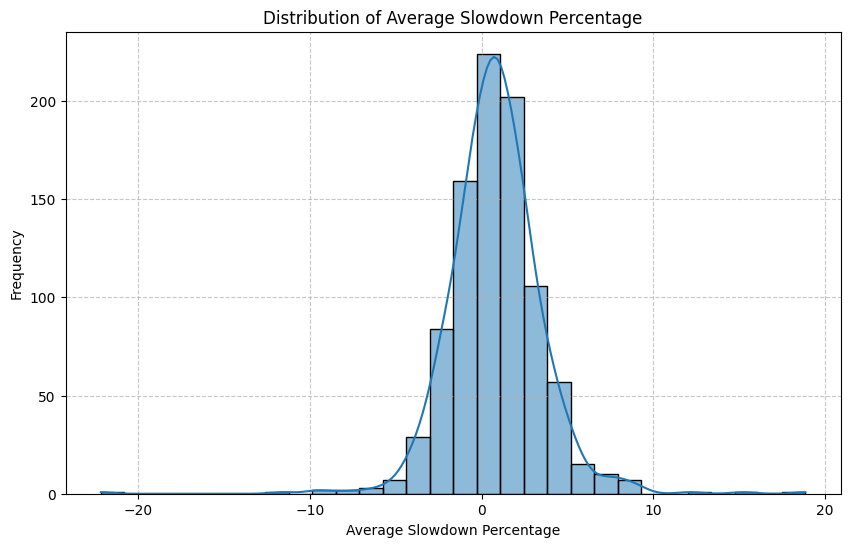

In [30]:
# Create a histogram for avg_slowdown_pct
plt.figure(figsize=(10, 6))
sns.histplot(priority_ranking_df['avg_slowdown_pct'], kde=True, bins=30)
plt.title('Distribution of Average Slowdown Percentage')
plt.xlabel('Average Slowdown Percentage')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

The histogram and KDE plot above show the distribution of slowdown percentages. We can observe the most frequent slowdown values and the overall shape of the distribution, which appears to be skewed right. This indicates that while many slowdowns are minor or even show speed improvements (negative values), there are also instances of significant slowdowns.

In [31]:
num_unique_segments = priority_ranking_df['segment_id'].nunique()
total_rows = len(priority_ranking_df)

print(f"Number of unique segment_ids: {num_unique_segments}")
print(f"Total number of rows in priority_ranking_df: {total_rows}")

if num_unique_segments == total_rows:
    print("There is exactly one row per segment_id in priority_ranking_df.")
else:
    print("There is NOT exactly one row per segment_id in priority_ranking_df.")

Number of unique segment_ids: 912
Total number of rows in priority_ranking_df: 912
There is exactly one row per segment_id in priority_ranking_df.


In [32]:
import numpy as np

conditions = [
    priority_ranking_df['avg_slowdown_pct'] <= 0,
    (priority_ranking_df['avg_slowdown_pct'] > 0) & (priority_ranking_df['avg_slowdown_pct'] <= 5),
    (priority_ranking_df['avg_slowdown_pct'] > 5) & (priority_ranking_df['avg_slowdown_pct'] <= 10),
    (priority_ranking_df['avg_slowdown_pct'] > 10) & (priority_ranking_df['avg_slowdown_pct'] <= 15),
    priority_ranking_df['avg_slowdown_pct'] > 15
]
choices = [0, 2.5, 5, 7.5, 10]

priority_ranking_df['Congestion_Severity_Multiplier'] = np.select(conditions, choices, default=0)

display(priority_ranking_df.head())

,segment_id,street,start_latitude,start_longitude,end_latitude,end_longitude,avg_slowdown_pct,significant_slowdown_pct,avg_slowdown_score,frequency_score,priority_score,priority_rank,segment_geo_length_m,Congestion_Severity_Multiplier
0,1058,Randolph,41.884599,-87.637069,41.884430,-87.647431,18.86,44.76,100.00,100.00,100.0,1,858.077819,10.0
1,586,Lake Shore Dr,41.873255,-87.617129,41.880917,-87.617304,15.25,39.44,91.20,88.11,90.0,2,852.022710,10.0
2,896,Lake Shore Dr,41.976597,-87.650651,41.969406,-87.648153,12.14,35.50,83.62,79.31,81.0,3,825.803010,7.5
3,926,Milwaukee,41.889020,-87.644133,41.896233,-87.655198,7.88,31.78,73.24,71.00,72.0,4,1217.464323,5.0
4,356,Western,41.910320,-87.687037,41.916804,-87.687205,8.43,25.11,74.58,56.10,65.0,5,721.183651,5.0


In [33]:
# Calculate the count and percentage for each Congestion Severity Multiplier
weight_distribution = priority_ranking_df['Congestion_Severity_Multiplier'].value_counts(normalize=False).reset_index()
weight_distribution.columns = ['Congestion_Severity_Multiplier', 'count']
weight_distribution['percentage'] = (priority_ranking_df['Congestion_Severity_Multiplier'].value_counts(normalize=True) * 100).reset_index(drop=True)
weight_distribution = weight_distribution.sort_values(by='Congestion_Severity_Multiplier').reset_index(drop=True)

display(weight_distribution)

,Congestion_Severity_Multiplier,count,percentage
0,0.0,326,35.745614
1,2.5,543,59.539474
2,5.0,40,4.385965
3,7.5,1,0.109649
4,10.0,2,0.219298


In [34]:
priority_ranking_df['segment_congestion_burden'] = priority_ranking_df['avg_slowdown_pct'] * priority_ranking_df['Congestion_Severity_Multiplier']
display(priority_ranking_df.head())

,segment_id,street,start_latitude,start_longitude,end_latitude,end_longitude,avg_slowdown_pct,significant_slowdown_pct,avg_slowdown_score,frequency_score,priority_score,priority_rank,segment_geo_length_m,Congestion_Severity_Multiplier,segment_congestion_burden
0,1058,Randolph,41.884599,-87.637069,41.884430,-87.647431,18.86,44.76,100.00,100.00,100.0,1,858.077819,10.0,188.60
1,586,Lake Shore Dr,41.873255,-87.617129,41.880917,-87.617304,15.25,39.44,91.20,88.11,90.0,2,852.022710,10.0,152.50
2,896,Lake Shore Dr,41.976597,-87.650651,41.969406,-87.648153,12.14,35.50,83.62,79.31,81.0,3,825.803010,7.5,91.05
3,926,Milwaukee,41.889020,-87.644133,41.896233,-87.655198,7.88,31.78,73.24,71.00,72.0,4,1217.464323,5.0,39.40
4,356,Western,41.910320,-87.687037,41.916804,-87.687205,8.43,25.11,74.58,56.10,65.0,5,721.183651,5.0,42.15


In [35]:
LSD_segments = priority_ranking_df[priority_ranking_df['street'] == 'Lake Shore Dr']
# Sort LSD_segments from north to south (higher latitude to lower latitude)
LSD_segments = LSD_segments.sort_values(by='start_latitude', ascending=False).reset_index(drop=True)
print("Segment IDs for LSD (sorted North to South):")
display(LSD_segments)

Segment IDs for LSD (sorted North to South):


,segment_id,street,start_latitude,start_longitude,end_latitude,end_longitude,avg_slowdown_pct,significant_slowdown_pct,avg_slowdown_score,frequency_score,priority_score,priority_rank,segment_geo_length_m,Congestion_Severity_Multiplier,segment_congestion_burden
0,896,Lake Shore Dr,41.976597,-87.650651,41.969406,-87.648153,12.14,35.50,83.62,79.31,81.0,3,825.803010,7.5,91.050
1,602,Lake Shore Dr,41.976595,-87.650283,41.985553,-87.653393,-2.30,0.71,48.43,1.59,25.0,864,1028.814081,0.0,-0.000
2,895,Lake Shore Dr,41.969406,-87.648153,41.962008,-87.646446,2.80,5.89,60.86,13.16,37.0,165,834.614347,2.5,7.000
3,601,Lake Shore Dr,41.969404,-87.647785,41.976595,-87.650283,7.80,22.92,73.04,51.21,62.0,7,825.803372,5.0,39.000
4,894,Lake Shore Dr,41.962008,-87.646446,41.954659,-87.644949,3.56,8.82,62.71,19.71,41.0,97,826.547789,2.5,8.900
5,600,Lake Shore Dr,41.962006,-87.646078,41.969404,-87.647785,0.46,1.14,55.15,2.55,29.0,656,834.614259,2.5,1.150
6,893,Lake Shore Dr,41.954659,-87.644949,41.948651,-87.643543,4.71,12.13,65.51,27.10,46.0,46,678.094266,2.5,11.775
7,599,Lake Shore Dr,41.954657,-87.644581,41.962006,-87.646078,0.95,1.87,56.35,4.18,30.0,569,826.547849,2.5,2.375
8,892,Lake Shore Dr,41.948651,-87.643543,41.940386,-87.638590,4.17,12.30,64.20,27.48,46.0,45,1006.127494,2.5,10.425
9,891,Lake Shore Dr,41.940386,-87.638590,41.933428,-87.632222,4.63,11.78,65.32,26.32,46.0,47,936.013809,2.5,11.575


In [36]:
from scipy.spatial import KDTree
import networkx as nx

def get_connected_components_by_street(df, coord_threshold=0.00001):
    all_components = []
    unique_streets = df['street'].unique()
    component_counter = 1

    for street_name in unique_streets:
        street_df = df[df['street'] == street_name].copy()

        # Collect all unique coordinates for the street
        coords = set()
        for _, row in street_df.iterrows():
            coords.add((row['start_latitude'], row['start_longitude']))
            coords.add((row['end_latitude'], row['end_longitude']))
        coords_list = list(coords)

        if not coords_list:
            continue

        # Use KDTree to find close coordinates and assign canonical IDs
        kdtree = KDTree(coords_list)
        # Map original coordinates to a canonical ID based on proximity
        canonical_coord_map = {}
        processed_indices = set()

        for i, coord in enumerate(coords_list):
            if i in processed_indices:
                continue

            neighbors_indices = kdtree.query_ball_point(coord, coord_threshold)
            # Use the first coordinate in the neighborhood as the canonical one
            canonical_coord = coords_list[neighbors_indices[0]]

            for idx in neighbors_indices:
                canonical_coord_map[coords_list[idx]] = canonical_coord
                processed_indices.add(idx)

        # Create a graph where nodes are segment_ids and edges connect segments sharing a canonical point
        graph = nx.Graph()
        for segment_id in street_df['segment_id'].unique():
            graph.add_node(segment_id)

        for _, row in street_df.iterrows():
            segment_id = row['segment_id']
            start_point = (row['start_latitude'], row['start_longitude'])
            end_point = (row['end_latitude'], row['end_longitude'])

            canonical_start = canonical_coord_map.get(start_point)
            canonical_end = canonical_coord_map.get(end_point)

            # Group segments by their canonical start and end points
            # Create temporary nodes for canonical points to link segments
            if canonical_start:
                graph.add_edge(segment_id, f'point_{canonical_start}')
            if canonical_end:
                graph.add_edge(segment_id, f'point_{canonical_end}')

        # Find connected components in the graph
        for component in nx.connected_components(graph):
            segment_ids_in_component = [
                node for node in component if isinstance(node, (int, float))
            ]

            if not segment_ids_in_component:
                continue

            # Get all original segments that belong to this component
            component_segments = street_df[street_df['segment_id'].isin(segment_ids_in_component)]

            # Determine the overall northernmost and southernmost points for the component
            component_start_latitude = component_segments['start_latitude'].max() # Northernmost
            component_start_longitude = component_segments[component_segments['start_latitude'] == component_start_latitude]['start_longitude'].iloc[0] # Corresponding longitude

            component_end_latitude = component_segments['end_latitude'].min() # Southernmost
            component_end_longitude = component_segments[component_segments['end_latitude'] == component_end_latitude]['end_longitude'].iloc[0] # Corresponding longitude

            all_components.append({
                'street': street_name,
                'component_number': f"{street_name}_{component_counter}",
                'segment_ids': sorted(list(segment_ids_in_component)),
                'num_segments_in_component': len(segment_ids_in_component),
                'component_start_latitude': component_start_latitude,
                'component_start_longitude': component_start_longitude,
                'component_end_latitude': component_end_latitude,
                'component_end_longitude': component_end_longitude
            })
            component_counter += 1

    return pd.DataFrame(all_components)


In [37]:
def get_connected_components_by_street(df, coord_threshold=0.00001):
    all_components = []
    unique_streets = df['street'].unique()
    component_counter = 1

    for street_name in unique_streets:
        # Ensure 'segment_geo_length_m' is available in the street_df
        if 'segment_geo_length_m' not in df.columns:
            raise ValueError("DataFrame must contain 'segment_geo_length_m' column.")

        street_df = df[df['street'] == street_name].copy()

        # Collect all unique coordinates for the street
        coords = set()
        for _, row in street_df.iterrows():
            coords.add((row['start_latitude'], row['start_longitude']))
            coords.add((row['end_latitude'], row['end_longitude']))
        coords_list = list(coords)

        if not coords_list:
            continue

        # Use KDTree to find close coordinates and assign canonical IDs
        kdtree = KDTree(coords_list)
        # Map original coordinates to a canonical ID based on proximity
        canonical_coord_map = {}
        processed_indices = set()

        for i, coord in enumerate(coords_list):
            if i in processed_indices:
                continue

            neighbors_indices = kdtree.query_ball_point(coord, coord_threshold)
            # Use the first coordinate in the neighborhood as the canonical one
            canonical_coord = coords_list[neighbors_indices[0]]

            for idx in neighbors_indices:
                canonical_coord_map[coords_list[idx]] = canonical_coord
                processed_indices.add(idx)

        # Create a graph where nodes are segment_ids and edges connect segments sharing a canonical point
        graph = nx.Graph()
        for segment_id in street_df['segment_id'].unique():
            graph.add_node(segment_id)

        for _, row in street_df.iterrows():
            segment_id = row['segment_id']
            start_point = (row['start_latitude'], row['start_longitude'])
            end_point = (row['end_latitude'], row['end_longitude'])

            canonical_start = canonical_coord_map.get(start_point)
            canonical_end = canonical_coord_map.get(end_point)

            # Group segments by their canonical start and end points
            # Create temporary nodes for canonical points to link segments
            if canonical_start:
                graph.add_edge(segment_id, f'point_{canonical_start}')
            if canonical_end:
                graph.add_edge(segment_id, f'point_{canonical_end}')

        # Find connected components in the graph
        for component in nx.connected_components(graph):
            segment_ids_in_component = [
                node for node in component if isinstance(node, (int, float)) # segment_id is int or float
            ]

            if not segment_ids_in_component:
                continue

            # Get all original segments that belong to this component
            component_segments = street_df[street_df['segment_id'].isin(segment_ids_in_component)]

            # Use the helper function to get network endpoints and total length
            (
                component_start_latitude,
                component_start_longitude,
                component_end_latitude,
                component_end_longitude,
                component_total_length_m
            ) = get_network_endpoints_and_length(component_segments, coord_threshold)

            all_components.append({
                'street': street_name,
                'component_number': f"{street_name}_{component_counter}",
                'segment_ids': sorted(list(segment_ids_in_component)),
                'num_segments_in_component': len(segment_ids_in_component),
                'component_start_latitude': component_start_latitude,
                'component_start_longitude': component_start_longitude,
                'component_end_latitude': component_end_latitude,
                'component_end_longitude': component_end_longitude,
                'component_total_length_m': component_total_length_m
            })
            component_counter += 1

    return pd.DataFrame(all_components)

In [38]:
def pair_bidirectional_components(components_df, coord_tolerance_m=50):
    paired_components = []

    for i in range(len(components_df)):
        comp1 = components_df.iloc[i]

        for j in range(i + 1, len(components_df)):
            comp2 = components_df.iloc[j]

            if comp1['street'] != comp2['street']:
                continue

            # Calculate Haversine distance between start points
            dist_start_to_start = haversine_distance(
                comp1['component_start_latitude'], comp1['component_start_longitude'],
                comp2['component_start_latitude'], comp2['component_start_longitude']
            )

            # Calculate Haversine distance between end points
            dist_end_to_end = haversine_distance(
                comp1['component_end_latitude'], comp1['component_end_longitude'],
                comp2['component_end_latitude'], comp2['component_end_longitude']
            )

            # Calculate midpoints for distance calculation
            comp1_mid_lat = (comp1['component_start_latitude'] + comp1['component_end_latitude']) / 2
            comp1_mid_lon = (comp1['component_start_longitude'] + comp1['component_end_longitude']) / 2
            comp2_mid_lat = (comp2['component_start_latitude'] + comp2['component_end_latitude']) / 2
            comp2_mid_lon = (comp2['component_start_longitude'] + comp2['component_end_longitude']) / 2

            dist_midpoint = haversine_distance(comp1_mid_lat, comp1_mid_lon, comp2_mid_lat, comp2_mid_lon)

            # Determine overall northernmost/westernmost start coordinates
            combined_start_lat = max(comp1['component_start_latitude'], comp2['component_start_latitude'])
            combined_start_lon = (comp1['component_start_longitude'] if combined_start_lat == comp1['component_start_latitude'] else comp2['component_start_longitude'])

            # Determine overall southernmost/easternmost end coordinates
            combined_end_lat = min(comp1['component_end_latitude'], comp2['component_end_latitude'])
            combined_end_lon = (comp1['component_end_longitude'] if combined_end_lat == comp1['component_end_latitude'] else comp2['component_end_longitude'])

            paired_components.append({
                'street': comp1['street'],
                'combined_component_name': f"{comp1['street']}_combined_{len(paired_components) + 1}",
                'directional_component_1_name': comp1['component_number'],
                'directional_component_1_segment_ids': comp1['segment_ids'],
                'directional_component_2_name': comp2['component_number'],
                'directional_component_2_segment_ids': comp2['segment_ids'],
                'combined_start_latitude': combined_start_lat,
                'combined_start_longitude': combined_start_lon,
                'combined_end_latitude': combined_end_lat,
                'combined_end_longitude': combined_end_lon,
                'num_segments_comp1': comp1['num_segments_in_component'],
                'num_segments_comp2': comp2['num_segments_in_component'],
                'dist_start_to_start_m': dist_start_to_start,
                'dist_end_to_end_m': dist_end_to_end,
                'dist_midpoint_m': dist_midpoint
            })

    return pd.DataFrame(paired_components)

In [39]:
# Regenerate components_table to ensure it's up-to-date
components_table = get_connected_components_by_street(priority_ranking_df)

# Generate the table of ALL possible paired bidirectional components without any filtering thresholds
paired_components_table = pair_bidirectional_components(components_table, coord_tolerance_m=0) # Set tolerance to 0 or remove it if function allows

# Recalculate metrics_df_final with all pairs and all requested metrics
# Component 1 details
paired_components_with_lengths = paired_components_table.merge(
    components_table[['component_number', 'component_start_latitude', 'component_start_longitude', 'component_end_latitude', 'component_end_longitude']],
    left_on='directional_component_1_name',
    right_on='component_number',
    suffixes=('_combined', '_comp1_original')
)

# Component 2 details
paired_components_with_lengths = paired_components_with_lengths.merge(
    components_table[['component_number', 'component_start_latitude', 'component_start_longitude', 'component_end_latitude', 'component_end_longitude']],
    left_on='directional_component_2_name',
    right_on='component_number',
    suffixes=('_comp1_original', '_comp2_original')
)

# Drop redundant component_number columns
paired_components_with_lengths = paired_components_with_lengths.drop(columns=['component_number_comp1_original', 'component_number_comp2_original'])

# Calculate geographic lengths and length ratio
calculated_final_metrics = []
for index, row in paired_components_with_lengths.iterrows():
    comp1_start_lat = row['component_start_latitude_comp1_original']
    comp1_start_lon = row['component_start_longitude_comp1_original']
    comp1_end_lat = row['component_end_latitude_comp1_original']
    comp1_end_lon = row['component_end_longitude_comp1_original']

    comp2_start_lat = row['component_start_latitude_comp2_original']
    comp2_start_lon = row['component_start_longitude_comp2_original']
    comp2_end_lat = row['component_end_latitude_comp2_original']
    comp2_end_lon = row['component_end_longitude_comp2_original']

    comp1_length = haversine_distance(comp1_start_lat, comp1_start_lon, comp1_end_lat, comp1_end_lon)
    comp2_length = haversine_distance(comp2_start_lat, comp2_start_lon, comp2_end_lat, comp2_end_lon)

    length_ratio = comp1_length / comp2_length if comp2_length != 0 else float('inf')
    length_ratio_discrepancy = abs(length_ratio - 1)

    calculated_final_metrics.append({
        'street': row['street'],
        'combined_component_name': row['combined_component_name'],
        'directional_component_1_name': row['directional_component_1_name'],
        'directional_component_2_name': row['directional_component_2_name'],
        'dist_start_to_start_m': row['dist_start_to_start_m'],
        'dist_end_to_end_m': row['dist_end_to_end_m'],
        'dist_midpoint_m': row['dist_midpoint_m'],
        'comp1_geographic_length_m': comp1_length,
        'comp2_geographic_length_m': comp2_length,
        'length_ratio_comp1_comp2': length_ratio,
        'length_ratio_discrepancy': length_ratio_discrepancy
    })

metrics_df_final = pd.DataFrame(calculated_final_metrics)

# Create the final table with specified columns and rename them
final_paired_metrics_table = metrics_df_final[[
    'street',
    'directional_component_1_name',
    'directional_component_2_name',
    'dist_start_to_start_m',
    'dist_end_to_end_m',
    'dist_midpoint_m',
    'comp1_geographic_length_m',
    'comp2_geographic_length_m',
    'length_ratio_comp1_comp2',
    'length_ratio_discrepancy'
]].copy()

final_paired_metrics_table.rename(columns={
    'directional_component_1_name': 'component 1',
    'directional_component_2_name': 'component 2',
    'dist_start_to_start_m': 'start distance',
    'dist_end_to_end_m': 'end distance',
    'dist_midpoint_m': 'midpoint distance',
    'comp1_geographic_length_m': 'component 1 geographic length',
    'comp2_geographic_length_m': 'component 2 geographic length',
    'length_ratio_comp1_comp2': 'length ratio',
    'length_ratio_discrepancy': 'length ratio discrepancy from 1.0'
}, inplace=True)

# Sort the table by street, then by length ratio discrepancy (closest to 1), and finally by midpoint distance
final_paired_metrics_table = final_paired_metrics_table.sort_values(
    by=['street', 'length ratio discrepancy from 1.0', 'midpoint distance'],
    ascending=[True, True, True]
)

# Display the first 50 rows
display(final_paired_metrics_table.head(50))

,street,component 1,component 2,start distance,end distance,midpoint distance,component 1 geographic length,component 2 geographic length,length ratio,length ratio discrepancy from 1.0
126,111th,111th_91,111th_92,918.645985,935.230313,926.742095,4446.449103,4427.865920,1.004197,4.196871e-03
125,111th,111th_90,111th_93,1633.262257,1616.471083,1624.866644,1616.834316,1633.642994,0.989711,1.028908e-02
124,111th,111th_90,111th_92,8470.796509,5659.776813,7065.280615,1616.834316,4427.865920,0.365150,6.348502e-01
123,111th,111th_90,111th_91,7554.817256,4725.202567,6140.013289,1616.834316,4446.449103,0.363624,6.363763e-01
128,111th,111th_92,111th_93,6837.720414,4043.632952,5440.650325,4427.865920,1633.642994,2.710424,1.710424e+00
127,111th,111th_91,111th_93,5922.073477,3109.426076,4515.726064,4446.449103,1633.642994,2.721800,1.721800e+00
94,55th,55th_55,55th_56,30.514197,30.514395,30.514294,4804.485453,4804.485540,1.000000,1.812627e-08
95,55th,55th_55,55th_57,5677.874352,3303.168492,4490.498786,4804.485453,2429.637590,1.977449,9.774494e-01
96,55th,55th_56,55th_57,5676.984065,3302.124924,4489.554159,4804.485540,2429.637590,1.977449,9.774495e-01
113,79th,79th_66,79th_67,30.514076,30.514628,30.514340,12904.763221,12904.763418,1.000000,1.531038e-08


In [40]:
# Generate components_table
components_table = get_connected_components_by_street(priority_ranking_df)
display(components_table.head())

,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528


In [41]:
print('Creating street_normalized in components_table...')
components_table['street_normalized'] = (
    components_table['street']
    .apply(normalize_street_name)
)
display(components_table.head())

Creating street_normalized in components_table...


,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE


In [42]:
components_table['street_normalized'] = (
    components_table['street']
    .apply(normalize_street_name)
)
display(components_table.head())

,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE


In [43]:
# Generate the table of paired bidirectional components
# Assuming components_table is defined elsewhere in the notebook context
# and haversine_distance function is also defined.
paired_components_table = pair_bidirectional_components(components_table, coord_tolerance_m=50)
display(paired_components_table)

,street,combined_component_name,directional_component_1_name,directional_component_1_segment_ids,directional_component_2_name,directional_component_2_segment_ids,combined_start_latitude,combined_start_longitude,combined_end_latitude,combined_end_longitude,num_segments_comp1,num_segments_comp2,dist_start_to_start_m,dist_end_to_end_m,dist_midpoint_m
0,Lake Shore Dr,Lake Shore Dr_combined_1,Lake Shore Dr_2,[587],Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",41.969406,-87.648153,41.880917,-87.617304,1,8,9870.087176,2637.704645,6252.180878
1,Lake Shore Dr,Lake Shore Dr_combined_2,Lake Shore Dr_2,[587],Lake Shore Dr_4,"[599, 600, 602]",41.985553,-87.653393,41.880917,-87.617304,1,3,11714.748613,8504.446883,10109.364598
2,Lake Shore Dr,Lake Shore Dr_combined_3,Lake Shore Dr_2,[587],Lake Shore Dr_5,"[579, 580, 581, 582]",41.884388,-87.613861,41.816935,-87.594690,1,4,2946.192698,7356.851455,5094.629705
3,Lake Shore Dr,Lake Shore Dr_combined_4,Lake Shore Dr_2,[587],Lake Shore Dr_6,[616],41.884390,-87.614229,41.880917,-87.617304,1,1,30.398719,30.399648,30.399183
4,Lake Shore Dr,Lake Shore Dr_combined_5,Lake Shore Dr_2,[587],Lake Shore Dr_7,"[604, 606]",41.884388,-87.613861,41.792419,-87.580485,1,2,8432.621889,10302.409740,9363.766681
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
126,111th,111th_combined_127,111th_91,"[485, 486, 487, 488, 490]",111th_92,"[479, 480, 481, 482, 483]",41.692901,-87.609854,41.692110,-87.652138,5,5,918.645985,935.230313,926.742095
127,111th,111th_combined_128,111th_91,"[485, 486, 487, 488, 490]",111th_93,[1116],41.692901,-87.609854,41.691431,-87.700829,5,1,5922.073477,3109.426076,4515.726064
128,111th,111th_combined_129,111th_92,"[479, 480, 481, 482, 483]",111th_93,[1116],41.692375,-87.598813,41.691431,-87.700829,5,1,6837.720414,4043.632952,5440.650325
129,Pershing,Pershing_combined_130,Pershing_95,[977],Pershing_96,"[969, 971]",41.823915,-87.630508,41.823390,-87.645952,1,2,1119.475890,22.238985,559.889910


In [44]:
# Merge paired_components_table with components_table to get full coordinates for each directional component

# Component 1 details
paired_components_with_lengths = paired_components_table.merge(
    components_table[['component_number', 'component_start_latitude', 'component_start_longitude', 'component_end_latitude', 'component_end_longitude']],
    left_on='directional_component_1_name',
    right_on='component_number',
    suffixes=('_combined', '_comp1_original')
)

# Component 2 details
paired_components_with_lengths = paired_components_with_lengths.merge(
    components_table[['component_number', 'component_start_latitude', 'component_start_longitude', 'component_end_latitude', 'component_end_longitude']],
    left_on='directional_component_2_name',
    right_on='component_number',
    suffixes=('_comp1_original', '_comp2_original')
)

# Drop redundant component_number columns
paired_components_with_lengths = paired_components_with_lengths.drop(columns=['component_number_comp1_original', 'component_number_comp2_original'])

# Calculate geographic lengths and length ratio
calculated_final_metrics = []
for index, row in paired_components_with_lengths.iterrows():
    comp1_start_lat = row['component_start_latitude_comp1_original']
    comp1_start_lon = row['component_start_longitude_comp1_original']
    comp1_end_lat = row['component_end_latitude_comp1_original']
    comp1_end_lon = row['component_end_longitude_comp1_original']

    comp2_start_lat = row['component_start_latitude_comp2_original']
    comp2_start_lon = row['component_start_longitude_comp2_original']
    comp2_end_lat = row['component_end_latitude_comp2_original']
    comp2_end_lon = row['component_end_longitude_comp2_original']

    comp1_length = haversine_distance(comp1_start_lat, comp1_start_lon, comp1_end_lat, comp1_end_lon)
    comp2_length = haversine_distance(comp2_start_lat, comp2_start_lon, comp2_end_lat, comp2_end_lon)

    length_ratio = comp1_length / comp2_length if comp2_length != 0 else float('inf')

    calculated_final_metrics.append({
        'street': row['street'],
        'combined_component_name': row['combined_component_name'],
        'directional_component_1_name': row['directional_component_1_name'],
        'directional_component_2_name': row['directional_component_2_name'],
        'dist_start_to_start_m': row['dist_start_to_start_m'],
        'dist_end_to_end_m': row['dist_end_to_end_m'],
        'dist_midpoint_m': row['dist_midpoint_m'],
        'comp1_geographic_length_m': comp1_length,
        'comp2_geographic_length_m': comp2_length,
        'length_ratio_comp1_comp2': length_ratio
    })

metrics_df_final = pd.DataFrame(calculated_final_metrics)
display(metrics_df_final)

,street,combined_component_name,directional_component_1_name,directional_component_2_name,dist_start_to_start_m,dist_end_to_end_m,dist_midpoint_m,comp1_geographic_length_m,comp2_geographic_length_m,length_ratio_comp1_comp2
0,Lake Shore Dr,Lake Shore Dr_combined_1,Lake Shore Dr_2,Lake Shore Dr_3,9870.087176,2637.704645,6252.180878,479.819194,7528.242570,0.063736
1,Lake Shore Dr,Lake Shore Dr_combined_2,Lake Shore Dr_2,Lake Shore Dr_4,11714.748613,8504.446883,10109.364598,479.819194,3511.958356,0.136624
2,Lake Shore Dr,Lake Shore Dr_combined_3,Lake Shore Dr_2,Lake Shore Dr_5,2946.192698,7356.851455,5094.629705,479.819194,4904.126704,0.097840
3,Lake Shore Dr,Lake Shore Dr_combined_4,Lake Shore Dr_2,Lake Shore Dr_6,30.398719,30.399648,30.399183,479.819194,479.819758,0.999999
4,Lake Shore Dr,Lake Shore Dr_combined_5,Lake Shore Dr_2,Lake Shore Dr_7,8432.621889,10302.409740,9363.766681,479.819194,2169.552881,0.221160
...,...,...,...,...,...,...,...,...,...,...
126,111th,111th_combined_127,111th_91,111th_92,918.645985,935.230313,926.742095,4446.449103,4427.865920,1.004197
127,111th,111th_combined_128,111th_91,111th_93,5922.073477,3109.426076,4515.726064,4446.449103,1633.642994,2.721800
128,111th,111th_combined_129,111th_92,111th_93,6837.720414,4043.632952,5440.650325,4427.865920,1633.642994,2.710424
129,Pershing,Pershing_combined_130,Pershing_95,Pershing_96,1119.475890,22.238985,559.889910,1280.204093,2399.786023,0.533466


In [45]:
# The haversine_distance function has been moved to an earlier cell.

In [46]:
# Merge paired_components_table with components_table to get full coordinates for each directional component

# Component 1 details
paired_components_with_lengths = paired_components_table.merge(
    components_table[['component_number', 'component_start_latitude', 'component_start_longitude', 'component_end_latitude', 'component_end_longitude']],
    left_on='directional_component_1_name',
    right_on='component_number',
    suffixes=('_combined', '_comp1_original')
)

# Component 2 details
paired_components_with_lengths = paired_components_with_lengths.merge(
    components_table[['component_number', 'component_start_latitude', 'component_start_longitude', 'component_end_latitude', 'component_end_longitude']],
    left_on='directional_component_2_name',
    right_on='component_number',
    suffixes=('_comp1_original', '_comp2_original')
)

# Drop redundant component_number columns
paired_components_with_lengths = paired_components_with_lengths.drop(columns=['component_number_comp1_original', 'component_number_comp2_original'])

# Calculate geographic lengths and length ratio
calculated_final_metrics = []
for index, row in paired_components_with_lengths.iterrows():
    comp1_start_lat = row['component_start_latitude_comp1_original']
    comp1_start_lon = row['component_start_longitude_comp1_original']
    comp1_end_lat = row['component_end_latitude_comp1_original']
    comp1_end_lon = row['component_end_longitude_comp1_original']

    comp2_start_lat = row['component_start_latitude_comp2_original']
    comp2_start_lon = row['component_start_longitude_comp2_original']
    comp2_end_lat = row['component_end_latitude_comp2_original']
    comp2_end_lon = row['component_end_longitude_comp2_original']

    comp1_length = haversine_distance(comp1_start_lat, comp1_start_lon, comp1_end_lat, comp1_end_lon)
    comp2_length = haversine_distance(comp2_start_lat, comp2_start_lon, comp2_end_lat, comp2_end_lon)

    length_ratio = comp1_length / comp2_length if comp2_length != 0 else float('inf')
    length_ratio_discrepancy = abs(length_ratio - 1)

    calculated_final_metrics.append({
        'street': row['street'],
        'combined_component_name': row['combined_component_name'],
        'directional_component_1_name': row['directional_component_1_name'],
        'directional_component_2_name': row['directional_component_2_name'],
        'dist_start_to_start_m': row['dist_start_to_start_m'],
        'dist_end_to_end_m': row['dist_end_to_end_m'],
        'dist_midpoint_m': row['dist_midpoint_m'],
        'comp1_geographic_length_m': comp1_length,
        'comp2_geographic_length_m': comp2_length,
        'length_ratio_comp1_comp2': length_ratio,
        'length_ratio_discrepancy': length_ratio_discrepancy
    })

metrics_df_final = pd.DataFrame(calculated_final_metrics)
display(metrics_df_final)

,street,combined_component_name,directional_component_1_name,directional_component_2_name,dist_start_to_start_m,dist_end_to_end_m,dist_midpoint_m,comp1_geographic_length_m,comp2_geographic_length_m,length_ratio_comp1_comp2,length_ratio_discrepancy
0,Lake Shore Dr,Lake Shore Dr_combined_1,Lake Shore Dr_2,Lake Shore Dr_3,9870.087176,2637.704645,6252.180878,479.819194,7528.242570,0.063736,0.936264
1,Lake Shore Dr,Lake Shore Dr_combined_2,Lake Shore Dr_2,Lake Shore Dr_4,11714.748613,8504.446883,10109.364598,479.819194,3511.958356,0.136624,0.863376
2,Lake Shore Dr,Lake Shore Dr_combined_3,Lake Shore Dr_2,Lake Shore Dr_5,2946.192698,7356.851455,5094.629705,479.819194,4904.126704,0.097840,0.902160
3,Lake Shore Dr,Lake Shore Dr_combined_4,Lake Shore Dr_2,Lake Shore Dr_6,30.398719,30.399648,30.399183,479.819194,479.819758,0.999999,0.000001
4,Lake Shore Dr,Lake Shore Dr_combined_5,Lake Shore Dr_2,Lake Shore Dr_7,8432.621889,10302.409740,9363.766681,479.819194,2169.552881,0.221160,0.778840
...,...,...,...,...,...,...,...,...,...,...,...
126,111th,111th_combined_127,111th_91,111th_92,918.645985,935.230313,926.742095,4446.449103,4427.865920,1.004197,0.004197
127,111th,111th_combined_128,111th_91,111th_93,5922.073477,3109.426076,4515.726064,4446.449103,1633.642994,2.721800,1.721800
128,111th,111th_combined_129,111th_92,111th_93,6837.720414,4043.632952,5440.650325,4427.865920,1633.642994,2.710424,1.710424
129,Pershing,Pershing_combined_130,Pershing_95,Pershing_96,1119.475890,22.238985,559.889910,1280.204093,2399.786023,0.533466,0.466534


In [47]:
# Regenerate components_table to ensure it's up-to-date
components_table = get_connected_components_by_street(priority_ranking_df)

# Generate the table of ALL possible paired bidirectional components without any filtering thresholds
paired_components_table = pair_bidirectional_components(components_table, coord_tolerance_m=0) # Set tolerance to 0 or remove it if function allows

# Recalculate metrics_df_final with all pairs and all requested metrics
# Component 1 details
paired_components_with_lengths = paired_components_table.merge(
    components_table[['component_number', 'component_start_latitude', 'component_start_longitude', 'component_end_latitude', 'component_end_longitude']],
    left_on='directional_component_1_name',
    right_on='component_number',
    suffixes=('_combined', '_comp1_original')
)

# Component 2 details
paired_components_with_lengths = paired_components_with_lengths.merge(
    components_table[['component_number', 'component_start_latitude', 'component_start_longitude', 'component_end_latitude', 'component_end_longitude']],
    left_on='directional_component_2_name',
    right_on='component_number',
    suffixes=('_comp1_original', '_comp2_original')
)

# Drop redundant component_number columns
paired_components_with_lengths = paired_components_with_lengths.drop(columns=['component_number_comp1_original', 'component_number_comp2_original'])

# Calculate geographic lengths and length ratio
calculated_final_metrics = []
for index, row in paired_components_with_lengths.iterrows():
    comp1_start_lat = row['component_start_latitude_comp1_original']
    comp1_start_lon = row['component_start_longitude_comp1_original']
    comp1_end_lat = row['component_end_latitude_comp1_original']
    comp1_end_lon = row['component_end_longitude_comp1_original']

    comp2_start_lat = row['component_start_latitude_comp2_original']
    comp2_start_lon = row['component_start_longitude_comp2_original']
    comp2_end_lat = row['component_end_latitude_comp2_original']
    comp2_end_lon = row['component_end_longitude_comp2_original']

    comp1_length = haversine_distance(comp1_start_lat, comp1_start_lon, comp1_end_lat, comp1_end_lon)
    comp2_length = haversine_distance(comp2_start_lat, comp2_start_lon, comp2_end_lat, comp2_end_lon)

    length_ratio = comp1_length / comp2_length if comp2_length != 0 else float('inf')
    length_ratio_discrepancy = abs(length_ratio - 1)

    calculated_final_metrics.append({
        'street': row['street'],
        'combined_component_name': row['combined_component_name'],
        'directional_component_1_name': row['directional_component_1_name'],
        'directional_component_2_name': row['directional_component_2_name'],
        'dist_start_to_start_m': row['dist_start_to_start_m'],
        'dist_end_to_end_m': row['dist_end_to_end_m'],
        'dist_midpoint_m': row['dist_midpoint_m'],
        'comp1_geographic_length_m': comp1_length,
        'comp2_geographic_length_m': comp2_length,
        'length_ratio_comp1_comp2': length_ratio,
        'length_ratio_discrepancy': length_ratio_discrepancy
    })

metrics_df_final = pd.DataFrame(calculated_final_metrics)

# Create the final table with specified columns and rename them
final_paired_metrics_table = metrics_df_final[[
    'street',
    'directional_component_1_name',
    'directional_component_2_name',
    'dist_start_to_start_m',
    'dist_end_to_end_m',
    'dist_midpoint_m',
    'comp1_geographic_length_m',
    'comp2_geographic_length_m',
    'length_ratio_comp1_comp2',
    'length_ratio_discrepancy'
]].copy()

final_paired_metrics_table.rename(columns={
    'directional_component_1_name': 'component 1',
    'directional_component_2_name': 'component 2',
    'dist_start_to_start_m': 'start distance',
    'dist_end_to_end_m': 'end distance',
    'dist_midpoint_m': 'midpoint distance',
    'comp1_geographic_length_m': 'component 1 geographic length',
    'comp2_geographic_length_m': 'component 2 geographic length',
    'length_ratio_comp1_comp2': 'length ratio',
    'length_ratio_discrepancy': 'length ratio discrepancy from 1.0'
}, inplace=True)

# Sort the table by street, then by length ratio discrepancy (closest to 1), and finally by midpoint distance
final_paired_metrics_table = final_paired_metrics_table.sort_values(
    by=['street', 'length ratio discrepancy from 1.0', 'midpoint distance'],
    ascending=[True, True, True]
)

# Display the first 50 rows
display(final_paired_metrics_table.head(50))

,street,component 1,component 2,start distance,end distance,midpoint distance,component 1 geographic length,component 2 geographic length,length ratio,length ratio discrepancy from 1.0
126,111th,111th_91,111th_92,918.645985,935.230313,926.742095,4446.449103,4427.865920,1.004197,4.196871e-03
125,111th,111th_90,111th_93,1633.262257,1616.471083,1624.866644,1616.834316,1633.642994,0.989711,1.028908e-02
124,111th,111th_90,111th_92,8470.796509,5659.776813,7065.280615,1616.834316,4427.865920,0.365150,6.348502e-01
123,111th,111th_90,111th_91,7554.817256,4725.202567,6140.013289,1616.834316,4446.449103,0.363624,6.363763e-01
128,111th,111th_92,111th_93,6837.720414,4043.632952,5440.650325,4427.865920,1633.642994,2.710424,1.710424e+00
127,111th,111th_91,111th_93,5922.073477,3109.426076,4515.726064,4446.449103,1633.642994,2.721800,1.721800e+00
94,55th,55th_55,55th_56,30.514197,30.514395,30.514294,4804.485453,4804.485540,1.000000,1.812627e-08
95,55th,55th_55,55th_57,5677.874352,3303.168492,4490.498786,4804.485453,2429.637590,1.977449,9.774494e-01
96,55th,55th_56,55th_57,5676.984065,3302.124924,4489.554159,4804.485540,2429.637590,1.977449,9.774495e-01
113,79th,79th_66,79th_67,30.514076,30.514628,30.514340,12904.763221,12904.763418,1.000000,1.531038e-08


### Analysis of Bidirectional Pairs

In [48]:

# 1. Number of candidate bidirectional pairs
num_paired_components = len(metrics_df_final)
print(f"Number of candidate bidirectional pairs: {num_paired_components}")

Number of candidate bidirectional pairs: 131


### Distribution of Start-to-Start Distance

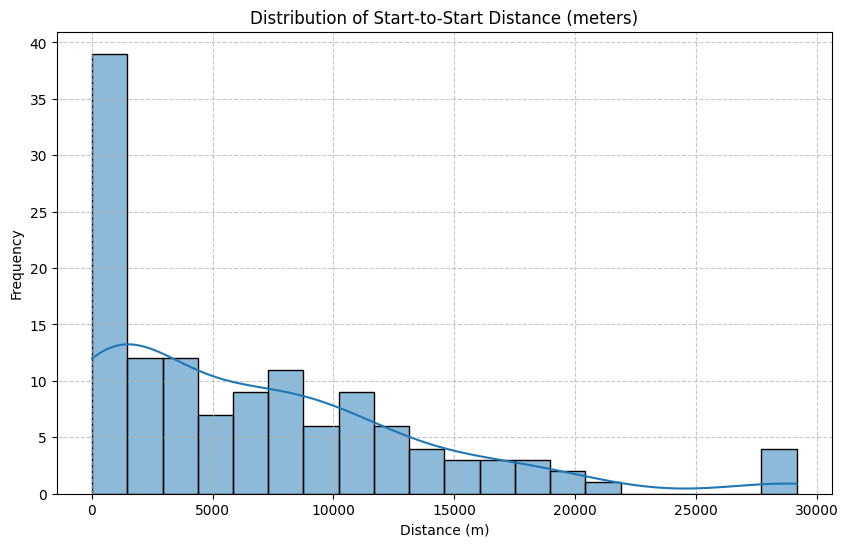

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(metrics_df_final['dist_start_to_start_m'], kde=True, bins=20)
plt.title('Distribution of Start-to-Start Distance (meters)')
plt.xlabel('Distance (m)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of End-to-End Distance

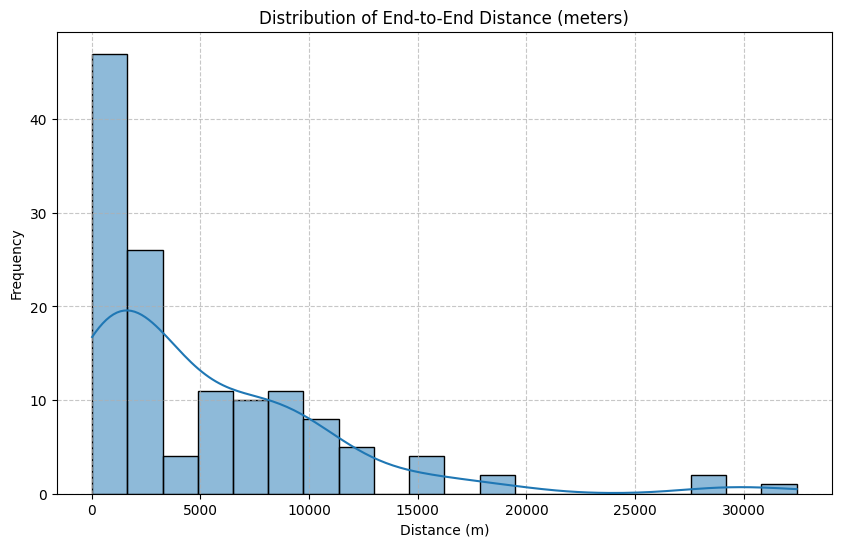

In [50]:
plt.figure(figsize=(10, 6))
sns.histplot(metrics_df_final['dist_end_to_end_m'], kde=True, bins=20)
plt.title('Distribution of End-to-End Distance (meters)')
plt.xlabel('Distance (m)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of Length Ratio

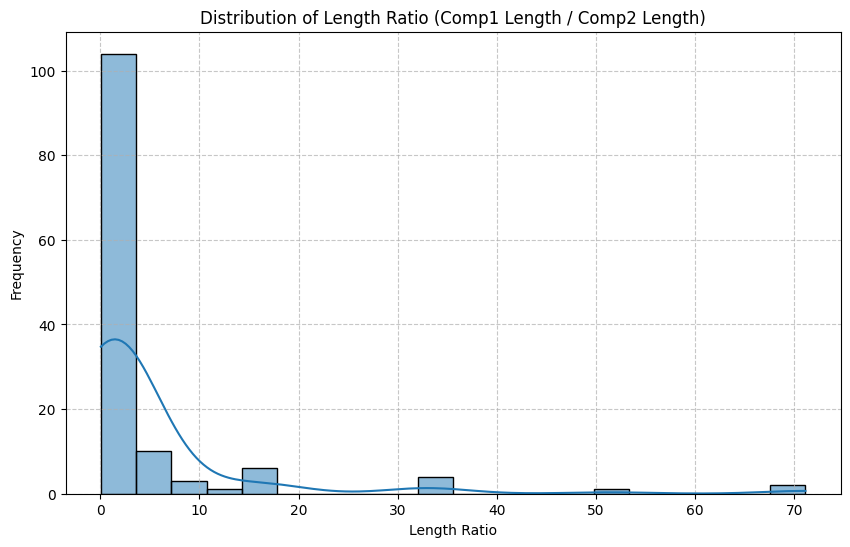

In [51]:
plt.figure(figsize=(10, 6))
sns.histplot(metrics_df_final['length_ratio_comp1_comp2'], kde=True, bins=20)
plt.title('Distribution of Length Ratio (Comp1 Length / Comp2 Length)')
plt.xlabel('Length Ratio')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Top 10 Pairs with Largest Endpoint Distance

In [52]:
# Calculate the maximum endpoint distance for each pair
metrics_df_final['max_endpoint_dist'] = metrics_df_final[['dist_start_to_start_m', 'dist_end_to_end_m']].max(axis=1)

# Sort by max_endpoint_dist in descending order and display the top 10
largest_endpoint_dist_pairs = metrics_df_final.sort_values(by='max_endpoint_dist', ascending=False).head(10)
display(largest_endpoint_dist_pairs[['street', 'directional_component_1_name', 'directional_component_2_name', 'dist_start_to_start_m', 'dist_end_to_end_m', 'max_endpoint_dist']])

,street,directional_component_1_name,directional_component_2_name,dist_start_to_start_m,dist_end_to_end_m,max_endpoint_dist
52,Pulaski,Pulaski_24,Pulaski_25,171.950200,32426.298029,32426.298029
42,Western,Western_15,Western_16,29169.522015,3243.499274,29169.522015
40,Western,Western_14,Western_16,29168.670913,3242.794976,29168.670913
57,Ashland,Ashland_29,Ashland_31,3610.090171,29168.038221,29168.038221
58,Ashland,Ashland_30,Ashland_31,3609.521206,29167.201948,29167.201948
43,Western,Western_15,Western_17,28358.751364,2433.595441,28358.751364
41,Western,Western_14,Western_17,28357.869046,2432.607249,28357.869046
20,Lake Shore Dr,Lake Shore Dr_4,Lake Shore Dr_10,21183.720429,18813.263971,21183.720429
17,Lake Shore Dr,Lake Shore Dr_4,Lake Shore Dr_7,20143.696436,18804.416436,20143.696436
14,Lake Shore Dr,Lake Shore Dr_3,Lake Shore Dr_10,19339.115633,12944.126162,19339.115633


### Top 10 Pairs with Largest Length-Ratio Discrepancy

In [53]:
# Calculate the absolute difference from a 1:1 length ratio
metrics_df_final['length_ratio_discrepancy'] = abs(metrics_df_final['length_ratio_comp1_comp2'] - 1)

# Sort by length_ratio_discrepancy in descending order and display the top 10
largest_length_ratio_discrepancy_pairs = metrics_df_final.sort_values(by='length_ratio_discrepancy', ascending=False).head(10)
display(largest_length_ratio_discrepancy_pairs[['street', 'directional_component_1_name', 'directional_component_2_name', 'length_ratio_comp1_comp2', 'length_ratio_discrepancy']])

,street,directional_component_1_name,directional_component_2_name,length_ratio_comp1_comp2,length_ratio_discrepancy
58,Ashland,Ashland_30,Ashland_31,71.116488,70.116488
57,Ashland,Ashland_29,Ashland_31,71.116485,70.116485
52,Pulaski,Pulaski_24,Pulaski_25,51.349963,50.349963
42,Western,Western_15,Western_16,32.971739,31.971739
40,Western,Western_14,Western_16,32.971737,31.971737
43,Western,Western_15,Western_17,32.941350,31.941350
41,Western,Western_14,Western_17,32.941349,31.941349
49,Archer,Archer_21,Archer_22,17.171080,16.171080
47,Archer,Archer_20,Archer_22,17.171079,16.171079
50,Archer,Archer_21,Archer_23,16.820749,15.820749


In [54]:
final_paired_metrics_table = metrics_df_final[[
    'street',
    'directional_component_1_name',
    'directional_component_2_name',
    'dist_start_to_start_m',
    'dist_end_to_end_m',
    'dist_midpoint_m',
    'length_ratio_comp1_comp2',
    'length_ratio_discrepancy' # Use this for sorting by closest to 1
]].copy()

final_paired_metrics_table.rename(columns={
    'directional_component_1_name': 'component 1',
    'directional_component_2_name': 'component 2',
    'dist_start_to_start_m': 'start distance',
    'dist_end_to_end_m': 'end distance',
    'dist_midpoint_m': 'midpoint distance',
    'length_ratio_comp1_comp2': 'length ratio'
}, inplace=True)

# Sort the table
final_paired_metrics_table = final_paired_metrics_table.sort_values(
    by=['street', 'length_ratio_discrepancy', 'midpoint distance'],
    ascending=[True, True, True]
)

# Drop the temporary sorting column and display the top 50 candidates
display(final_paired_metrics_table.drop(columns=['length_ratio_discrepancy']).head(50))

,street,component 1,component 2,start distance,end distance,midpoint distance,length ratio
126,111th,111th_91,111th_92,918.645985,935.230313,926.742095,1.004197
125,111th,111th_90,111th_93,1633.262257,1616.471083,1624.866644,0.989711
124,111th,111th_90,111th_92,8470.796509,5659.776813,7065.280615,0.365150
123,111th,111th_90,111th_91,7554.817256,4725.202567,6140.013289,0.363624
128,111th,111th_92,111th_93,6837.720414,4043.632952,5440.650325,2.710424
127,111th,111th_91,111th_93,5922.073477,3109.426076,4515.726064,2.721800
94,55th,55th_55,55th_56,30.514197,30.514395,30.514294,1.000000
95,55th,55th_55,55th_57,5677.874352,3303.168492,4490.498786,1.977449
96,55th,55th_56,55th_57,5676.984065,3302.124924,4489.554159,1.977449
113,79th,79th_66,79th_67,30.514076,30.514628,30.514340,1.000000


In [55]:
import folium

# Get the mean coordinates to center the map (approximate center of LSD segments)
center_lat = LSD_segments['start_latitude'].mean()
center_lon = LSD_segments['start_longitude'].mean()

# Create a Folium map centered around the approximate center of Lake Shore Drive
m = folium.Map(location=[center_lat, center_lon], zoom_start=12)

# Iterate through each segment in LSD_segments and add a polyline to the map
for index, row in LSD_segments.iterrows():
    start_coords = (row['start_latitude'], row['start_longitude'])
    end_coords = (row['end_latitude'], row['end_longitude'])

    # Add a line for the segment
    folium.PolyLine(
        locations=[start_coords, end_coords],
        color='blue',
        weight=5,
        opacity=0.7,
        tooltip=f"Segment ID: {row['segment_id']}, Street: {row['street']}"
    ).add_to(m)

# Display the map
display(m)

In [56]:
crash_url = "https://data.cityofchicago.org/api/v3/views/85ca-t3if/query.json"
street_center_url = "https://data.cityofchicago.org/api/v3/views/pr57-gg9e/query.json"
bus_routes_url = "https://data.cityofchicago.org/api/v3/views/6uva-a5ei/query.json"
CTA_ridership_url = "https://data.cityofchicago.org/api/v3/views/bynn-gwxy/query.json"

In [57]:
crash_df = pd.read_json(crash_url)[['crash_record_id', 'crash_date', 'street_name', 'latitude', 'longitude', 'most_severe_injury']]

In [58]:
print('Creating street_normalized in crash_df...')
crash_df['street_normalized'] = crash_df['street_name'].apply(normalize_street_name)
display(crash_df.head())

Creating street_normalized in crash_df...


,crash_record_id,crash_date,street_name,latitude,longitude,most_severe_injury,street_normalized
0,000d36adce8b4b793e9d0c5cd09dfed2e71309972d3437...,2026-08-20T13:29:00.000,53RD ST,41.799621,-87.591827,NO INDICATION OF INJURY,53RD
1,00cf9d4df2f160489077e6e8099032c366fe1da9a5be9a...,2026-09-12T14:10:00.000,BELMONT AVE,41.938402,-87.771294,NO INDICATION OF INJURY,BELMONT
2,419e0f4348b4274d902d84bd7aa58f5fa9c10820b77abc...,2026-05-19T23:15:00.000,LAKE SHORE DR,41.781882,-87.575497,NO INDICATION OF INJURY,LAKE SHORE
3,1471094d2f2a497653584d887ed73cddcdfaa35fd02b20...,2026-05-20T07:51:00.000,NOBLE ST,41.894349,-87.662208,NONINCAPACITATING INJURY,NOBLE
4,1c99690e19bd557cc6ad0674668dc492ab979c4e63a279...,2026-05-20T02:00:00.000,75TH ST,41.759085,-87.567448,NO INDICATION OF INJURY,75TH


In [59]:
street_center_df = pd.read_json(street_center_url)
street_center_df.info()

street_center_df.describe()
street_center_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56338 entries, 0 to 56337
Data columns (total 54 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   :id          56338 non-null  object             
 1   :version     56338 non-null  object             
 2   :created_at  56338 non-null  datetime64[ns, UTC]
 3   :updated_at  56338 non-null  datetime64[ns, UTC]
 4   fnode_id     56338 non-null  int64              
 5   tnode_id     56338 non-null  int64              
 6   the_geom     56338 non-null  object             
 7   objectid     56338 non-null  int64              
 8   trans_id     56338 non-null  int64              
 9   pre_dir      56002 non-null  object             
 10  street_nam   56002 non-null  object             
 11  street_typ   55198 non-null  object             
 12  streetname   56338 non-null  int64              
 13  l_f_add      56338 non-null  int64              
 14  l_t_add      56338 non

,:id,:version,:created_at,:updated_at,fnode_id,tnode_id,the_geom,objectid,trans_id,pre_dir,...,ewns_dir,ewns_coord,create_use,create_tim,update_use,update_tim,shape_len,edit_type,suf_dir,flag_strin
0,row-6rf7.9kwz.azc9,rv-zh7v.gmj7.z5rf,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,10809,16581,"{'type': 'MultiLineString', 'coordinates': [[[...",510,127104,S,...,W,232,EXISTING,1999-01-01T00:00:00.000Z,EXISTING,1999-01-01T00:00:00.000Z,220.566012,NaN,NaN,NaN
1,row-dvfu_zvgd.q9cw,rv-8qtr_8cuz_cupi,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,6501,34082,"{'type': 'MultiLineString', 'coordinates': [[[...",511,128895,S,...,NaN,0,EXISTING,1999-01-01T00:00:00.000Z,EXISTING,1999-01-01T00:00:00.000Z,664.774607,NaN,NaN,NaN
2,row-6xpa~w8sg-543u,rv-jgs6.n5wm.hrtt,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,15338,22358,"{'type': 'MultiLineString', 'coordinates': [[[...",512,142645,S,...,W,2500,EXISTING,1999-01-01T00:00:00.000Z,EXISTING,1999-01-01T00:00:00.000Z,665.378453,NaN,NaN,NaN
3,row-vgcw-gjsk_eiai,rv-hpki_n3pa_ry4q,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,15799,28881,"{'type': 'MultiLineString', 'coordinates': [[[...",513,148189,S,...,W,932,EXISTING,1999-01-01T00:00:00.000Z,EXISTING,1999-01-01T00:00:00.000Z,152.564966,NaN,NaN,NaN
4,row-nxmr~7m97~fbdb,rv-yvup_7yk7~3hu5,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,36407,36534,"{'type': 'MultiLineString', 'coordinates': [[[...",514,139728,W,...,S,11800,EXISTING,1999-01-01T00:00:00.000Z,EXISTING,1999-01-01T00:00:00.000Z,332.691382,NaN,NaN,NaN


In [60]:
print('Columns in street_center_df:')
print(street_center_df.columns.tolist())

Columns in street_center_df:
[':id', ':version', ':created_at', ':updated_at', 'fnode_id', 'tnode_id', 'the_geom', 'objectid', 'trans_id', 'pre_dir', 'street_nam', 'street_typ', 'streetname', 'l_f_add', 'l_t_add', 'r_f_add', 'r_t_add', 'logiclf', 'logiclt', 'logicrf', 'logicrt', 'class', 'status', 'status_dat', 'tiered', 'oneway_dir', 'dir_travel', 'ewns', 'l_parity', 'r_parity', 'f_zlev', 't_zlev', 'l_fips', 'r_fips', 'r_zip', 'l_zip', 'r_censusbl', 'l_censusbl', 'f_cross', 'f_cross_st', 't_cross', 't_cross_st', 'length', 'edit_date', 'ewns_dir', 'ewns_coord', 'create_use', 'create_tim', 'update_use', 'update_tim', 'shape_len', 'edit_type', 'suf_dir', 'flag_strin']


Now, let's match the `crash_df` with `components_table` using the normalized street names.

In [61]:
print('Creating street_normalized in components_table before merge...')
components_table['street_normalized'] = components_table['street'].apply(normalize_street_name)
display(components_table.head())

Creating street_normalized in components_table before merge...


,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE


In [62]:
# Perform a left merge to see which crashes occur on streets present in components_table
merged_crashes_with_components = pd.merge(
    crash_df,
    components_table[['street_normalized']].drop_duplicates(),
    on='street_normalized',
    how='left',
    indicator=True
)

# Count crashes that matched with a street in components_table
matched_crashes = merged_crashes_with_components[merged_crashes_with_components['_merge'] == 'both']
num_matched_crashes = len(matched_crashes)

# Count crashes that did not match
num_unmatched_crashes = len(merged_crashes_with_components) - num_matched_crashes

print(f"Number of crashes on streets present in components_table: {num_matched_crashes}")
print(f"Number of crashes on streets NOT present in components_table: {num_unmatched_crashes}")
print(f"Total crashes: {len(merged_crashes_with_components)}")

# Display a sample of the merged dataframe
display(merged_crashes_with_components.head())

Number of crashes on streets present in components_table: 349571
Number of crashes on streets NOT present in components_table: 754704
Total crashes: 1104275


,crash_record_id,crash_date,street_name,latitude,longitude,most_severe_injury,street_normalized,_merge
0,000d36adce8b4b793e9d0c5cd09dfed2e71309972d3437...,2026-08-20T13:29:00.000,53RD ST,41.799621,-87.591827,NO INDICATION OF INJURY,53RD,left_only
1,00cf9d4df2f160489077e6e8099032c366fe1da9a5be9a...,2026-09-12T14:10:00.000,BELMONT AVE,41.938402,-87.771294,NO INDICATION OF INJURY,BELMONT,left_only
2,419e0f4348b4274d902d84bd7aa58f5fa9c10820b77abc...,2026-05-19T23:15:00.000,LAKE SHORE DR,41.781882,-87.575497,NO INDICATION OF INJURY,LAKE SHORE,both
3,1471094d2f2a497653584d887ed73cddcdfaa35fd02b20...,2026-05-20T07:51:00.000,NOBLE ST,41.894349,-87.662208,NONINCAPACITATING INJURY,NOBLE,left_only
4,1c99690e19bd557cc6ad0674668dc492ab979c4e63a279...,2026-05-20T02:00:00.000,75TH ST,41.759085,-87.567448,NO INDICATION OF INJURY,75TH,left_only


In [63]:
print('Re-attempting merge operation...')
# Perform a left merge to see which crashes occur on streets present in components_table
merged_crashes_with_components = pd.merge(
    crash_df,
    components_table[['street_normalized']].drop_duplicates(),
    on='street_normalized',
    how='left',
    indicator=True
)

# Count crashes that matched with a street in components_table
matched_crashes = merged_crashes_with_components[merged_crashes_with_components['_merge'] == 'both']
num_matched_crashes = len(matched_crashes)

# Count crashes that did not match
num_unmatched_crashes = len(merged_crashes_with_components) - num_matched_crashes

print(f"Number of crashes on streets present in components_table: {num_matched_crashes}")
print(f"Number of crashes on streets NOT present in components_table: {num_unmatched_crashes}")
print(f"Total crashes: {len(merged_crashes_with_components)}")

# Display a sample of the merged dataframe
display(merged_crashes_with_components.head())

Re-attempting merge operation...
Number of crashes on streets present in components_table: 349571
Number of crashes on streets NOT present in components_table: 754704
Total crashes: 1104275


,crash_record_id,crash_date,street_name,latitude,longitude,most_severe_injury,street_normalized,_merge
0,000d36adce8b4b793e9d0c5cd09dfed2e71309972d3437...,2026-08-20T13:29:00.000,53RD ST,41.799621,-87.591827,NO INDICATION OF INJURY,53RD,left_only
1,00cf9d4df2f160489077e6e8099032c366fe1da9a5be9a...,2026-09-12T14:10:00.000,BELMONT AVE,41.938402,-87.771294,NO INDICATION OF INJURY,BELMONT,left_only
2,419e0f4348b4274d902d84bd7aa58f5fa9c10820b77abc...,2026-05-19T23:15:00.000,LAKE SHORE DR,41.781882,-87.575497,NO INDICATION OF INJURY,LAKE SHORE,both
3,1471094d2f2a497653584d887ed73cddcdfaa35fd02b20...,2026-05-20T07:51:00.000,NOBLE ST,41.894349,-87.662208,NONINCAPACITATING INJURY,NOBLE,left_only
4,1c99690e19bd557cc6ad0674668dc492ab979c4e63a279...,2026-05-20T02:00:00.000,75TH ST,41.759085,-87.567448,NO INDICATION OF INJURY,75TH,left_only


In [64]:
# This cell is re-executed to attempt the merge again


In [65]:
print("Columns in priority_ranking_df:")
print(priority_ranking_df.columns.tolist())
print("\nColumns in street_center_df:")
print(street_center_df.columns.tolist())

Columns in priority_ranking_df:
['segment_id', 'street', 'start_latitude', 'start_longitude', 'end_latitude', 'end_longitude', 'avg_slowdown_pct', 'significant_slowdown_pct', 'avg_slowdown_score', 'frequency_score', 'priority_score', 'priority_rank', 'segment_geo_length_m', 'Congestion_Severity_Multiplier', 'segment_congestion_burden']

Columns in street_center_df:
[':id', ':version', ':created_at', ':updated_at', 'fnode_id', 'tnode_id', 'the_geom', 'objectid', 'trans_id', 'pre_dir', 'street_nam', 'street_typ', 'streetname', 'l_f_add', 'l_t_add', 'r_f_add', 'r_t_add', 'logiclf', 'logiclt', 'logicrf', 'logicrt', 'class', 'status', 'status_dat', 'tiered', 'oneway_dir', 'dir_travel', 'ewns', 'l_parity', 'r_parity', 'f_zlev', 't_zlev', 'l_fips', 'r_fips', 'r_zip', 'l_zip', 'r_censusbl', 'l_censusbl', 'f_cross', 'f_cross_st', 't_cross', 't_cross_st', 'length', 'edit_date', 'ewns_dir', 'ewns_coord', 'create_use', 'create_tim', 'update_use', 'update_tim', 'shape_len', 'edit_type', 'suf_dir', 

### Calculate 'Pairing score'

In [66]:
# Calculate max_endpoint_dist as the maximum of start-to-start and end-to-end distances
metrics_df_final['max_endpoint_dist'] = metrics_df_final[['dist_start_to_start_m', 'dist_end_to_end_m']].max(axis=1)

# Calculate Length Similarity: if ratio > 1.0, use 1.0 / ratio, else use ratio
metrics_df_final['length_similarity'] = metrics_df_final['length_ratio_comp1_comp2'].apply(lambda x: x if x <= 1.0 else 1.0 / x)

# Normalize Endpoint Alignment (smaller is better, so (max-val)/(max-min))
min_max_endpoint = metrics_df_final['max_endpoint_dist'].min()
max_max_endpoint = metrics_df_final['max_endpoint_dist'].max()
metrics_df_final['endpoint_score'] = (
    (max_max_endpoint - metrics_df_final['max_endpoint_dist']) /
    (max_max_endpoint - min_max_endpoint)
) * 100 # Scale to 0-100

# Normalize Midpoint Alignment (smaller is better)
min_midpoint_dist = metrics_df_final['dist_midpoint_m'].min()
max_midpoint_dist = metrics_df_final['dist_midpoint_m'].max()
metrics_df_final['midpoint_score'] = (
    (max_midpoint_dist - metrics_df_final['dist_midpoint_m']) /
    (max_midpoint_dist - min_midpoint_dist)
) * 100 # Scale to 0-100

# Calculate Pairing Score using weighted average
# Weights: Endpoint Alignment (40%), Midpoint Alignment (35%), Length Similarity (25%)
metrics_df_final['pairing_score'] = (
    metrics_df_final['endpoint_score'] * 0.40 +
    metrics_df_final['midpoint_score'] * 0.35 +
    metrics_df_final['length_similarity'] * 0.25 * 100 # Length similarity is already 0-1, scale to 0-100
)

# Display the top 10 pairs by 'pairing_score'
display(metrics_df_final.sort_values(by='pairing_score', ascending=False).head(10)[[
    'street',
    'directional_component_1_name',
    'directional_component_2_name',
    'max_endpoint_dist',
    'dist_midpoint_m',
    'length_ratio_comp1_comp2',
    'length_similarity',
    'pairing_score'
]])

,street,directional_component_1_name,directional_component_2_name,max_endpoint_dist,dist_midpoint_m,length_ratio_comp1_comp2,length_similarity,pairing_score
115,Sheridan,Sheridan_71,Sheridan_72,30.399892,30.399891,1.000000,1.000000,99.999998
63,Cicero,Cicero_32,Cicero_37,30.400450,30.400425,1.000000,1.000000,99.999996
56,Ashland,Ashland_29,Ashland_30,30.400390,30.400362,1.000000,1.000000,99.999996
39,Western,Western_14,Western_15,30.400412,30.400387,1.000000,1.000000,99.999996
24,Lake Shore Dr,Lake Shore Dr_5,Lake Shore Dr_9,30.401201,30.400440,1.000000,1.000000,99.999992
71,Cicero,Cicero_35,Cicero_36,30.400544,30.400498,1.000000,1.000000,99.999989
3,Lake Shore Dr,Lake Shore Dr_2,Lake Shore Dr_6,30.399648,30.399183,0.999999,0.999999,99.999971
91,Higgins,Higgins_48,Higgins_49,30.513558,30.513548,1.000000,1.000000,99.999658
93,Irving Park,Irving Park_52,Irving Park_53,30.513820,30.513507,1.000000,1.000000,99.999658
45,North,North_18,North_19,30.513962,30.513670,1.000000,1.000000,99.999658


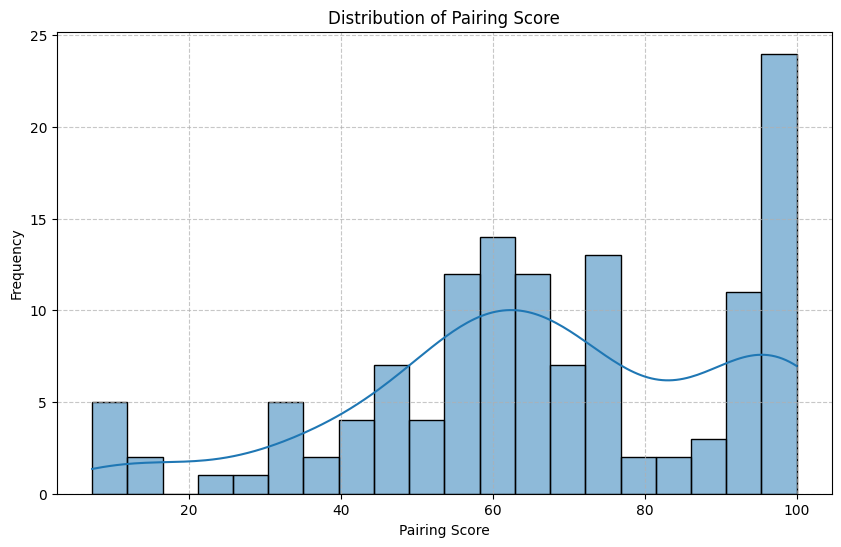

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(metrics_df_final['pairing_score'], kde=True, bins=20)
plt.title('Distribution of Pairing Score')
plt.xlabel('Pairing Score')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Pairs with 'Pairing score' 90 or better

In [68]:
high_pairing_score_df = metrics_df_final[
    (metrics_df_final['pairing_score'] >= 90) &
    (metrics_df_final['dist_midpoint_m'] <= 500) &
    (metrics_df_final['length_similarity'] >= 0.80)
].sort_values(by='pairing_score', ascending=False)
display(high_pairing_score_df[[
    'street',
    'directional_component_1_name',
    'directional_component_2_name',
    'max_endpoint_dist',
    'dist_midpoint_m',
    'length_ratio_comp1_comp2',
    'length_similarity',
    'pairing_score'
]])

,street,directional_component_1_name,directional_component_2_name,max_endpoint_dist,dist_midpoint_m,length_ratio_comp1_comp2,length_similarity,pairing_score
115,Sheridan,Sheridan_71,Sheridan_72,30.399892,30.399891,1.000000,1.000000,99.999998
63,Cicero,Cicero_32,Cicero_37,30.400450,30.400425,1.000000,1.000000,99.999996
56,Ashland,Ashland_29,Ashland_30,30.400390,30.400362,1.000000,1.000000,99.999996
39,Western,Western_14,Western_15,30.400412,30.400387,1.000000,1.000000,99.999996
24,Lake Shore Dr,Lake Shore Dr_5,Lake Shore Dr_9,30.401201,30.400440,1.000000,1.000000,99.999992
71,Cicero,Cicero_35,Cicero_36,30.400544,30.400498,1.000000,1.000000,99.999989
3,Lake Shore Dr,Lake Shore Dr_2,Lake Shore Dr_6,30.399648,30.399183,0.999999,0.999999,99.999971
91,Higgins,Higgins_48,Higgins_49,30.513558,30.513548,1.000000,1.000000,99.999658
93,Irving Park,Irving Park_52,Irving Park_53,30.513820,30.513507,1.000000,1.000000,99.999658
45,North,North_18,North_19,30.513962,30.513670,1.000000,1.000000,99.999658


Directional components were considered potential bidirectional matches when they exhibited high geometric similarity, including a length similarity of at least 0.98, while also satisfying the established spatial matching criteria.

In [69]:
import folium

# Ensure `components_table` is available (it should be from previous steps)

# Filter high_pairing_score_df for length_similarity >= 0.95
filtered_high_pairing_score_df = high_pairing_score_df[high_pairing_score_df['length_similarity'] >= 0.98]

# Prepare coordinate data for Component 1
comp1_coords = components_table[[
    'component_number',
    'street', # Include street name for tooltip
    'component_start_latitude',
    'component_start_longitude',
    'component_end_latitude',
    'component_end_longitude'
]].rename(columns={
    'component_number': 'directional_component_1_name', # Rename to match merge key
    'street': 'street_comp1',
    'component_start_latitude': 'comp1_start_latitude',
    'component_start_longitude': 'comp1_start_longitude',
    'component_end_latitude': 'comp1_end_latitude',
    'component_end_longitude': 'comp1_end_longitude'
})

# Prepare coordinate data for Component 2
comp2_coords = components_table[[
    'component_number',
    'street', # Include street name for tooltip
    'component_start_latitude',
    'component_start_longitude',
    'component_end_latitude',
    'component_end_longitude'
]].rename(columns={
    'component_number': 'directional_component_2_name', # Rename to match merge key
    'street': 'street_comp2',
    'component_start_latitude': 'comp2_start_latitude',
    'component_start_longitude': 'comp2_start_longitude',
    'component_end_latitude': 'comp2_end_latitude',
    'component_end_longitude': 'comp2_end_longitude'
})

# Merge filtered_high_pairing_score_df with comp1_coords
map_df = filtered_high_pairing_score_df.merge(
    comp1_coords,
    on='directional_component_1_name',
    how='left'
)

# Merge the result with comp2_coords
map_df = map_df.merge(
    comp2_coords,
    on='directional_component_2_name',
    how='left'
)

# Calculate the center of the map based on the average coordinates of the high-scoring pairs
# Handle case where map_df might be empty after filtering
if not map_df.empty:
    center_lat = map_df[['comp1_start_latitude', 'comp1_end_latitude', 'comp2_start_latitude', 'comp2_end_latitude']].mean().mean()
    center_lon = map_df[['comp1_start_longitude', 'comp1_end_longitude', 'comp2_start_longitude', 'comp2_end_longitude']].mean().mean()
else:
    # Default center if no high-similarity pairs are found
    center_lat = 41.8781  # Example: Center of Chicago
    center_lon = -87.6298 # Example: Center of Chicago
    print("No component pairs found with length_similarity >= 0.95. Displaying empty map centered on Chicago.")

m = folium.Map(location=[center_lat, center_lon], zoom_start=12)

for idx, row in map_df.iterrows():
    # Component 1 (Blue)
    comp1_coords = [
        (row['comp1_start_latitude'], row['comp1_start_longitude']),
        (row['comp1_end_latitude'], row['comp1_end_longitude'])
    ]
    folium.PolyLine(
        locations=comp1_coords,
        color='blue',
        weight=5,
        opacity=0.7,
        tooltip=f"Street: {row['street']} - Comp1: {row['directional_component_1_name']}"
    ).add_to(m)

    # Component 2 (Red)
    comp2_coords = [
        (row['comp2_start_latitude'], row['comp2_start_longitude']),
        (row['comp2_end_latitude'], row['comp2_end_longitude'])
    ]
    folium.PolyLine(
        locations=comp2_coords,
        color='red',
        weight=5,
        opacity=0.7,
        tooltip=f"Street: {row['street']} - Comp2: {row['directional_component_2_name']}"
    ).add_to(m)

    # Add markers for Component 1 endpoints
    folium.Marker(
        location=comp1_coords[0],
        tooltip=f"Comp1 Start: {row['directional_component_1_name']}",
        icon=folium.Icon(color='blue', icon='info-sign')
    ).add_to(m)
    folium.Marker(
        location=comp1_coords[1],
        tooltip=f"Comp1 End: {row['directional_component_1_name']}",
        icon=folium.Icon(color='blue', icon='info-sign')
    ).add_to(m)

    # Add markers for Component 2 endpoints
    folium.Marker(
        location=comp2_coords[0],
        tooltip=f"Comp2 Start: {row['directional_component_2_name']}",
        icon=folium.Icon(color='red', icon='info-sign')
    ).add_to(m)
    folium.Marker(
        location=comp2_coords[1],
        tooltip=f"Comp2 End: {row['directional_component_2_name']}",
        icon=folium.Icon(color='red', icon='info-sign')
    ).add_to(m)

display(m)

Under our current component construction and matching criteria, four pairs meet our high-confidence geometric matching criteria.

In [70]:
filtered_table_0_98_similarity = high_pairing_score_df[high_pairing_score_df['length_similarity'] >= 0.98]
display(filtered_table_0_98_similarity[['street',
    'directional_component_1_name',
    'directional_component_2_name',
    'max_endpoint_dist',
    'dist_midpoint_m',
    'length_ratio_comp1_comp2',
    'length_similarity',
    'pairing_score']])

,street,directional_component_1_name,directional_component_2_name,max_endpoint_dist,dist_midpoint_m,length_ratio_comp1_comp2,length_similarity,pairing_score
115,Sheridan,Sheridan_71,Sheridan_72,30.399892,30.399891,1.000000,1.000000,99.999998
63,Cicero,Cicero_32,Cicero_37,30.400450,30.400425,1.000000,1.000000,99.999996
56,Ashland,Ashland_29,Ashland_30,30.400390,30.400362,1.000000,1.000000,99.999996
39,Western,Western_14,Western_15,30.400412,30.400387,1.000000,1.000000,99.999996
24,Lake Shore Dr,Lake Shore Dr_5,Lake Shore Dr_9,30.401201,30.400440,1.000000,1.000000,99.999992
71,Cicero,Cicero_35,Cicero_36,30.400544,30.400498,1.000000,1.000000,99.999989
3,Lake Shore Dr,Lake Shore Dr_2,Lake Shore Dr_6,30.399648,30.399183,0.999999,0.999999,99.999971
91,Higgins,Higgins_48,Higgins_49,30.513558,30.513548,1.000000,1.000000,99.999658
93,Irving Park,Irving Park_52,Irving Park_53,30.513820,30.513507,1.000000,1.000000,99.999658
45,North,North_18,North_19,30.513962,30.513670,1.000000,1.000000,99.999658


In [71]:
print(f"Total number of entries in high_pairing_score_df: {len(high_pairing_score_df)}\n")

thresholds = [0.98, 0.97, 0.96, 0.95]

for threshold in thresholds:
    count = len(high_pairing_score_df[high_pairing_score_df['length_similarity'] >= threshold])
    print(f"Number of pairs with length_similarity >= {threshold}: {count}")

Total number of entries in high_pairing_score_df: 22

Number of pairs with length_similarity >= 0.98: 16
Number of pairs with length_similarity >= 0.97: 18
Number of pairs with length_similarity >= 0.96: 18
Number of pairs with length_similarity >= 0.95: 18


In [72]:
high_similarity_components = set()
high_similarity_components.update(filtered_table_0_98_similarity['directional_component_1_name'].tolist())
high_similarity_components.update(filtered_table_0_98_similarity['directional_component_2_name'].tolist())

components_table['in_high_similarity_pair'] = components_table['component_number'].isin(high_similarity_components)
display(components_table.head())

,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True


In [73]:
crash_df['street_normalized'] = (
    crash_df['street_name']
    .apply(normalize_street_name)
)

In [74]:
print('Re-normalizing crash_df...')
crash_df['street_normalized'] = (
    crash_df['street_name']
    .apply(normalize_street_name)
)

Re-normalizing crash_df...


In [75]:
# This cell is re-executed to ensure crash_df['street_normalized'] is created


In [76]:
print("Crash records:", len(crash_df))
print("Unique crash IDs:", crash_df['crash_record_id'].nunique())
print("Duplicate crash IDs:", crash_df['crash_record_id'].duplicated().sum())

Crash records: 1104275
Unique crash IDs: 1104275
Duplicate crash IDs: 0


In [77]:
from scipy.spatial import KDTree

def point_to_segment_haversine_distance(point_lat, point_lon, seg_start_lat, seg_start_lon, seg_end_lat, seg_end_lon):
    """Calculates the shortest Haversine distance from a point to a line segment."""
    # Use degree coordinates for vector math approximation, assuming small distances
    ax, ay = seg_start_lon, seg_start_lat
    bx, by = seg_end_lon, seg_end_lat
    px, py = point_lon, point_lat

    # Vector AB (segment vector)
    AB_x = bx - ax
    AB_y = by - ay

    # Vector AP (vector from segment start to point)
    AP_x = px - ax
    AP_y = py - ay

    # Calculate squared length of AB
    len_sq_AB = AB_x**2 + AB_y**2

    if len_sq_AB == 0:  # Segment is a point
        return haversine_distance(point_lat, point_lon, seg_start_lat, seg_start_lon)

    # Calculate t (projection parameter)
    t = (AP_x * AB_x + AP_y * AB_y) / len_sq_AB

    if t < 0.0:
        # Closest point is A (segment start)
        closest_lat, closest_lon = seg_start_lat, seg_start_lon
    elif t > 1.0:
        # Closest point is B (segment end)
        closest_lat, closest_lon = seg_end_lat, seg_end_lon
    else:
        # Closest point is on the segment
        closest_lat = seg_start_lat + t * (seg_end_lat - seg_start_lat)
        closest_lon = seg_start_lon + t * (seg_end_lon - seg_start_lon)

    return haversine_distance(point_lat, point_lon, closest_lat, closest_lon)


# Filter crash_df to only include crashes that matched a street in components_table and have valid coordinates
crashes_for_analysis = merged_crashes_with_components[
    (merged_crashes_with_components['_merge'] == 'both') &
    (merged_crashes_with_components['latitude'].notna()) &
    (merged_crashes_with_components['longitude'].notna())
].copy() # Ensure working on a copy


# Create a KDTree from all segment *start* points for efficient candidate searching
# We will use segment start points as a proxy to quickly find relevant segments
segment_start_coords = priority_ranking_df[['start_latitude', 'start_longitude']].values
kdtree_segment_starts = KDTree(segment_start_coords)

# Define new distance thresholds in meters
distance_bins = [
    (0, 10), (10, 25), (25, 50), (50, 75),
    (75, 100), (100, 150), (150, 250), (250, float('inf'))
]
crash_counts_within_bins = {f'{lower}-{upper}m': 0 for lower, upper in distance_bins}
crash_counts_within_bins['250+m'] = 0 # For distances greater than 250m

total_crashes_analyzed = len(crashes_for_analysis)

# Approximate search radius in degrees for KDTree query (e.g., 250 meters is roughly 0.00225 degrees)
# Using a slightly larger radius to be safe for initial candidate search
max_search_radius_m = 250 * 1.5 # Maximum distance for finite bins
search_radius_deg_for_candidates = max_search_radius_m / 111139.0 # Roughly meters to degrees

print(f"Analyzing {total_crashes_analyzed} crashes against {len(priority_ranking_df)} congestion components...")

# Initialize a list to store crash_record_id and their min distances
individual_crash_distances = []

# Iterate through each crash to find its minimum distance to any congestion component
for idx, crash_row in crashes_for_analysis.iterrows():
    crash_lat = crash_row['latitude']
    crash_lon = crash_row['longitude']

    min_dist_to_any_segment = float('inf')
    nearest_segment_id_for_crash = None # Initialize to None

    # Query KDTree for candidate segment start points within the approximate radius
    candidate_start_indices = kdtree_segment_starts.query_ball_point(
        [crash_lat, crash_lon],
        r=search_radius_deg_for_candidates
    )

    if not candidate_start_indices:
        # If no nearby segments, assign a very large distance
        min_dist_to_any_segment = float('inf')
        nearest_segment_id_for_crash = None
    else:
        # Get unique segment rows corresponding to these candidate start points
        # Using .iloc with a list of indices is efficient
        candidate_segments_df = priority_ranking_df.iloc[list(set(candidate_start_indices))]

        # Now calculate point-to-segment distance for each candidate segment
        for _, segment_row in candidate_segments_df.iterrows():
            seg_start_lat = segment_row['start_latitude']
            seg_start_lon = segment_row['start_longitude']
            seg_end_lat = segment_row['end_latitude']
            seg_end_lon = segment_row['end_longitude']

            dist = point_to_segment_haversine_distance(
                crash_lat, crash_lon,
                seg_start_lat, seg_start_lon,
                seg_end_lat, seg_end_lon
            )
            if dist < min_dist_to_any_segment:
                min_dist_to_any_segment = dist
                nearest_segment_id_for_crash = segment_row['segment_id'] # Capture segment_id

    # Append the calculated minimum distance and segment ID for this crash
    individual_crash_distances.append({
        'crash_record_id': crash_row['crash_record_id'],
        'nearest_component_distance': min_dist_to_any_segment,
        'nearest_segment_id': nearest_segment_id_for_crash
    })

    # Update counts based on the minimum distance found for this crash
    for lower, upper in distance_bins:
        if min_dist_to_any_segment >= lower and min_dist_to_any_segment < upper:
            crash_counts_within_bins[f'{lower}-{upper}m'] += 1
            break # Assign to the first matching bin
    else: # If no finite bin matched, it's 250+m
        crash_counts_within_bins['250+m'] += 1

# Convert the collected distances to a DataFrame
global crash_distances_df_results # Make it accessible globally
crash_distances_df_results = pd.DataFrame(individual_crash_distances)

# Calculate percentages and print results
print("\nPercentage of crashes within specified distances of congestion components:")
for bin_label, count in crash_counts_within_bins.items():
    percentage = (count / total_crashes_analyzed) * 100 if total_crashes_analyzed > 0 else 0
    print(f"{bin_label}: {count} crashes ({percentage:.2f}%)")

# Merge nearest_component_distance and nearest_segment_id into crashes_for_analysis
crashes_for_analysis = crashes_for_analysis.merge(
    crash_distances_df_results[['crash_record_id', 'nearest_component_distance', 'nearest_segment_id']],
    on='crash_record_id',
    how='left'
)

# Create the 'assigned' column AFTER the merge has been performed
crashes_for_analysis['assigned'] = crashes_for_analysis['nearest_component_distance'].apply(
    lambda x: 'Yes' if x <= 50 else 'No'
)

# Display head of the updated DataFrame
print("\nCrashes for analysis with nearest component distance and assignment:")
display(crashes_for_analysis.head())

Analyzing 348964 crashes against 912 congestion components...

Percentage of crashes within specified distances of congestion components:
0-10m: 104987 crashes (30.09%)
10-25m: 37749 crashes (10.82%)
25-50m: 67419 crashes (19.32%)
50-75m: 4939 crashes (1.42%)
75-100m: 3565 crashes (1.02%)
100-150m: 7245 crashes (2.08%)
150-250m: 9947 crashes (2.85%)
250-infm: 6714 crashes (1.92%)
250+m: 106399 crashes (30.49%)

Crashes for analysis with nearest component distance and assignment:


,crash_record_id,crash_date,street_name,latitude,longitude,most_severe_injury,street_normalized,_merge,nearest_component_distance,nearest_segment_id,assigned
0,419e0f4348b4274d902d84bd7aa58f5fa9c10820b77abc...,2026-05-19T23:15:00.000,LAKE SHORE DR,41.781882,-87.575497,NO INDICATION OF INJURY,LAKE SHORE,both,inf,NaN,No
1,401b13002f631a3faa4af328d3896d70547210e3cfc218...,2026-05-20T07:50:00.000,WESTERN AVE,41.793371,-87.684175,NO INDICATION OF INJURY,WESTERN,both,2.915247,381.0,Yes
2,041b5768954377ddad1bf0ce5e25e1e7f59b9f3310829b...,2026-08-20T11:00:00.000,WESTERN BLVD,41.810452,-87.683774,NO INDICATION OF INJURY,WESTERN,both,43.438854,343.0,Yes
3,042ef632ac2717feb5edef71ce0ccd84a178e53a60c323...,2026-08-20T12:45:00.000,WESTERN AVE,41.777328,-87.683445,NO INDICATION OF INJURY,WESTERN,both,27.080583,379.0,Yes
4,04bfa89b6010a715b7c5d59a4fc98f96930535453ea5dc...,2026-09-12T02:31:00.000,STATE ST,41.886930,-87.627838,NO INDICATION OF INJURY,STATE,both,3.375358,1296.0,Yes


In [78]:
# Prepare a mapping from individual segment_id to component_number
component_segment_map = []
for idx, row in components_table.iterrows():
    for seg_id in row['segment_ids']:
        component_segment_map.append({'segment_id': seg_id, 'component_number': row['component_number']})
component_segment_map_df = pd.DataFrame(component_segment_map)

# Filter crashes within 50 meters and merge with component_number mapping
neighboring_crashes = crashes_for_analysis[crashes_for_analysis['assigned'] == 'Yes'].copy()

# Ensure nearest_segment_id is not NaN (from crashes too far from any segment)
neighboring_crashes = neighboring_crashes[neighboring_crashes['nearest_segment_id'].notna()]
neighboring_crashes['nearest_segment_id'] = neighboring_crashes['nearest_segment_id'].astype(int) # Ensure type match

# Merge with component_segment_map_df to get component_number for each crash
crashes_with_component_info = neighboring_crashes.merge(
    component_segment_map_df,
    left_on='nearest_segment_id',
    right_on='segment_id',
    how='inner' # Only keep crashes assigned to a component
)

# Group by component_number and calculate metrics
component_crash_metrics = crashes_with_component_info.groupby('component_number').agg(
    neighboring_crashes_count=('crash_record_id', 'count'),
    average_crash_distance=('nearest_component_distance', 'mean'),
    median_crash_distance=('nearest_component_distance', 'median')
).reset_index()

# Merge these metrics into the components_table
components_table = components_table.merge(
    component_crash_metrics,
    on='component_number',
    how='left'
)

# Fill NaN values for components that had no neighboring crashes within 50m
components_table['neighboring_crashes_count'] = components_table['neighboring_crashes_count'].fillna(0).astype(int)
components_table['average_crash_distance'] = components_table['average_crash_distance'].fillna(0)
components_table['median_crash_distance'] = components_table['median_crash_distance'].fillna(0)

print("\nComponents table with new crash metrics:")
display(components_table.head())


Components table with new crash metrics:


,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair,neighboring_crashes_count,average_crash_distance,median_crash_distance
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False,83,10.379727,7.410551
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True,1,18.088076,18.088076
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False,1015,26.555865,29.336582
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False,92,22.099054,19.381131
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True,0,0.000000,0.000000


In [79]:
# Prepare a mapping from individual segment_id to component_number
component_segment_map = []
for idx, row in components_table.iterrows():
    for seg_id in row['segment_ids']:
        component_segment_map.append({'segment_id': seg_id, 'component_number': row['component_number']})
component_segment_map_df = pd.DataFrame(component_segment_map)

# Filter crashes within 50 meters and merge with component_number mapping
neighboring_crashes = crashes_for_analysis[crashes_for_analysis['assigned'] == 'Yes'].copy()

# Ensure nearest_segment_id is not NaN (from crashes too far from any segment)
neighboring_crashes = neighboring_crashes[neighboring_crashes['nearest_segment_id'].notna()]
neighboring_crashes['nearest_segment_id'] = neighboring_crashes['nearest_segment_id'].astype(int) # Ensure type match

# Merge with component_segment_map_df to get component_number for each crash
crashes_with_component_info = neighboring_crashes.merge(
    component_segment_map_df,
    left_on='nearest_segment_id',
    right_on='segment_id',
    how='inner' # Only keep crashes assigned to a component
)

# Group by component_number and calculate metrics
component_crash_metrics = crashes_with_component_info.groupby('component_number').agg(
    neighboring_crashes_count=('crash_record_id', 'count'),
    average_crash_distance=('nearest_component_distance', 'mean'),
    median_crash_distance=('nearest_component_distance', 'median')
).reset_index()

# Remove existing crash metric columns from components_table if they exist
for col in ['neighboring_crashes_count', 'average_crash_distance', 'median_crash_distance']:
    if col in components_table.columns:
        components_table = components_table.drop(columns=[col])
    if f'{col}_x' in components_table.columns:
        components_table = components_table.drop(columns=[f'{col}_x'])
    if f'{col}_y' in components_table.columns:
        components_table = components_table.drop(columns=[f'{col}_y'])


# Merge these metrics into the components_table
components_table = components_table.merge(
    component_crash_metrics,
    on='component_number',
    how='left'
)

# Fill NaN values for components that had no neighboring crashes within 50m
components_table['neighboring_crashes_count'] = components_table['neighboring_crashes_count'].fillna(0).astype(int)
components_table['average_crash_distance'] = components_table['average_crash_distance'].fillna(0)
components_table['median_crash_distance'] = components_table['median_crash_distance'].fillna(0)

print("\nComponents table with new crash metrics:")
display(components_table.head())


Components table with new crash metrics:


,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair,neighboring_crashes_count,average_crash_distance,median_crash_distance
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False,83,10.379727,7.410551
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True,1,18.088076,18.088076
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False,1015,26.555865,29.336582
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False,92,22.099054,19.381131
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True,0,0.000000,0.000000


In [80]:
# Prepare a mapping from individual segment_id to component_number
component_segment_map = []
for idx, row in components_table.iterrows():
    for seg_id in row['segment_ids']:
        component_segment_map.append({'segment_id': seg_id, 'component_number': row['component_number']})
component_segment_map_df = pd.DataFrame(component_segment_map)

# Filter crashes within 50 meters and merge with component_number mapping
neighboring_crashes = crashes_for_analysis[crashes_for_analysis['assigned'] == 'Yes'].copy()

# Ensure nearest_segment_id is not NaN (from crashes too far from any segment)
neighboring_crashes = neighboring_crashes[neighboring_crashes['nearest_segment_id'].notna()]
neighboring_crashes['nearest_segment_id'] = neighboring_crashes['nearest_segment_id'].astype(int) # Ensure type match

# Merge with component_segment_map_df to get component_number for each crash
crashes_with_component_info = neighboring_crashes.merge(
    component_segment_map_df,
    left_on='nearest_segment_id',
    right_on='segment_id',
    how='inner' # Only keep crashes assigned to a component
)

# Group by component_number and calculate metrics
component_crash_metrics = crashes_with_component_info.groupby('component_number').agg(
    neighboring_crashes_count=('crash_record_id', 'count'),
    average_crash_distance=('nearest_component_distance', 'mean'),
    median_crash_distance=('nearest_component_distance', 'median')
).reset_index()

# Remove existing crash metric columns from components_table if they exist
for col in ['neighboring_crashes_count', 'average_crash_distance', 'median_crash_distance']:
    if col in components_table.columns:
        components_table = components_table.drop(columns=[col])
    if f'{col}_x' in components_table.columns:
        components_table = components_table.drop(columns=[f'{col}_x'])
    if f'{col}_y' in components_table.columns:
        components_table = components_table.drop(columns=[f'{col}_y'])


# Merge these metrics into the components_table
components_table = components_table.merge(
    component_crash_metrics,
    on='component_number',
    how='left'
)

# Fill NaN values for components that had no neighboring crashes within 50m
components_table['neighboring_crashes_count'] = components_table['neighboring_crashes_count'].fillna(0).astype(int)
components_table['average_crash_distance'] = components_table['average_crash_distance'].fillna(0)
components_table['median_crash_distance'] = components_table['median_crash_distance'].fillna(0)
components_table.loc[
    components_table['neighboring_crashes_count'] == 0,
    ['average_crash_distance', 'median_crash_distance']
] = np.nan
print("\nComponents table with new crash metrics:")
display(components_table.head())


Components table with new crash metrics:


,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair,neighboring_crashes_count,average_crash_distance,median_crash_distance
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False,83,10.379727,7.410551
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True,1,18.088076,18.088076
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False,1015,26.555865,29.336582
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False,92,22.099054,19.381131
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True,0,NaN,NaN


In [81]:
components_table['component_length_miles'] = components_table.apply(
    lambda row: haversine_distance(
        row['component_start_latitude'], row['component_start_longitude'],
        row['component_end_latitude'], row['component_end_longitude']
    ) / 1609.34, axis=1
)
display(components_table.head())

,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair,neighboring_crashes_count,average_crash_distance,median_crash_distance,component_length_miles
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False,83,10.379727,7.410551,0.323464
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True,1,18.088076,18.088076,0.298147
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False,1015,26.555865,29.336582,4.677845
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False,92,22.099054,19.381131,2.182235
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True,0,NaN,NaN,3.047291


In [82]:
components_table['component_length_miles'] = components_table.apply(
    lambda row: haversine_distance(
        row['component_start_latitude'], row['component_start_longitude'],
        row['component_end_latitude'], row['component_end_longitude']
    ) / 1609.34, axis=1
)

zero_length = components_table[
    components_table['component_length_miles'] <= 0
][[
    'street',
    'component_number',
    'segment_ids',
    'num_segments_in_component',
    'component_start_latitude',
    'component_start_longitude',
    'component_end_latitude',
    'component_end_longitude',
    'component_length_miles',
    'neighboring_crashes_count'
]]

display(zero_length)

,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_length_miles,neighboring_crashes_count


In [83]:
import duckdb

# Re-initialize db_path and con for robustness in case kernel state changed
db_path = "/content/drive/MyDrive/chicago_traffic_project/chicago_traffic.duckdb"
con = duckdb.connect(db_path)

traffic_raw_df = con.sql("SELECT * FROM traffic_raw").to_df()

problem_ids = [822, 823, 1126, 1127, 1098, 1099, 1100, 886, 887]

# Filter traffic_raw_df using problem_ids (which are segment_id's)
# Select the requested columns and rename them to match the original request.
# fnode_id and tnode_id are not present in traffic_raw_df, so they are removed.
filtered_problem_segments_df = traffic_raw_df[
    traffic_raw_df["segment_id"].isin(problem_ids)
][[
    "segment_id",
    "street",
    "start_latitude",
    "start_longitude",
    "end_latitude",
    "end_longitude"
]].rename(columns={
    "segment_id": "trans_id",
    "street": "street_nam"
}).sort_values(["street_nam", "trans_id"])

display(filtered_problem_segments_df)

,trans_id,street_nam,start_latitude,start_longitude,end_latitude,end_longitude
9889,1098,Cermak,41.850238,-87.803613,41.850728,-87.783481
9890,1098,Cermak,41.850238,-87.803613,41.850728,-87.783481
9891,1098,Cermak,41.850238,-87.803613,41.850728,-87.783481
9892,1098,Cermak,41.850238,-87.803613,41.850728,-87.783481
9893,1098,Cermak,41.850238,-87.803613,41.850728,-87.783481
...,...,...,...,...,...,...
5095417,823,Torrence,41.708167,-87.559483,41.715404,-87.559592
5095418,823,Torrence,41.708167,-87.559483,41.715404,-87.559592
5095419,823,Torrence,41.708167,-87.559483,41.715404,-87.559592
5095420,823,Torrence,41.708167,-87.559483,41.715404,-87.559592


In [84]:
problem_geometry_df = (
    traffic_raw_df[
        traffic_raw_df["segment_id"].isin(problem_ids)
    ][[
        "segment_id",
        "street",
        "start_latitude",
        "start_longitude",
        "end_latitude",
        "end_longitude"
    ]]
    .drop_duplicates("segment_id")
    .sort_values(["street", "segment_id"])
)

display(problem_geometry_df)

,segment_id,street,start_latitude,start_longitude,end_latitude,end_longitude
9889,1098,Cermak,41.850238,-87.803613,41.850728,-87.783481
9900,1099,Cermak,41.850728,-87.783481,41.850728,-87.763481
9911,1100,Cermak,41.850728,-87.763481,41.851206,-87.744269
10043,1126,Cicero,41.836746,-87.743565,41.851243,-87.744067
10054,1127,Cicero,41.851243,-87.744067,41.865961,-87.744618
8591,886,Lake Shore Dr,41.792417,-87.580118,41.795218,-87.579008
8602,887,Lake Shore Dr,41.795218,-87.579008,41.802738,-87.581392
7986,822,Torrence,41.700975,-87.559392,41.708167,-87.559483
7997,823,Torrence,41.708167,-87.559483,41.715404,-87.559592


In [85]:
from math import radians, sin, cos, sqrt, atan2

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6371000

    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )

    return 2 * R * atan2(sqrt(a), sqrt(1 - a))


problem_geometry_df["segment_length_m"] = problem_geometry_df.apply(
    lambda row: haversine_m(
        row["start_latitude"],
        row["start_longitude"],
        row["end_latitude"],
        row["end_longitude"]
    ),
    axis=1
)

problem_geometry_df["segment_length_miles"] = (
    problem_geometry_df["segment_length_m"] / 1609.344
)

display(problem_geometry_df)

,segment_id,street,start_latitude,start_longitude,end_latitude,end_longitude,segment_length_m,segment_length_miles
9889,1098,Cermak,41.850238,-87.803613,41.850728,-87.783481,1668.430675,1.036715
9900,1099,Cermak,41.850728,-87.783481,41.850728,-87.763481,1656.549943,1.029332
9911,1100,Cermak,41.850728,-87.763481,41.851206,-87.744269,1592.145156,0.989313
10043,1126,Cicero,41.836746,-87.743565,41.851243,-87.744067,1612.616951,1.002034
10054,1127,Cicero,41.851243,-87.744067,41.865961,-87.744618,1637.153875,1.017280
8591,886,Lake Shore Dr,41.792417,-87.580118,41.795218,-87.579008,324.801504,0.201822
8602,887,Lake Shore Dr,41.795218,-87.579008,41.802738,-87.581392,859.217962,0.533893
7986,822,Torrence,41.700975,-87.559392,41.708167,-87.559483,799.695270,0.496908
7997,823,Torrence,41.708167,-87.559483,41.715404,-87.559592,804.824292,0.500095


In [86]:
# Recreate the component graph for Torrence
street_name = "Torrence"
street_df = priority_ranking_df[
    priority_ranking_df["street"] == street_name
].copy()

print(street_df[street_df["segment_id"].isin([822, 823])][[
    "segment_id",
    "start_latitude",
    "start_longitude",
    "end_latitude",
    "end_longitude"
]])

     segment_id  start_latitude  start_longitude  end_latitude  end_longitude
773         823       41.708167       -87.559483     41.715404     -87.559592
909         822       41.700975       -87.559392     41.708167     -87.559483


In [87]:
problem_segments = (
    street_df[
        street_df["segment_id"].isin([822, 823])
    ][[
        "segment_id",
        "start_latitude",
        "start_longitude",
        "end_latitude",
        "end_longitude"
    ]]
    .drop_duplicates("segment_id")
    .copy()
)

problem_segments["length_m"] = problem_segments.apply(
    lambda row: haversine_distance(
        row["start_latitude"],
        row["start_longitude"],
        row["end_latitude"],
        row["end_longitude"]
    ),
    axis=1
)

problem_segments["length_miles"] = (
    problem_segments["length_m"] / 1609.344
)

display(problem_segments)

,segment_id,start_latitude,start_longitude,end_latitude,end_longitude,length_m,length_miles
773,823,41.708167,-87.559483,41.715404,-87.559592,804.824292,0.500095
909,822,41.700975,-87.559392,41.708167,-87.559483,799.695270,0.496908


In [88]:
# 1. Check for zero or invalid component lengths
components_table[
    (components_table["component_length_miles"] <= 0) |
    (components_table["component_length_miles"].isna())
][[
    "street",
    "component_number",
    "segment_ids",
    "num_segments_in_component",
    "component_total_length_m",
    "component_length_miles"
]]

,street,component_number,segment_ids,num_segments_in_component,component_total_length_m,component_length_miles


In [89]:
# 2. Specifically verify the four components we found earlier
components_table[
    components_table["component_number"].isin([
        "Lake Shore Dr_10",
        "Cicero_37",
        "Cermak_64",
        "Torrence_98"
    ])
][[
    "street",
    "component_number",
    "segment_ids",
    "num_segments_in_component",
    "component_total_length_m",
    "component_length_miles",
    "neighboring_crashes_count"
]]

,street,component_number,segment_ids,num_segments_in_component,component_total_length_m,component_length_miles,neighboring_crashes_count
9,Lake Shore Dr,Lake Shore Dr_10,"[886, 887]",2,1184.019465,0.716160,1
36,Cicero,Cicero_37,"[1126, 1127]",2,3249.770826,2.019318,0
97,Torrence,Torrence_98,"[822, 823]",2,1604.519562,0.997004,195


In [90]:
components_table["crashes_per_mile"] = (
    components_table["neighboring_crashes_count"]
    / components_table["component_length_miles"]
)

display(
    components_table.sort_values(
        "crashes_per_mile",
        ascending=False
    )[[
        "street",
        "component_number",
        "component_length_miles",
        "neighboring_crashes_count",
        "crashes_per_mile"
    ]].head(20)
)

,street,component_number,component_length_miles,neighboring_crashes_count,crashes_per_mile
69,Wacker,Wacker_70,0.198162,482,2432.354975
22,Archer,Archer_23,0.513969,607,1181.004567
33,Cicero,Cicero_34,1.613009,1770,1097.327998
73,Michigan,Michigan_74,4.317463,4405,1020.275211
53,Grand,Grand_54,0.945041,934,988.317388
45,Stony Island,Stony Island_46,5.790221,5673,979.755302
34,Cicero,Cicero_35,6.658630,6231,935.778017
88,Illinois,Illinois_89,0.943009,867,919.397154
46,Stony Island,Stony Island_47,4.783501,3837,802.132183
32,Cicero,Cicero_33,1.515657,1208,797.014280


In [91]:
display(components_table)

,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair,neighboring_crashes_count,average_crash_distance,median_crash_distance,component_length_miles,crashes_per_mile
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False,83,10.379727,7.410551,0.323464,256.597089
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True,1,18.088076,18.088076,0.298147,3.354055
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False,1015,26.555865,29.336582,4.677845,216.980269
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False,92,22.099054,19.381131,2.182235,42.158609
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True,0,NaN,NaN,3.047291,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,Pershing,Pershing_95,[977],1,41.823915,-87.630508,41.823590,-87.645952,1280.204093,PERSHING,False,136,27.074065,37.823802,0.795484,170.965115
95,Pershing,Pershing_96,"[969, 971]",2,41.823879,-87.616998,41.823390,-87.645952,2063.285175,PERSHING,False,376,16.531377,18.854386,1.491162,252.152414
96,Torrence,Torrence_97,"[985, 987]",2,41.715407,-87.559959,41.691942,-87.559645,1809.579177,TORRENCE,False,203,9.979079,3.038520,1.621331,125.205746
97,Torrence,Torrence_98,"[822, 823]",2,41.715404,-87.559592,41.700975,-87.559392,1604.519562,TORRENCE,False,195,21.784450,27.764811,0.997004,195.585922


In [92]:
bus_routes_df = pd.read_json(bus_routes_url)
bus_routes_df.info()

bus_routes_df.describe()
bus_routes_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   :id          127 non-null    object             
 1   :version     127 non-null    object             
 2   :created_at  127 non-null    datetime64[ns, UTC]
 3   :updated_at  127 non-null    datetime64[ns, UTC]
 4   the_geom     127 non-null    object             
 5   route        127 non-null    object             
 6   name         127 non-null    object             
 7   wkday        127 non-null    bool               
 8   sat          127 non-null    bool               
 9   sun          127 non-null    bool               
dtypes: bool(3), datetime64[ns, UTC](2), object(5)
memory usage: 7.4+ KB


,:id,:version,:created_at,:updated_at,the_geom,route,name,wkday,sat,sun
0,row-b3tj.bdx2.t35x,rv-t5m4~3a3r~f5uk,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",57,LARAMIE,True,True,True
1,row-w99j-wzyw.i643,rv-xd59_g954.4jq5,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",106,EAST 103RD,True,True,True
2,row-k4y7~vi6q_m2s5,rv-d6ha-icjn~pxnf,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",192,U OF CHICAGO HOSPITALS EXPRESS,True,False,False
3,row-yi4q~ynaj-h89w,rv-872z.srde-nfsh,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",2,HYDE PARK EXPRESS,True,False,False
4,row-b82a~i66n-5vnv,rv-n3bh-jwmu_9adn,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",12,ROOSEVELT,True,True,True


In [93]:
CTA_ridership_df = pd.read_json(CTA_ridership_url)
CTA_ridership_df.info()

CTA_ridership_df.describe()
CTA_ridership_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41394 entries, 0 to 41393
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype              
---  ------                    --------------  -----              
 0   :id                       41394 non-null  object             
 1   :version                  41394 non-null  object             
 2   :created_at               41394 non-null  datetime64[ns, UTC]
 3   :updated_at               41394 non-null  datetime64[ns, UTC]
 4   route                     41394 non-null  object             
 5   routename                 41394 non-null  object             
 6   month_beginning           41394 non-null  object             
 7   avg_weekday_rides         41394 non-null  float64            
 8   avg_saturday_rides        41394 non-null  float64            
 9   avg_sunday_holiday_rides  41394 non-null  float64            
 10  monthtotal                41394 non-null  int64              
dtypes: datetime64[n

,:id,:version,:created_at,:updated_at,route,routename,month_beginning,avg_weekday_rides,avg_saturday_rides,avg_sunday_holiday_rides,monthtotal
0,row-98k5_9pa5_piac,rv-6h7y~jfas_2nfd,2026-03-20 19:28:26.152000+00:00,2026-03-20 19:28:26.152000+00:00,1,Indiana/Hyde Park,2001-01-01T00:00:00.000,6982.6,0.0,0.0,153617
1,row-gh62_ngkr.2puh,rv-35ra~fkfh-k5ps,2026-03-20 19:28:26.152000+00:00,2026-03-20 19:28:26.152000+00:00,2,Hyde Park Express,2001-01-01T00:00:00.000,1000.0,0.0,0.0,22001
2,row-j9in_p9mp.w6fu,rv-dspd~b9ai.8zmc,2026-03-20 19:28:26.152000+00:00,2026-03-20 19:28:26.152000+00:00,3,King Drive,2001-01-01T00:00:00.000,21406.5,13210.7,8725.3,567413
3,row-us8y_56ca-nfu4,rv-p9dx.ciwj~fc2r,2026-03-20 19:28:26.152000+00:00,2026-03-20 19:28:26.152000+00:00,4,Cottage Grove,2001-01-01T00:00:00.000,22432.2,17994.0,10662.2,618796
4,row-must~htjg.yyg7,rv-vmca_fmke_dhjr,2026-03-20 19:28:26.152000+00:00,2026-03-20 19:28:26.152000+00:00,6,Jackson Park Express,2001-01-01T00:00:00.000,18443.0,13088.2,7165.6,493926


In [94]:
bus_routes_df.columns

Index([':id', ':version', ':created_at', ':updated_at', 'the_geom', 'route',
       'name', 'wkday', 'sat', 'sun'],
      dtype='object')

In [95]:
CTA_ridership_df.columns

Index([':id', ':version', ':created_at', ':updated_at', 'route', 'routename',
       'month_beginning', 'avg_weekday_rides', 'avg_saturday_rides',
       'avg_sunday_holiday_rides', 'monthtotal'],
      dtype='object')

In [96]:
CTA_ridership_df["month_beginning"] = pd.to_datetime(
    CTA_ridership_df["month_beginning"]
)

ridership_2025 = CTA_ridership_df[
    CTA_ridership_df["month_beginning"].dt.year == 2025
].copy()

route_ridership_2025 = (
    ridership_2025
    .groupby("route", as_index=False)["monthtotal"]
    .sum()
    .rename(columns={
        "monthtotal": "annual_ridership_2025"
    })
)

display(route_ridership_2025.sort_values(
    "annual_ridership_2025",
    ascending=False
).head(20))

,route,annual_ridership_2025
88,66,5942977
114,9,5874174
101,79,5821894
102,8,5375467
70,53,5259715
51,3,4926710
59,4,4702942
64,49,4623625
46,22,4604400
99,77,4583486


In [97]:
bus_routes_with_ridership = bus_routes_df.merge(
    route_ridership_2025,
    on="route",
    how="left",
    indicator=True
)

display(
    bus_routes_with_ridership[
        [
            "route",
            "name",
            "annual_ridership_2025",
            "_merge"
        ]
    ].sort_values(
        "annual_ridership_2025",
        ascending=False
    ).head(20)
)

,route,name,annual_ridership_2025,_merge
93,66,CHICAGO,5942977.0,both
108,9,ASHLAND,5874174.0,both
60,79,79TH,5821894.0,both
61,8,HALSTED,5375467.0,both
56,53,PULASKI,5259715.0,both
118,3,KING DRIVE,4926710.0,both
121,4,COTTAGE GROVE,4702942.0,both
78,49,WESTERN,4623625.0,both
35,22,CLARK,4604400.0,both
104,77,BELMONT,4583486.0,both


In [98]:
print('Creating normalized street names for bus routes...')
bus_routes_with_ridership['street_normalized'] = (
    bus_routes_with_ridership['name']
    .apply(normalize_street_name)
)

display(bus_routes_with_ridership.head())

Creating normalized street names for bus routes...


,:id,:version,:created_at,:updated_at,the_geom,route,name,wkday,sat,sun,annual_ridership_2025,_merge,street_normalized
0,row-b3tj.bdx2.t35x,rv-t5m4~3a3r~f5uk,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",57,LARAMIE,True,True,True,518208.0,both,LARAMIE
1,row-w99j-wzyw.i643,rv-xd59_g954.4jq5,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",106,EAST 103RD,True,True,True,275266.0,both,EAST 103RD
2,row-k4y7~vi6q_m2s5,rv-d6ha-icjn~pxnf,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",192,U OF CHICAGO HOSPITALS EXPRESS,True,False,False,110243.0,both,U OF CHICAGO HOSPITALS EXPRESS
3,row-yi4q~ynaj-h89w,rv-872z.srde-nfsh,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",2,HYDE PARK EXPRESS,True,False,False,485812.0,both,HYDE PARK EXPRESS
4,row-b82a~i66n-5vnv,rv-n3bh-jwmu_9adn,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",12,ROOSEVELT,True,True,True,3034430.0,both,ROOSEVELT


Now that both DataFrames have a normalized street name column, let's merge them.

In [99]:
# Perform a left merge to retain all components and add bus route ridership information
components_with_bus_routes = pd.merge(
    components_table,
    bus_routes_with_ridership[['street_normalized', 'route', 'name', 'annual_ridership_2025']].drop_duplicates(),
    on='street_normalized',
    how='left',
    suffixes=('_component', '_bus_route')
)

print("Components Table merged with Bus Routes:")
display(components_with_bus_routes.head())

Components Table merged with Bus Routes:


,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair,neighboring_crashes_count,average_crash_distance,median_crash_distance,component_length_miles,crashes_per_mile,route,name,annual_ridership_2025
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False,83,10.379727,7.410551,0.323464,256.597089,NaN,NaN,NaN
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True,1,18.088076,18.088076,0.298147,3.354055,NaN,NaN,NaN
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False,1015,26.555865,29.336582,4.677845,216.980269,NaN,NaN,NaN
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False,92,22.099054,19.381131,2.182235,42.158609,NaN,NaN,NaN
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True,0,NaN,NaN,3.047291,0.000000,NaN,NaN,NaN


In [100]:
# Check the merge status
print("Merge status value counts:")
components_with_bus_routes['_merge'] = components_with_bus_routes.apply(
    lambda row: 'both' if pd.notna(row['route']) else 'left_only', axis=1
)
display(components_with_bus_routes['_merge'].value_counts())

Merge status value counts:


,count
_merge,
both,70
left_only,29


In [101]:
bus_routes_with_ridership["_merge"].value_counts()


,count
_merge,
both,126
left_only,1
right_only,0


In [102]:
bus_routes_df.loc[0, "the_geom"]

{'type': 'MultiLineString',
 'coordinates': [[[-87.75480000023407, 41.872929999614335],
   [-87.75346999934038, 41.87294999978841],
   [-87.75326999996294, 41.872949999979895],
   [-87.75284000001834, 41.872960000855684],
   [-87.74916000036663, 41.87303999973001],
   [-87.74850000004946, 41.87306000006246],
   [-87.74841000036616, 41.87305999998801],
   [-87.7474899998263, 41.873069999681796],
   [-87.74677999978219, 41.873099999877525],
   [-87.74544000064141, 41.87313000014876],
   [-87.745220000385, 41.873130000076685],
   [-87.74500000086965, 41.87315999993968],
   [-87.74500000003886, 41.87298000051759],
   [-87.74498999958193, 41.87272999945423],
   [-87.74497000014655, 41.87229999993476],
   [-87.74496000091811, 41.87205999986579],
   [-87.74494999949842, 41.87181000055532],
   [-87.74494000048225, 41.87163999950652],
   [-87.74493999992042, 41.87159999992312],
   [-87.74495000028955, 41.87145999995424],
   [-87.74494999940678, 41.871439999708684],
   [-87.74494999961567, 41.87

In [103]:
type(bus_routes_df.loc[0, "the_geom"])

dict

In [104]:
pip install geopandas -q

In [105]:
import geopandas as gpd
from shapely.geometry import MultiLineString, LineString

### Convert bus routes to GeoDataFrame

In [106]:
def parse_multilinestring_geometry(geom_dict):
    if geom_dict and geom_dict['type'] == 'MultiLineString':
        return MultiLineString(geom_dict['coordinates'])
    return None

bus_routes_df['geometry'] = bus_routes_df['the_geom'].apply(parse_multilinestring_geometry)
bus_routes_gdf = gpd.GeoDataFrame(
    bus_routes_df,
    geometry='geometry',
    crs="EPSG:4326" # WGS84 geographic coordinate system
)

print("Bus Routes GeoDataFrame head:")
display(bus_routes_gdf.head())

Bus Routes GeoDataFrame head:


,:id,:version,:created_at,:updated_at,the_geom,route,name,wkday,sat,sun,geometry
0,row-b3tj.bdx2.t35x,rv-t5m4~3a3r~f5uk,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",57,LARAMIE,True,True,True,"MULTILINESTRING ((-87.7548 41.87293, -87.75347..."
1,row-w99j-wzyw.i643,rv-xd59_g954.4jq5,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",106,EAST 103RD,True,True,True,"MULTILINESTRING ((-87.59423 41.70764, -87.5933..."
2,row-k4y7~vi6q_m2s5,rv-d6ha-icjn~pxnf,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",192,U OF CHICAGO HOSPITALS EXPRESS,True,False,False,"MULTILINESTRING ((-87.63924 41.86725, -87.6385..."
3,row-yi4q~ynaj-h89w,rv-872z.srde-nfsh,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",2,HYDE PARK EXPRESS,True,False,False,"MULTILINESTRING ((-87.7462 41.74905, -87.7458 ..."
4,row-b82a~i66n-5vnv,rv-n3bh-jwmu_9adn,2025-01-08 17:26:16.509000+00:00,2025-01-08 17:26:16.509000+00:00,"{'type': 'MultiLineString', 'coordinates': [[[...",12,ROOSEVELT,True,True,True,"MULTILINESTRING ((-87.64791 41.86713, -87.6474..."


In [182]:
# Examine adjacency of key adjacent corridors (Western Ave and Stony Island Ave)
pairs_to_check = [
    ('Western_14', 'Western_15'),
    ('Stony Island_46', 'Stony Island_47')
]

adjacency_results = []

for comp1_id, comp2_id in pairs_to_check:
    comp1 = components_table[components_table['component_number'] == comp1_id]
    comp2 = components_table[components_table['component_number'] == comp2_id]

    if not comp1.empty and not comp2.empty:
        row1 = comp1.iloc[0]
        row2 = comp2.iloc[0]

        # Collect start and end coords for both components
        pts1 = [
            ('start', row1['component_start_latitude'], row1['component_start_longitude']),
            ('end', row1['component_end_latitude'], row1['component_end_longitude'])
        ]
        pts2 = [
            ('start', row2['component_start_latitude'], row2['component_start_longitude']),
            ('end', row2['component_end_latitude'], row2['component_end_longitude'])
        ]

        # Find the minimum distance between any endpoint of comp1 and any endpoint of comp2
        min_dist = float('inf')
        best_pair = (None, None)

        for name1, lat1, lon1 in pts1:
            for name2, lat2, lon2 in pts2:
                d = haversine_distance(lat1, lon1, lat2, lon2)
                if d < min_dist:
                    min_dist = d
                    best_pair = (name1, name2)

        adjacency_results.append({
            'component_1': comp1_id,
            'component_2': comp2_id,
            'min_endpoint_distance_m': min_dist,
            'connecting_endpoints': best_pair,
            'combined_length_miles': row1['component_length_miles'] + row2['component_length_miles']
        })

adjacency_df = pd.DataFrame(adjacency_results)
display(adjacency_df)

,component_1,component_2,min_endpoint_distance_m,connecting_endpoints,combined_length_miles
0,Western_14,Western_15,30.400014,"(start, start)",33.227187
1,Stony Island_46,Stony Island_47,30.400596,"(start, start)",10.573722


### Convert congestion components to GeoDataFrame

In [107]:
components_table['geometry'] = components_table.apply(
    lambda row: LineString([
        (row['component_start_longitude'], row['component_start_latitude']),
        (row['component_end_longitude'], row['component_end_latitude'])
    ]),
    axis=1
)

components_gdf = gpd.GeoDataFrame(
    components_table,
    geometry='geometry',
    crs="EPSG:4326" # WGS84 geographic coordinate system
)

print("Congestion Components GeoDataFrame head:")
display(components_gdf.head())

Congestion Components GeoDataFrame head:


,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair,neighboring_crashes_count,average_crash_distance,median_crash_distance,component_length_miles,crashes_per_mile,geometry
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False,83,10.379727,7.410551,0.323464,256.597089,"LINESTRING (-87.62064 41.88465, -87.61436 41.8..."
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True,1,18.088076,18.088076,0.298147,3.354055,"LINESTRING (-87.61386 41.88439, -87.6173 41.88..."
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False,1015,26.555865,29.336582,4.677845,216.980269,"LINESTRING (-87.64815 41.96941, -87.62465 41.904)"
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False,92,22.099054,19.381131,2.182235,42.158609,"LINESTRING (-87.65339 41.98555, -87.64458 41.9..."
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True,0,NaN,NaN,3.047291,0.000000,"LINESTRING (-87.61642 41.85796, -87.59469 41.8..."


### Calculate intersection lengths between bus routes and congestion components

In [108]:
bus_routes_gdf_proj = bus_routes_gdf.to_crs(epsg=3857) # Project to a projected CRS (meters)
components_gdf_proj = components_gdf.to_crs(epsg=3857)

intersection_lengths = []

print(f"Processing {len(bus_routes_gdf_proj)} bus routes and {len(components_gdf_proj)} congestion components.")

for idx_bus, bus_route in bus_routes_gdf_proj.iterrows():
    for idx_comp, component in components_gdf_proj.iterrows():
        if bus_route.geometry.intersects(component.geometry):
            intersection_geom = bus_route.geometry.intersection(component.geometry)

            length_m = 0
            if intersection_geom.geom_type == 'LineString':
                length_m = intersection_geom.length
            elif intersection_geom.geom_type == 'MultiLineString':
                length_m = sum(line.length for line in intersection_geom.geoms)
            # else: length_m remains 0 for other geometry types or empty intersection

            if length_m > 0:
                intersection_lengths.append({
                    'bus_route_id': bus_route[':id'],
                    'bus_route_name': bus_route['name'],
                    'component_number': component['component_number'],
                    'component_street': component['street'],
                    'intersection_length_m': length_m
                })

intersection_df = pd.DataFrame(intersection_lengths)

print("Intersection lengths between bus routes and congestion components:")
if not intersection_df.empty:
    display(intersection_df.sort_values(by='intersection_length_m', ascending=False).head())
else:
    print("No intersections with positive length were found.")

Processing 127 bus routes and 99 congestion components.
Intersection lengths between bus routes and congestion components:
No intersections with positive length were found.


In [109]:
route_9_gdf = bus_routes_gdf[
    bus_routes_gdf["route"].astype(str) == "9"
].to_crs(epsg=26916)

ashland_31_gdf = components_gdf[
    components_gdf["component_number"] == "Ashland_31"
].to_crs(epsg=26916)

distance_m = route_9_gdf.geometry.iloc[0].distance(
    ashland_31_gdf.geometry.iloc[0]
)

print(f"Distance: {distance_m:.1f} meters")

Distance: 1621.4 meters


In [110]:
for buffer_m in [10, 25, 50, 100]:
    buffered = ashland_31_gdf.geometry.buffer(buffer_m)

    matches = route_9_gdf.geometry.intersects(buffered)

    print(f"{buffer_m} m buffer: {matches.iloc[0]}")

10 m buffer: False
25 m buffer: False
50 m buffer: False
100 m buffer: False


/tmp/ipykernel_16305/721229199.py:4: UserWarning: The indices of the left and right GeoSeries' are not equal, and therefore they will be aligned (reordering and/or introducing missing values) before executing the operation. If this alignment is the desired behaviour, you can silence this warning by passing 'align=True'. If you don't want alignment and protect yourself of accidentally aligning, you can pass 'align=False'.
  matches = route_9_gdf.geometry.intersects(buffered)
/tmp/ipykernel_16305/721229199.py:4: UserWarning: The indices of the left and right GeoSeries' are not equal, and therefore they will be aligned (reordering and/or introducing missing values) before executing the operation. If this alignment is the desired behaviour, you can silence this warning by passing 'align=True'. If you don't want alignment and protect yourself of accidentally aligning, you can pass 'align=False'.
  matches = route_9_gdf.geometry.intersects(buffered)
/tmp/ipykernel_16305/721229199.py:4: UserW

In [111]:
components_proj = components_gdf.to_crs(epsg=26916)
bus_routes_proj = bus_routes_gdf.to_crs(epsg=26916)

In [112]:
nearest_routes = gpd.sjoin_nearest(
    components_proj,
    bus_routes_proj[
        ["route", "name", "geometry"]
    ],
    how="left",
    distance_col="nearest_route_distance_m"
)

In [113]:
display(
    nearest_routes[
        [
            "component_number",
            "street",
            "route",
            "name",
            "nearest_route_distance_m"
        ]
    ].sort_values(
        "nearest_route_distance_m"
    ).head(30)
)

,component_number,street,route,name,nearest_route_distance_m
68,Roosevelt_69,Roosevelt,60,BLUE ISLAND/26TH,0.0
69,Wacker_70,Wacker,146,INNER LAKE SHORE/MICHIGAN EXPRESS,0.0
69,Wacker_70,Wacker,2,HYDE PARK EXPRESS,0.0
69,Wacker_70,Wacker,134,STOCKTON/LASALLE EXPRESS,0.0
69,Wacker_70,Wacker,120,OGILVIE/STREETERVILLE EXPRESS,0.0
69,Wacker_70,Wacker,121,UNION/STREETERVILLE EXPRESS,0.0
69,Wacker_70,Wacker,10,MUSEUM OF SCIENCE & INDUSTRY,0.0
69,Wacker_70,Wacker,6,JACKSON PARK EXPRESS,0.0
68,Roosevelt_69,Roosevelt,62,ARCHER,0.0
68,Roosevelt_69,Roosevelt,146,INNER LAKE SHORE/MICHIGAN EXPRESS,0.0


In [114]:
# Create a 25-meter buffer around each congestion component
components_buffered = components_gdf_proj.copy()

components_buffered["geometry"] = (
    components_buffered.geometry.buffer(25)
)

print(
    f"Processing {len(bus_routes_gdf_proj)} bus routes "
    f"and {len(components_buffered)} components."
)

Processing 127 bus routes and 99 components.


In [115]:
intersection_lengths = []

for _, bus_route in bus_routes_gdf_proj.iterrows():

    for _, component in components_buffered.iterrows():

        if not bus_route.geometry.intersects(component.geometry):
            continue

        intersection_geom = bus_route.geometry.intersection(
            component.geometry
        )

        if intersection_geom.is_empty:
            continue

        length_m = intersection_geom.length

        if length_m > 0:
            intersection_lengths.append({
                "route": bus_route["route"],
                "name": bus_route["name"],
                "component_number": component["component_number"],
                "street": component["street"],
                "route_component_overlap_m": length_m
            })

route_component_overlap_df = pd.DataFrame(
    intersection_lengths
)

display(
    route_component_overlap_df.sort_values(
        "route_component_overlap_m",
        ascending=False
    ).head(30)
)

,route,name,component_number,street,route_component_overlap_m
906,X49,WESTERN EXPRESS,Western_14,Western,38681.887708
826,49,WESTERN,Western_14,Western,37279.731239
927,X9,ASHLAND EXPRESS,Ashland_29,Ashland,35285.382854
1161,9,ASHLAND,Ashland_29,Ashland,35254.852129
634,8,HALSTED,Halsted_39,Halsted,29650.075932
624,79,79TH,79th_66,79th,23240.309259
957,80,IRVING PARK,Irving Park_52,Irving Park,20004.754269
602,72,NORTH,North_19,North,19105.283089
499,169,69TH/UPS EXPRESS,79th_66,79th,16735.560713
364,53A,SOUTH PULASKI,Pulaski_24,Pulaski,15976.951987


In [116]:
route_component_overlap_df["route_component_overlap_m"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

,route_component_overlap_m
count,1384.000000
mean,754.390834
std,2813.512095
min,8.432277
25%,50.007758
50%,68.144925
75%,293.644977
90%,1517.009002
95%,2825.510223
99%,12806.243156


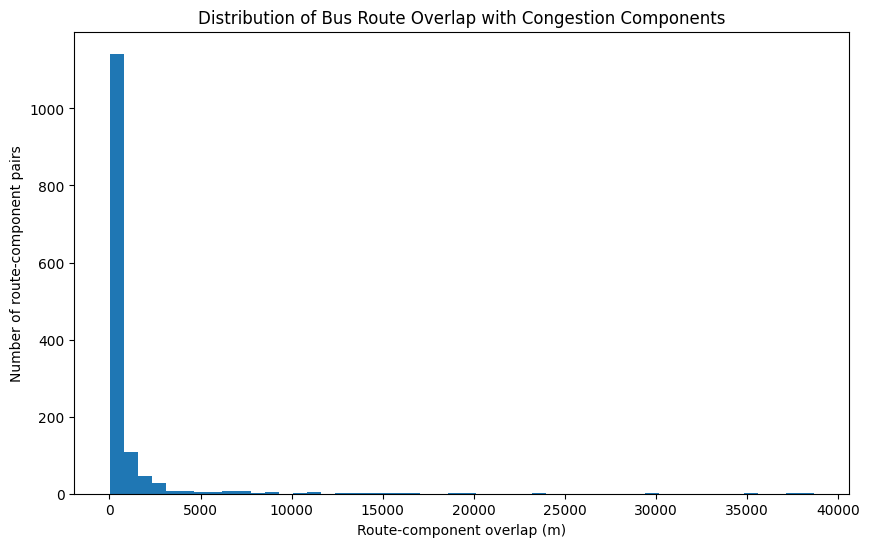

In [117]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(
    route_component_overlap_df["route_component_overlap_m"],
    bins=50
)
plt.xlabel("Route-component overlap (m)")
plt.ylabel("Number of route-component pairs")
plt.title("Distribution of Bus Route Overlap with Congestion Components")
plt.show()

In [118]:
display(
    route_component_overlap_df
    .sort_values("route_component_overlap_m")
    .head(30)
)

,route,name,component_number,street,route_component_overlap_m
460,156,LASALLE,LaSalle_28,LaSalle,8.432277
31,2,HYDE PARK EXPRESS,79th_66,79th,10.672408
32,2,HYDE PARK EXPRESS,79th_67,79th,10.808885
440,152,ADDISON,Lake Shore Dr_8,Lake Shore Dr,11.032366
1219,85,CENTRAL,Higgins_49,Higgins,11.211839
571,53,PULASKI,Peterson_51,Peterson,11.508532
764,55N,55TH/NARRAGANSETT,Archer_22,Archer,11.528216
388,73,ARMITAGE,North_19,North,13.087020
312,135,CLARENDON/LASALLE EXPRESS,Irving Park_53,Irving Park,13.874382
267,148,CLARENDON/MICHIGAN EXPRESS,Irving Park_53,Irving Park,13.874382


In [119]:
components_length = (
    components_proj[
        ["street", "component_number", "component_total_length_m"]
    ]
)

transit_diagnostic = route_component_overlap_df.merge(
    components_length,
    on=["street", "component_number"],
    how="left"
)

transit_diagnostic["component_coverage_pct"] = (
    transit_diagnostic["route_component_overlap_m"]
    / transit_diagnostic["component_total_length_m"]
    * 100
)

display(
    transit_diagnostic
    .sort_values("component_coverage_pct", ascending=False)
    .head(30)
)

,route,name,component_number,street,route_component_overlap_m,component_total_length_m,component_coverage_pct
1282,21,CERMAK,Cermak_63,Cermak,4547.587388,1548.034651,293.765219
524,29,STATE,State_76,State,4778.906477,2011.820040,237.541449
239,146,INNER LAKE SHORE/MICHIGAN EXPRESS,State_76,State,4120.515977,2011.820040,204.815336
668,62,ARCHER,State_76,State,4078.597494,2011.820040,202.731726
880,95,95TH,95th_81,95th,14307.126740,7241.109608,197.581966
624,79,79TH,79th_66,79th,23240.309259,12076.006806,192.450283
1364,20,MADISON,Madison_85,Madison,4785.917788,2703.803555,177.006861
981,65,GRAND,Grand_54,Grand,2095.560967,1196.402951,175.155115
986,65,GRAND,Illinois_89,Illinois,2090.977479,1194.414529,175.062964
756,55,GARFIELD,Garfield_87,Garfield,7743.585682,4479.635127,172.861973


In [120]:
bus_routes_proj["route_total_length_m"] = (
    bus_routes_proj.geometry.length
)

In [121]:
route_component_df = route_component_overlap_df.merge(
    bus_routes_proj[
        ["route", "route_total_length_m"]
    ],
    on="route",
    how="left"
)

route_component_df["route_exposure_pct"] = (
    route_component_df["route_component_overlap_m"]
    / route_component_df["route_total_length_m"]
    * 100
)

In [122]:
display(
    route_component_df[
        [
            "route",
            "name",
            "street",
            "component_number",
            "route_component_overlap_m",
            "route_total_length_m",
            "route_exposure_pct"
        ]
    ]
    .sort_values("route_exposure_pct", ascending=False)
    .head(30)
)

,route,name,street,component_number,route_component_overlap_m,route_total_length_m,route_exposure_pct
826,49,WESTERN,Western,Western_14,37279.731239,28229.421263,132.059850
634,8,HALSTED,Halsted,Halsted_39,29650.075932,23501.302722,126.163542
602,72,NORTH,North,North_19,19105.283089,15154.706684,126.068313
927,X9,ASHLAND EXPRESS,Ashland,Ashland_29,35285.382854,29269.438959,120.553670
957,80,IRVING PARK,Irving Park,Irving Park_52,20004.754269,16833.934178,118.835883
906,X49,WESTERN EXPRESS,Western,Western_14,38681.887708,33995.581972,113.785043
1161,9,ASHLAND,Ashland,Ashland_29,35254.852129,31969.990746,110.274827
624,79,79TH,79th,79th_66,23240.309259,23664.298563,98.208317
364,53A,SOUTH PULASKI,Pulaski,Pulaski_24,15976.951987,17684.814609,90.342773
142,54,CICERO,Cicero,Cicero_35,10455.870095,12806.441999,81.645395


In [123]:
bus_routes_gdf.geometry.geom_type.value_counts()

,count
MultiLineString,127


In [124]:
bus_routes_gdf["route"].nunique()

127

In [125]:
bus_routes_gdf.assign(
    geometry_parts=bus_routes_gdf.geometry.apply(
        lambda x: len(x.geoms) if x.geom_type == "MultiLineString" else 1
    )
)[["route", "name", "geometry_parts"]].sort_values(
    "geometry_parts",
    ascending=False
).head(20)

,route,name,geometry_parts
21,24,WENTWORTH,24
44,157,STREETERVILLE/TAYLOR,24
3,2,HYDE PARK EXPRESS,23
39,60,BLUE ISLAND/26TH,18
67,54A,NORTH CICERO/SKOKIE BLVD,18
50,29,STATE,17
62,62,ARCHER,17
24,146,INNER LAKE SHORE/MICHIGAN EXPRESS,17
40,151,SHERIDAN,16
87,X49,WESTERN EXPRESS,16


In [126]:
thresholds = [50, 100, 250, 500, 1000]

for threshold in thresholds:
    n_pairs = (
        route_component_overlap_df[
            route_component_overlap_df["route_component_overlap_m"] >= threshold
        ]
        .shape[0]
    )

    n_components = (
        route_component_overlap_df[
            route_component_overlap_df["route_component_overlap_m"] >= threshold
        ]["component_number"]
        .nunique()
    )

    print(
        f"{threshold:>4} m → "
        f"{n_pairs:>4} route-component pairs, "
        f"{n_components:>3} components"
    )

  50 m → 1292 route-component pairs,  97 components
 100 m →  589 route-component pairs,  97 components
 250 m →  359 route-component pairs,  92 components
 500 m →  302 route-component pairs,  90 components
1000 m →  209 route-component pairs,  77 components


In [127]:
display(
    route_component_overlap_df[
        route_component_overlap_df["route_component_overlap_m"].between(50, 500)
    ]
    .sort_values("route_component_overlap_m")
    .head(50)
)

,route,name,component_number,street,route_component_overlap_m
541,31,31ST,Halsted_38,Halsted,50.000000
868,51,51ST,Halsted_38,Halsted,50.000001
801,44,WALLACE/RACINE,Garfield_88,Garfield,50.000001
808,47,47TH,Ashland_30,Ashland,50.000002
640,8,HALSTED,79th_67,79th,50.000003
1105,77,BELMONT,Ashland_29,Ashland,50.000003
1257,3,KING DRIVE,95th_82,95th,50.000003
699,59,59TH/61ST,Pulaski_24,Pulaski,50.000005
18,192,U OF CHICAGO HOSPITALS EXPRESS,Dr Martin L King Jr_83,Dr Martin L King Jr,50.000006
949,80,IRVING PARK,Western_15,Western,50.000007


In [128]:
threshold_check = (
    route_component_overlap_df[
        route_component_overlap_df["route_component_overlap_m"].between(100, 500)
    ]
    .sort_values("route_component_overlap_m")
)

display(threshold_check.head(30))

,route,name,component_number,street,route_component_overlap_m
1077,8A,SOUTH HALSTED,111th_91,111th,100.000340
84,108,HALSTED/95TH,111th_91,111th,100.000340
754,55,GARFIELD,Dr Martin L King Jr_83,Dr Martin L King Jr,100.000623
1273,21,CERMAK,Cicero_32,Cicero,100.000644
1031,7,HARRISON,State_77,State,100.000730
78,1,BRONZEVILLE/UNION STATION,State_77,State,100.000730
1298,28,STONY ISLAND,State_77,State,100.000730
1346,126,JACKSON,State_77,State,100.000730
355,22,CLARK,Grand_54,Grand,100.000779
357,22,CLARK,Chicago_65,Chicago,100.001363


In [129]:
display(threshold_check.tail(30))

,route,name,component_number,street,route_component_overlap_m
743,54B,SOUTH CICERO,Cermak_63,Cermak,332.650055
477,157,STREETERVILLE/TAYLOR,Cermak_61,Cermak,334.262552
372,35,35TH,Archer_20,Archer,342.250810
333,136,SHERIDAN/LASALLE EXPRESS,Jackson_78,Jackson,347.303829
303,134,STOCKTON/LASALLE EXPRESS,Jackson_78,Jackson,347.303829
319,135,CLARENDON/LASALLE EXPRESS,Jackson_78,Jackson,347.303829
195,24,WENTWORTH,Garfield_88,Garfield,355.666440
613,72,NORTH,Harlem_42,Harlem,375.257225
2,57,LARAMIE,Cicero_35,Cicero,377.295351
478,157,STREETERVILLE/TAYLOR,Cermak_63,Cermak,389.162695


In [130]:
threshold_check = (
    route_component_overlap_df[
        route_component_overlap_df["route_component_overlap_m"].between(100, 500)
    ]
    .sort_values("route_component_overlap_m")
)

display(threshold_check.head(30))

,route,name,component_number,street,route_component_overlap_m
1077,8A,SOUTH HALSTED,111th_91,111th,100.000340
84,108,HALSTED/95TH,111th_91,111th,100.000340
754,55,GARFIELD,Dr Martin L King Jr_83,Dr Martin L King Jr,100.000623
1273,21,CERMAK,Cicero_32,Cicero,100.000644
1031,7,HARRISON,State_77,State,100.000730
78,1,BRONZEVILLE/UNION STATION,State_77,State,100.000730
1298,28,STONY ISLAND,State_77,State,100.000730
1346,126,JACKSON,State_77,State,100.000730
355,22,CLARK,Grand_54,Grand,100.000779
357,22,CLARK,Chicago_65,Chicago,100.001363


In [131]:
display(threshold_check.tail(30))

,route,name,component_number,street,route_component_overlap_m
743,54B,SOUTH CICERO,Cermak_63,Cermak,332.650055
477,157,STREETERVILLE/TAYLOR,Cermak_61,Cermak,334.262552
372,35,35TH,Archer_20,Archer,342.250810
333,136,SHERIDAN/LASALLE EXPRESS,Jackson_78,Jackson,347.303829
303,134,STOCKTON/LASALLE EXPRESS,Jackson_78,Jackson,347.303829
319,135,CLARENDON/LASALLE EXPRESS,Jackson_78,Jackson,347.303829
195,24,WENTWORTH,Garfield_88,Garfield,355.666440
613,72,NORTH,Harlem_42,Harlem,375.257225
2,57,LARAMIE,Cicero_35,Cicero,377.295351
478,157,STREETERVILLE/TAYLOR,Cermak_63,Cermak,389.162695


In [132]:
bus_routes_dissolved = (
    bus_routes_gdf
    .dissolve(by="route", as_index=False)
)

In [133]:
bus_routes_dissolved.geometry.geom_type.value_counts()

,count
MultiLineString,127


In [134]:
bus_routes_dissolved_proj = bus_routes_dissolved.to_crs(epsg=26916)

bus_routes_dissolved_proj["route_total_length_m"] = (
    bus_routes_dissolved_proj.geometry.length
)

In [135]:
display(
    bus_routes_dissolved_proj[
        ["route", "name", "route_total_length_m"]
    ]
    .sort_values("route_total_length_m", ascending=False)
    .head(20)
)

,route,name,route_total_length_m
47,26,SOUTH SHORE EXPRESS,42572.671751
48,28,STONY ISLAND,40252.641187
123,J14,JEFFERY JUMP,39282.066920
125,X49,WESTERN EXPRESS,33995.581972
34,169,69TH/UPS EXPRESS,33841.131825
40,2,HYDE PARK EXPRESS,33700.125309
58,4,COTTAGE GROVE,32363.222264
114,9,ASHLAND,31969.990746
49,29,STATE,31850.522805
81,6,JACKSON PARK EXPRESS,30338.218803


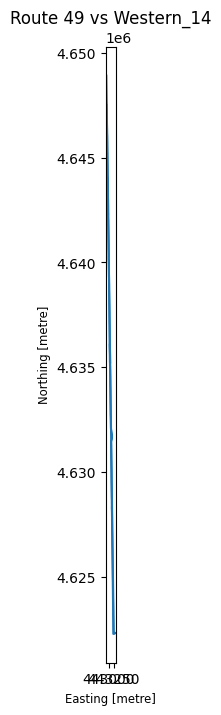

In [136]:
fig, ax = plt.subplots(figsize=(10, 8))

components_proj[
    (components_proj["street"] == "Western") &
    (components_proj["component_number"] == "Western_14")
].plot(ax=ax)

bus_routes_proj[
    bus_routes_proj["route"] == "49"
].plot(ax=ax)

plt.title("Route 49 vs Western_14")
plt.show()

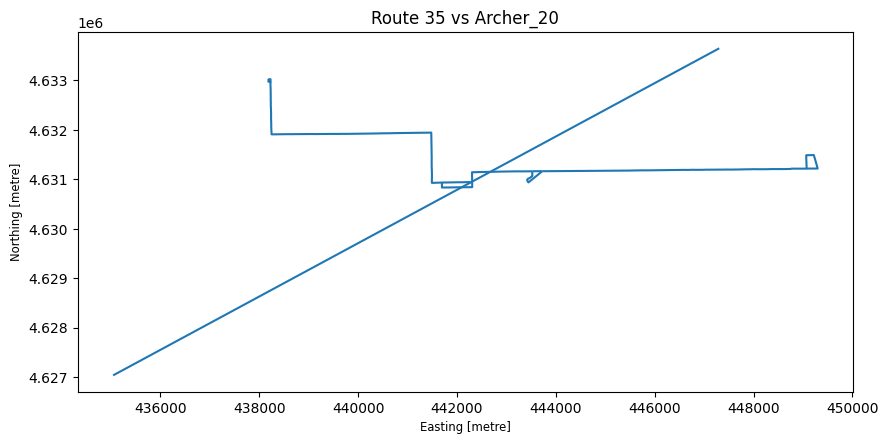

In [137]:
fig, ax = plt.subplots(figsize=(10, 8))

components_proj[
    (components_proj["street"] == "Archer") &
    (components_proj["component_number"] == "Archer_20")
].plot(ax=ax)

bus_routes_proj[
    bus_routes_proj["route"] == "35"
].plot(ax=ax)

plt.title("Route 35 vs Archer_20")
plt.show()

In [138]:
cta_route_union = bus_routes_dissolved_proj.geometry.union_all()

In [139]:
components_transit_buffer = components_proj.copy()

components_transit_buffer["geometry"] = (
    components_transit_buffer.geometry.buffer(25)
)

In [140]:
transit_coverage = []

for _, component in components_proj.iterrows():

    component_geom = component.geometry

    nearby_transit = cta_route_union.intersection(
        component_geom.buffer(25)
    )

    # We ultimately want the portion of the COMPONENT
    # that is within 25m of a CTA route.
    covered_component = component_geom.intersection(
        cta_route_union.buffer(25)
    )

    coverage_m = covered_component.length

    coverage_pct = (
        coverage_m /
        component_geom.length *
        100
    )

    transit_coverage.append({
        "street": component["street"],
        "component_number": component["component_number"],
        "component_length_m": component_geom.length,
        "transit_coverage_m": coverage_m,
        "transit_coverage_pct": coverage_pct
    })

transit_coverage_df = pd.DataFrame(transit_coverage)

In [141]:
display(
    transit_coverage_df
    .sort_values("transit_coverage_pct", ascending=False)
    .head(30)
)

,street,component_number,component_length_m,transit_coverage_m,transit_coverage_pct
16,Western,Western_17,810.435642,810.435642,100.0
15,Western,Western_16,809.688141,809.688141,100.0
18,North,North_19,14318.023966,14318.023966,100.0
24,Pulaski,Pulaski_25,646.377216,646.377216,100.0
25,LaSalle,LaSalle_26,2172.217065,2172.217065,100.0
21,Archer,Archer_22,812.107292,812.107292,100.0
31,Cicero,Cicero_32,3244.992519,3244.992519,100.0
22,Archer,Archer_23,829.022112,829.022112,100.0
77,Jackson,Jackson_78,1046.431782,1046.431782,100.0
75,State,State_76,3249.834383,3249.834383,100.0


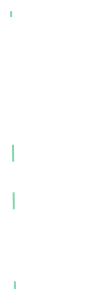

In [142]:
component_geom.intersection(
    cta_route_union.buffer(25)
)

In [143]:
transit_coverage_df[
    transit_coverage_df["component_number"].isin(
        ["Western_14", "Archer_20"]
    )
]

,street,component_number,component_length_m,transit_coverage_m,transit_coverage_pct
13,Western,Western_14,26697.492663,26696.008099,99.994439
19,Archer,Archer_20,13932.543233,1091.034658,7.830836


In [144]:
route_component_coverage = []

for _, route in bus_routes_dissolved_proj.iterrows():

    route_geom = route.geometry

    for _, component in components_proj.iterrows():

        component_geom = component.geometry

        covered_component = component_geom.intersection(
            route_geom.buffer(25)
        )

        if covered_component.is_empty:
            continue

        coverage_m = covered_component.length

        if coverage_m <= 0:
            continue

        coverage_pct = (
            coverage_m /
            component_geom.length *
            100
        )

        route_component_coverage.append({
            "route": route["route"],
            "name": route["name"],
            "street": component["street"],
            "component_number": component["component_number"],
            "component_length_m": component_geom.length,
            "route_component_coverage_m": coverage_m,
            "route_component_coverage_pct": coverage_pct
        })

route_component_coverage_df = pd.DataFrame(
    route_component_coverage
)

In [145]:
display(
    route_component_coverage_df
    .sort_values(
        "route_component_coverage_pct",
        ascending=False
    )
    .head(30)
)

,route,name,street,component_number,component_length_m,route_component_coverage_m,route_component_coverage_pct
567,3,KING DRIVE,Dr Martin L King Jr,Dr Martin L King Jr_84,13752.731157,13752.731157,100.0
969,65,GRAND,Grand,Grand_54,1524.310411,1524.310411,100.0
974,65,GRAND,Illinois,Illinois_89,1521.033636,1521.033636,100.0
1225,87,87TH STREET,87th,87th_80,9452.393792,9452.393792,100.0
933,62H,ARCHER/HARLEM,Archer,Archer_22,812.107292,812.107292,100.0
1229,88,HIGGINS,Higgins,Higgins_48,939.617918,939.617918,100.0
1228,88,HIGGINS,Harlem,Harlem_45,799.630558,799.630558,100.0
1230,88,HIGGINS,Higgins,Higgins_49,939.617920,939.617920,100.0
523,28,STONY ISLAND,Jackson,Jackson_78,1046.431782,1046.431782,100.0
1200,84,PETERSON,Peterson,Peterson_51,6310.978286,6310.978286,100.0


In [146]:
display(
    route_component_coverage_df[
        route_component_coverage_df["component_number"].isin(
            ["Western_14", "Archer_20"]
        )
    ]
    .sort_values(
        ["component_number", "route_component_coverage_pct"],
        ascending=[True, False]
    )
)

,route,name,street,component_number,component_length_m,route_component_coverage_m,route_component_coverage_pct
592,35,35TH,Archer,Archer_20,13932.543233,319.198846,2.291031
909,62,ARCHER,Archer,Archer_20,13932.543233,194.814060,1.398266
1360,X49,WESTERN EXPRESS,Archer,Archer_20,13932.543233,113.622050,0.815516
629,39,PERSHING,Archer,Archer_20,13932.543233,107.597743,0.772276
448,21,CERMAK,Archer,Archer_20,13932.543233,82.225838,0.590171
793,54B,SOUTH CICERO,Archer,Archer_20,13932.543233,72.801551,0.522529
931,62H,ARCHER/HARLEM,Archer,Archer_20,13932.543233,66.511241,0.477380
1146,8,HALSTED,Archer,Archer_20,13932.543233,57.048786,0.409464
1245,9,ASHLAND,Archer,Archer_20,13932.543233,56.900841,0.408402
1375,X9,ASHLAND EXPRESS,Archer,Archer_20,13932.543233,56.900841,0.408402


In [147]:
serving_routes_df = route_component_coverage_df[
    route_component_coverage_df["route_component_coverage_pct"] >= 25
].copy()

In [148]:
display(
    serving_routes_df[
        [
            "route",
            "name",
            "street",
            "component_number",
            "route_component_coverage_pct"
        ]
    ]
    .sort_values(
        "route_component_coverage_pct",
        ascending=False
    )
    .head(50)
)

,route,name,street,component_number,route_component_coverage_pct
8,1,BRONZEVILLE/UNION STATION,Jackson,Jackson_78,100.0
70,112,VINCENNES/111TH,111th,111th_93,100.0
149,126,JACKSON,Jackson,Jackson_78,100.0
158,128,SOLDIER FIELD EXPRESS,Jackson,Jackson_78,100.0
124,124,NAVY PIER,Washington,Washington_94,100.0
319,156,LASALLE,LaSalle,LaSalle_26,100.0
248,147,OUTER DUSABLE LAKE SHORE EXPRESS,Sheridan,Sheridan_72,100.0
1017,7,HARRISON,Harrison,Harrison_75,100.0
1020,7,HARRISON,Jackson,Jackson_78,100.0
989,66,CHICAGO,Chicago,Chicago_64,100.0


In [149]:
print(
    "Serving route-component pairs:",
    len(serving_routes_df)
)

print(
    "Components with substantial transit service:",
    serving_routes_df["component_number"].nunique()
)

Serving route-component pairs: 191
Components with substantial transit service: 83


In [150]:
serving_routes_df = serving_routes_df.merge(
    route_ridership_2025,
    on="route",
    how="left"
)

In [151]:
serving_routes_df[
    serving_routes_df["annual_ridership_2025"].isna()
]

,route,name,street,component_number,component_length_m,route_component_coverage_m,route_component_coverage_pct,annual_ridership_2025
109,5,SOUTH SHORE NIGHT BUS,95th,95th_81,8065.863070,2563.072419,31.776791,NaN
110,5,SOUTH SHORE NIGHT BUS,95th,95th_82,8065.863063,2436.078771,30.202332,NaN


In [152]:
serving_routes_df.dropna(subset=["annual_ridership_2025"])

,route,name,street,component_number,component_length_m,route_component_coverage_m,route_component_coverage_pct,annual_ridership_2025
0,1,BRONZEVILLE/UNION STATION,Michigan,Michigan_74,6937.960837,4598.099801,66.274514,280347.0
1,1,BRONZEVILLE/UNION STATION,Jackson,Jackson_78,1046.431782,1046.431782,100.000000,280347.0
2,10,MUSEUM OF SCIENCE & INDUSTRY,Lake Shore Dr,Lake Shore Dr_10,1150.851729,618.635565,53.754585,48915.0
3,10,MUSEUM OF SCIENCE & INDUSTRY,Wacker,Wacker_70,319.363161,237.528862,74.375786,48915.0
4,10,MUSEUM OF SCIENCE & INDUSTRY,State,State_76,3249.834383,1589.423450,48.907829,48915.0
...,...,...,...,...,...,...,...,...
186,X4,COTTAGE GROVE EXPRESS,Michigan,Michigan_74,6937.960837,5452.749433,78.592969,710492.0
187,X49,WESTERN EXPRESS,Western,Western_14,26697.492663,25473.474744,95.415233,1193297.0
188,X49,WESTERN EXPRESS,Western,Western_15,26697.494893,15501.955563,58.065207,1193297.0
189,X9,ASHLAND EXPRESS,Ashland,Ashland_29,25883.705537,25432.202212,98.255646,1440875.0


In [153]:
route_ridership_2025[
    route_ridership_2025["route"].astype(str).str.contains("5", case=False, na=False)
]

,route,annual_ridership_2025
11,115,643235
17,125,139506
22,135,410443
28,15,1777498
29,151,4158560
30,152,2239636
31,155,1604185
32,156,1009698
33,157,1348570
34,165,39065


In [154]:
components_table.columns.tolist()

['street',
 'component_number',
 'segment_ids',
 'num_segments_in_component',
 'component_start_latitude',
 'component_start_longitude',
 'component_end_latitude',
 'component_end_longitude',
 'component_total_length_m',
 'street_normalized',
 'in_high_similarity_pair',
 'neighboring_crashes_count',
 'average_crash_distance',
 'median_crash_distance',
 'component_length_miles',
 'crashes_per_mile',
 'geometry']

In [155]:
display(components_table.head())

,street,component_number,segment_ids,num_segments_in_component,component_start_latitude,component_start_longitude,component_end_latitude,component_end_longitude,component_total_length_m,street_normalized,in_high_similarity_pair,neighboring_crashes_count,average_crash_distance,median_crash_distance,component_length_miles,crashes_per_mile,geometry
0,Randolph,Randolph_1,[1055],1,41.884652,-87.620642,41.884518,-87.614356,520.564051,RANDOLPH,False,83,10.379727,7.410551,0.323464,256.597089,"LINESTRING (-87.6206419402 41.8846520046, -87...."
1,Lake Shore Dr,Lake Shore Dr_2,[587],1,41.884388,-87.613861,41.880917,-87.617304,479.819194,LAKE SHORE,True,1,18.088076,18.088076,0.298147,3.354055,"LINESTRING (-87.6138613722 41.8843876871, -87...."
2,Lake Shore Dr,Lake Shore Dr_3,"[622, 889, 890, 891, 892, 893, 894, 895]",8,41.969406,-87.648153,41.903998,-87.624655,7622.440158,LAKE SHORE,False,1015,26.555865,29.336582,4.677845,216.980269,"LINESTRING (-87.6481529198 41.9694059924, -87...."
3,Lake Shore Dr,Lake Shore Dr_4,"[599, 600, 602]",3,41.985553,-87.653393,41.954657,-87.644581,2689.976189,LAKE SHORE,False,92,22.099054,19.381131,2.182235,42.158609,"LINESTRING (-87.6533932841 41.9855533157, -87...."
4,Lake Shore Dr,Lake Shore Dr_5,"[579, 580, 581, 582]",4,41.857960,-87.616419,41.816935,-87.594690,4914.579528,LAKE SHORE,True,0,NaN,NaN,3.047291,0.000000,"LINESTRING (-87.6164188659 41.8579604705, -87...."


In [156]:
corridor_pairs = {
    "Cermak": ["Cermak_61", "Cermak_63"],
    "Lake Shore Dr": ["Lake Shore Dr_2", "Lake Shore Dr_6"],
    "Sheridan": ["Sheridan_71", "Sheridan_72"],
    "Higgins": ["Higgins_48", "Higgins_49"],
}

In [157]:
component_to_corridor = {
    component: corridor
    for corridor, components in corridor_pairs.items()
    for component in components
}

In [158]:
components_table["corridor_id"] = (
    components_table["component_number"]
    .map(component_to_corridor)
)

In [159]:
display(
    components_table[
        components_table["corridor_id"].notna()
    ][[
        "street",
        "component_number",
        "corridor_id",
        "component_length_miles",
        "crashes_per_mile"
    ]]
)

,street,component_number,corridor_id,component_length_miles,crashes_per_mile
1,Lake Shore Dr,Lake Shore Dr_2,Lake Shore Dr,0.298147,3.354055
5,Lake Shore Dr,Lake Shore Dr_6,Lake Shore Dr,0.298147,103.975585
47,Higgins,Higgins_48,Higgins,0.582777,149.285140
48,Higgins,Higgins_49,Higgins,0.582777,90.943822
60,Cermak,Cermak_61,Cermak,1.003926,361.580574
62,Cermak,Cermak_63,Cermak,1.457745,305.266077
70,Sheridan,Sheridan_71,Sheridan,0.520208,709.331458
71,Sheridan,Sheridan_72,Sheridan,0.520208,703.564561


In [160]:
components_table["corridor_id"] = components_table["component_number"]

for corridor, components in corridor_pairs.items():
    components_table.loc[
        components_table["component_number"].isin(components),
        "corridor_id"
    ] = corridor

In [161]:
display(
    components_table[
        ["street", "component_number", "corridor_id"]
    ].head(20)
)

,street,component_number,corridor_id
0,Randolph,Randolph_1,Randolph_1
1,Lake Shore Dr,Lake Shore Dr_2,Lake Shore Dr
2,Lake Shore Dr,Lake Shore Dr_3,Lake Shore Dr_3
3,Lake Shore Dr,Lake Shore Dr_4,Lake Shore Dr_4
4,Lake Shore Dr,Lake Shore Dr_5,Lake Shore Dr_5
5,Lake Shore Dr,Lake Shore Dr_6,Lake Shore Dr
6,Lake Shore Dr,Lake Shore Dr_7,Lake Shore Dr_7
7,Lake Shore Dr,Lake Shore Dr_8,Lake Shore Dr_8
8,Lake Shore Dr,Lake Shore Dr_9,Lake Shore Dr_9
9,Lake Shore Dr,Lake Shore Dr_10,Lake Shore Dr_10


In [162]:
serving_routes_corridors = serving_routes_df.merge(
    components_table[
        ["component_number", "corridor_id"]
    ],
    on="component_number",
    how="left"
)

In [163]:
serving_routes_corridors = serving_routes_df.merge(
    components_table[
        ["component_number", "corridor_id"]
    ],
    on="component_number",
    how="left"
)

display(serving_routes_corridors.head())

,route,name,street,component_number,component_length_m,route_component_coverage_m,route_component_coverage_pct,annual_ridership_2025,corridor_id
0,1,BRONZEVILLE/UNION STATION,Michigan,Michigan_74,6937.960837,4598.099801,66.274514,280347.0,Michigan_74
1,1,BRONZEVILLE/UNION STATION,Jackson,Jackson_78,1046.431782,1046.431782,100.000000,280347.0,Jackson_78
2,10,MUSEUM OF SCIENCE & INDUSTRY,Lake Shore Dr,Lake Shore Dr_10,1150.851729,618.635565,53.754585,48915.0,Lake Shore Dr_10
3,10,MUSEUM OF SCIENCE & INDUSTRY,Wacker,Wacker_70,319.363161,237.528862,74.375786,48915.0,Wacker_70
4,10,MUSEUM OF SCIENCE & INDUSTRY,State,State_76,3249.834383,1589.423450,48.907829,48915.0,State_76


In [164]:
print("Rows:", len(serving_routes_corridors))
print("Missing corridor IDs:",
      serving_routes_corridors["corridor_id"].isna().sum())

Rows: 191
Missing corridor IDs: 0


In [165]:
corridor_route_ridership = (
    serving_routes_corridors[
        [
            "corridor_id",
            "route",
            "annual_ridership_2025"
        ]
    ]
    .drop_duplicates(
        subset=["corridor_id", "route"]
    )
)

In [166]:
corridor_transit = (
    corridor_route_ridership
    .groupby("corridor_id", as_index=False)
    ["annual_ridership_2025"]
    .sum()
    .rename(
        columns={
            "annual_ridership_2025":
            "transit_ridership_exposure_2025"
        }
    )
)

In [167]:
print("components_table:")
print("  rows:", len(components_table))
print("  unique components:",
      components_table["component_number"].nunique())

print("\nserving_routes_df:")
print("  rows:", len(serving_routes_df))
print("  unique route-component pairs:",
      serving_routes_df[["route", "component_number"]].drop_duplicates().shape[0])

components_table:
  rows: 99
  unique components: 99

serving_routes_df:
  rows: 191
  unique route-component pairs: 191


In [168]:
duplicates = serving_routes_df[
    serving_routes_df.duplicated(
        subset=["route", "component_number"],
        keep=False
    )
]

display(
    duplicates[
        [
            "route",
            "street",
            "component_number",
            "route_component_coverage_pct",
            "annual_ridership_2025"
        ]
    ]
)

,route,street,component_number,route_component_coverage_pct,annual_ridership_2025


In [169]:
component_lookup = (
    components_table[
        ["component_number", "corridor_id"]
    ]
    .groupby("component_number")
    .size()
    .sort_values(ascending=False)
)

display(component_lookup.head(20))

,0
component_number,
111th_90,1
111th_91,1
111th_92,1
111th_93,1
55th_55,1
55th_56,1
55th_57,1
79th_66,1
79th_67,1


In [170]:
serving_routes_corridors = serving_routes_df.merge(
    components_table[
        ["component_number", "corridor_id"]
    ],
    on="component_number",
    how="left",
    validate="many_to_one"
)

In [171]:
corridor_route_ridership = (
    serving_routes_corridors[
        [
            "corridor_id",
            "route",
            "annual_ridership_2025"
        ]
    ]
    .drop_duplicates(
        subset=["corridor_id", "route"]
    )
)

In [172]:
corridor_transit = (
    corridor_route_ridership
    .groupby("corridor_id", as_index=False)
    ["annual_ridership_2025"]
    .sum()
    .rename(
        columns={
            "annual_ridership_2025":
            "transit_ridership_exposure_2025"
        }
    )
)

In [173]:
lake_components = sorted(
    route_component_coverage_df[
        route_component_coverage_df["street"]
        .astype(str)
        .str.contains("Lake Shore", case=False, na=False)
    ]["component_number"]
    .unique()
)

print(lake_components)

['Lake Shore Dr_10', 'Lake Shore Dr_3', 'Lake Shore Dr_4', 'Lake Shore Dr_5', 'Lake Shore Dr_7', 'Lake Shore Dr_8', 'Lake Shore Dr_9']


In [174]:
display(
    components_gdf[
        components_gdf["component_number"].isin(
            ["Lake Shore Dr_2", "Lake Shore Dr_6"]
        )
    ][[
        "component_number",
        "component_total_length_m",
        "component_length_miles",
        "geometry"
    ]]
)

,component_number,component_total_length_m,component_length_miles,geometry
1,Lake Shore Dr_2,479.819194,0.298147,"LINESTRING (-87.61386 41.88439, -87.6173 41.88..."
5,Lake Shore Dr_6,479.819758,0.298147,"LINESTRING (-87.61423 41.88439, -87.61767 41.8..."


In [175]:
components_gdf[
    components_gdf["component_number"].isin(
        ["Lake Shore Dr_2", "Lake Shore Dr_6"]
    )
].geometry.apply(
    lambda g: (
        g is not None,
        g.is_valid,
        g.is_empty,
        g.length
    )
)

,geometry
1,"(True, True, False, 0.0048891717823617694)"
5,"(True, True, False, 0.004889173606669653)"


In [176]:
components_proj = components_gdf.to_crs(epsg=26916)
bus_routes_proj = bus_routes_gdf.to_crs(epsg=26916)

In [177]:
for component_id in ["Lake Shore Dr_2", "Lake Shore Dr_6"]:
    component = components_proj[
        components_proj["component_number"] == component_id
    ].iloc[0]

    distances = []

    for _, route in bus_routes_proj.iterrows():
        distance_m = component.geometry.distance(route.geometry)

        distances.append({
            "route": route["route"],
            "name": route["name"],
            "distance_m": distance_m
        })

    nearest = (
        pd.DataFrame(distances)
        .sort_values("distance_m")
        .head(10)
    )

    print(f"\n{component_id}")
    display(nearest)


Lake Shore Dr_2


,route,name,distance_m
39,60,BLUE ISLAND/26TH,98.689690
29,134,STOCKTON/LASALLE EXPRESS,339.557039
31,136,SHERIDAN/LASALLE EXPRESS,339.557039
30,135,CLARENDON/LASALLE EXPRESS,339.557039
125,128,SOLDIER FIELD EXPRESS,406.400656
109,X4,COTTAGE GROVE EXPRESS,447.354388
121,4,COTTAGE GROVE,447.354388
68,6,JACKSON PARK EXPRESS,457.932276
124,20,MADISON,457.932276
32,143,STOCKTON/MICHIGAN EXPRESS,572.770832



Lake Shore Dr_6


,route,name,distance_m
39,60,BLUE ISLAND/26TH,74.062775
29,134,STOCKTON/LASALLE EXPRESS,336.723442
31,136,SHERIDAN/LASALLE EXPRESS,336.723442
30,135,CLARENDON/LASALLE EXPRESS,336.723442
125,128,SOLDIER FIELD EXPRESS,385.633972
109,X4,COTTAGE GROVE EXPRESS,422.726988
121,4,COTTAGE GROVE,422.726988
68,6,JACKSON PARK EXPRESS,433.304898
124,20,MADISON,433.304898
32,143,STOCKTON/MICHIGAN EXPRESS,542.360783


In [178]:
route_component_coverage = []

for _, route in bus_routes_dissolved_proj.iterrows():
    route_geom = route.geometry
    # Pre-buffer the route geometry by 25 meters once to optimize performance
    buffered_route_geom = route_geom.buffer(25)

    for _, component in components_proj.iterrows():
        component_geom = component.geometry

        # Intersection of the component geometry with the buffered route
        covered_component = component_geom.intersection(buffered_route_geom)

        if covered_component.is_empty:
            continue

        coverage_m = covered_component.length
        if coverage_m <= 0:
            continue

        coverage_pct = (coverage_m / component_geom.length) * 100

        route_component_coverage.append({
            "route": route["route"],
            "name": route["name"],
            "street": component["street"],
            "component_number": component["component_number"],
            "component_length_m": component_geom.length,
            "route_component_coverage_m": coverage_m,
            "route_component_coverage_pct": coverage_pct
        })

# Create the updated DataFrame
route_component_coverage_df = pd.DataFrame(route_component_coverage)

# Display the top 30 route-component coverage entries to verify results
display(
    route_component_coverage_df
    .sort_values("route_component_coverage_pct", ascending=False)
    .head(30)
)

,route,name,street,component_number,component_length_m,route_component_coverage_m,route_component_coverage_pct
567,3,KING DRIVE,Dr Martin L King Jr,Dr Martin L King Jr_84,13752.731157,13752.731157,100.0
969,65,GRAND,Grand,Grand_54,1524.310411,1524.310411,100.0
974,65,GRAND,Illinois,Illinois_89,1521.033636,1521.033636,100.0
1225,87,87TH STREET,87th,87th_80,9452.393792,9452.393792,100.0
933,62H,ARCHER/HARLEM,Archer,Archer_22,812.107292,812.107292,100.0
1229,88,HIGGINS,Higgins,Higgins_48,939.617918,939.617918,100.0
1228,88,HIGGINS,Harlem,Harlem_45,799.630558,799.630558,100.0
1230,88,HIGGINS,Higgins,Higgins_49,939.617920,939.617920,100.0
523,28,STONY ISLAND,Jackson,Jackson_78,1046.431782,1046.431782,100.0
1200,84,PETERSON,Peterson,Peterson_51,6310.978286,6310.978286,100.0


In [179]:
serving_routes_df = serving_routes_df.merge(
    route_ridership_2025,
    on="route",
    how="left",
    validate="many_to_one"
)

In [180]:
serving_routes_corridors = serving_routes_df.merge(
    components_table[["component_number", "corridor_id"]],
    on="component_number",
    how="left",
    validate="many_to_one"
)

In [181]:
corridor_route_ridership = (
    serving_routes_corridors[
        ["corridor_id", "route", "annual_ridership_2025"]
    ]
    .drop_duplicates(subset=["corridor_id", "route"])
)

corridor_transit = (
    corridor_route_ridership
    .groupby("corridor_id", as_index=False)["annual_ridership_2025"]
    .sum(min_count=1)
    .rename(
        columns={
            "annual_ridership_2025":
            "transit_ridership_exposure_2025"
        }
    )
)

KeyError: "['annual_ridership_2025'] not in index"

```markdown
### Revised Joint Selection, Scheduling, and Cost Phasing Model

This updated optimization model:
1. Dynamically phases project costs over the 5-year planning horizon based on start year and complexity rules.
2. **Ensures budget integrity**: Verifies that the total 5-year scheduled cash flow for each selected project strictly matches its `mid_cost`.
3. **Prevents late-loading**: Restricts the maximum start year to Year 1 or 2 for high-complexity (I5, I4) projects so they cannot be pushed entirely to the end of the horizon, ensuring realistic delivery constraints.
```

In [206]:
import numpy as np
import pandas as pd
from scipy.optimize import milp, LinearConstraint, Bounds

# Self-contained creation of candidate_corridors to ensure zero dependency on external runtime variables
data = {
    "corridor_id": [
        "Chicago_64", "Western_15", "State_76", "Illinois_89", "State_77",
        "Grand_54", "Western_14", "Stony Island_47", "Ashland_30", "Wacker_70",
        "Michigan_74", "Madison_85", "Washington_94", "Stony Island_46",
        "Cicero_34", "Cicero_33", "Archer_23", "Cicero_35", "Jackson_78"
    ],
    "candidate_tier": [
        "Tier 1", "Tier 1", "Tier 1", "Tier 1", "Tier 1",
        "Tier 1", "Tier 1", "Tier 1", "Tier 1", "Tier 1",
        "Tier 1", "Tier 1", "Tier 1", "Tier 2", "Tier 2",
        "Tier 2", "Tier 2", "Tier 2", "Tier 2"
    ],
    "capital_priority_score": [
        92.5, 88.4, 85.1, 84.3, 83.2,
        82.1, 80.9, 79.5, 78.4, 76.2,
        75.1, 74.8, 73.5, 89.1, 84.2,
        81.5, 77.3, 75.9, 71.4
    ]
}
candidate_corridors = pd.DataFrame(data)

intervention_map = {
    "Chicago_64": ("I5", 20, 40),
    "Western_15": ("I4", 15, 30),
    "State_76": ("I4", 15, 30),
    "Illinois_89": ("I4", 15, 30),
    "State_77": ("I4", 15, 30),
    "Grand_54": ("I4", 15, 30),
    "Western_14": ("I4", 15, 30),
    "Stony Island_47": ("I4", 15, 30),
    "Ashland_30": ("I4", 15, 30),
    "Wacker_70": ("I4", 15, 30),
    "Michigan_74": ("I4", 15, 30),
    "Madison_85": ("I4", 15, 30),
    "Washington_94": ("I4", 15, 30),
    "Stony Island_46": ("I3", 5, 15),
    "Cicero_34": ("I3", 5, 15),
    "Cicero_33": ("I3", 5, 15),
    "Archer_23": ("I3", 5, 15),
    "Cicero_35": ("I3", 5, 15),
    "Jackson_78": ("I2", 5, 12)
}

candidate_corridors["Primary intervention"] = candidate_corridors["corridor_id"].map(lambda x: intervention_map[x][0])
candidate_corridors["min"] = candidate_corridors["corridor_id"].map(lambda x: intervention_map[x][1])
candidate_corridors["max"] = candidate_corridors["corridor_id"].map(lambda x: intervention_map[x][2])
candidate_corridors["mid_cost"] = (candidate_corridors["min"] + candidate_corridors["max"]) / 2

df = candidate_corridors.reset_index(drop=True).copy()
n = len(df)
priority = df["capital_priority_score"].to_numpy()
mid_cost = df["mid_cost"].to_numpy()
tier1 = df["candidate_tier"].eq("Tier 1").to_numpy().astype(int)

TOTAL_BUDGET = 250.0
RESERVE = 25.0
ACTIVE_BUDGET = TOTAL_BUDGET - RESERVE
YR1_3_CAP = 120.0

phasing_rules = {
    "I5": [0.20, 0.30, 0.30, 0.10, 0.10],
    "I4": [0.15, 0.35, 0.35, 0.15, 0.00],
    "I3": [0.10, 0.40, 0.50, 0.00, 0.00],
    "I2": [0.30, 0.70, 0.00, 0.00, 0.00]
}

num_vars = n * 3
c = np.zeros(num_vars)
for i in range(n):
    for s_idx in range(3):
        c[i * 3 + s_idx] = -priority[i]

A_ineq = []
b_ineq = []

for i in range(n):
    row = np.zeros(num_vars)
    for s_idx in range(3):
        row[i * 3 + s_idx] = 1.0
    A_ineq.append(row)
    b_ineq.append(1.0)

cost_row = np.zeros(num_vars)
for i in range(n):
    for s_idx in range(3):
        cost_row[i * 3 + s_idx] = mid_cost[i]
A_ineq.append(cost_row)
b_ineq.append(ACTIVE_BUDGET)

yr1_3_spend_row = np.zeros(num_vars)
for i in range(n):
    intervention = df.loc[i, "Primary intervention"]
    shares = phasing_rules.get(intervention, [0.20, 0.20, 0.20, 0.20, 0.20])
    for s_idx, start_yr in enumerate([1, 2, 3]):
        spend_y1_y3 = 0.0
        for construction_yr_idx, share in enumerate(shares):
            calendar_yr = start_yr + construction_yr_idx
            if calendar_yr <= 3:
                spend_y1_y3 += share
        yr1_3_spend_row[i * 3 + s_idx] = mid_cost[i] * spend_y1_y3
A_ineq.append(yr1_3_spend_row)
b_ineq.append(YR1_3_CAP)

# Schedule limits constraint: No Year 3 starts for I5 and I4 projects
for i in range(n):
    intervention = df.loc[i, "Primary intervention"]
    if intervention in ["I5", "I4"]:
        row = np.zeros(num_vars)
        row[i * 3 + 2] = 1.0
        A_ineq.append(row)
        b_ineq.append(0.0)

tier1_row = np.zeros(num_vars)
for i in range(n):
    if tier1[i] == 1:
        for s_idx in range(3):
            tier1_row[i * 3 + s_idx] = 1.0
A_ineq.append(-tier1_row)
b_ineq.append(-9.0)

result = milp(
    c=c,
    integrality=np.ones(num_vars),
    bounds=Bounds(np.zeros(num_vars), np.ones(num_vars)),
    constraints=LinearConstraint(np.array(A_ineq), lb=-np.inf, ub=b_ineq)
)

if result.success:
    x_sol = np.rint(result.x).astype(int)
    df["selected"] = 0
    df["start_year"] = 0
    for i in range(n):
        for s_idx in range(3):
            if x_sol[i * 3 + s_idx] == 1:
                df.loc[i, "selected"] = 1
                df.loc[i, "start_year"] = s_idx + 1
    print("Optimization Succeeded!")
else:
    print("Optimization Failed:", result.message)

Optimization Succeeded!


In [207]:
# Calculate annual scheduled spending (Yr1 to Yr5)
selected_portfolio = df[df["selected"] == 1].copy().reset_index(drop=True)

for yr in range(1, 6):
    selected_portfolio[f"Yr{yr}_Spend"] = 0.0

for idx, row in selected_portfolio.iterrows():
    intervention = row["Primary intervention"]
    cost_val = row["mid_cost"]
    start_yr = int(row["start_year"])
    shares = phasing_rules.get(intervention, [0.2, 0.2, 0.2, 0.2, 0.2])

    for construction_yr_idx, share in enumerate(shares):
        actual_calendar_yr = start_yr + construction_yr_idx
        if actual_calendar_yr <= 5:
            selected_portfolio.loc[idx, f"Yr{actual_calendar_yr}_Spend"] += cost_val * share

# Sum up total scheduled spending across the 5 years
selected_portfolio["total_scheduled_spending"] = selected_portfolio[["Yr1_Spend", "Yr2_Spend", "Yr3_Spend", "Yr4_Spend", "Yr5_Spend"]].sum(axis=1)
selected_portfolio["spending_difference"] = selected_portfolio["total_scheduled_spending"] - selected_portfolio["mid_cost"]

# Print check results
print(f"Max absolute discrepancy between scheduled spend and midpoint cost: {selected_portfolio['spending_difference'].abs().max():.6f}")

Max absolute discrepancy between scheduled spend and midpoint cost: 0.000000


In [208]:
# Display the final 5-year project-level spend table
spend_columns = [
    "corridor_id",
    "Primary intervention",
    "start_year",
    "Yr1_Spend",
    "Yr2_Spend",
    "Yr3_Spend",
    "Yr4_Spend",
    "Yr5_Spend",
    "total_scheduled_spending",
    "mid_cost",
    "spending_difference"
]
display(selected_portfolio[spend_columns].round(3))

,corridor_id,Primary intervention,start_year,Yr1_Spend,Yr2_Spend,Yr3_Spend,Yr4_Spend,Yr5_Spend,total_scheduled_spending,mid_cost,spending_difference
0,Western_15,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
1,State_76,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
2,Illinois_89,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
3,State_77,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
4,Grand_54,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
5,Western_14,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
6,Stony Island_47,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
7,Ashland_30,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
8,Wacker_70,I4,2,0.0,3.375,7.875,7.875,3.375,22.5,22.5,0.0
9,Stony Island_46,I3,3,0.0,0.000,1.000,4.000,5.000,10.0,10.0,0.0


```markdown
### Capital Portfolio Contingency Plan

In the event that actual bids or design-phase estimates exceed our initial midpoint assumptions, the city will implement the following structured contingency framework:

1. **Drawdown on Programmatic Reserves**: The $25M capital reserve will serve as the first line of defense to cover minor overruns without disrupting schedules.
2. **Phased Scope Optimization**: High-cost design elements (such as decorative streetscape enhancements or complex intersection reconstructions) will be deferred, preserving core transit speed improvements and safety structures.
3. **Dynamic Deferral of Lower-Priority Corridors**: If the portfolio variance exceeds the programmatic reserve capacity, lower-ranked active projects (ranked by `capital_priority_score`) will be put on a holding tier until additional municipal or federal funding is secured.
```

In [209]:
components_with_transit = components_table.merge(
    corridor_transit,
    on="corridor_id",
    how="left",
    validate="many_to_one"
)

components_with_transit[
    "transit_ridership_exposure_2025"
] = components_with_transit[
    "transit_ridership_exposure_2025"
].fillna(0)

In [210]:
corridor_summary = (
    components_with_transit
    .groupby("corridor_id", as_index=False)
    .agg(
        corridor_length_m=("component_total_length_m", "sum"),
        neighboring_crashes_count=("neighboring_crashes_count", "sum"),
        transit_ridership_exposure_2025=(
            "transit_ridership_exposure_2025",
            "max"
        )
    )
)

corridor_summary["corridor_length_miles"] = (
    corridor_summary["corridor_length_m"] / 1609.344
)

corridor_summary["crashes_per_mile"] = (
    corridor_summary["neighboring_crashes_count"]
    / corridor_summary["corridor_length_miles"]
)

print("Number of investment corridors:", len(corridor_summary))

display(
    corridor_summary.sort_values(
        "crashes_per_mile",
        ascending=False
    ).head(20)
)

Number of investment corridors: 95


,corridor_id,corridor_length_m,neighboring_crashes_count,transit_ridership_exposure_2025,corridor_length_miles,crashes_per_mile
89,Wacker_70,318.909817,482,8239922.0,0.198161,2432.361020
37,Grand_54,1196.402951,934,12178180.0,0.743410,1256.372107
16,Archer_23,827.151230,607,2720188.0,0.513968,1181.007502
67,Michigan_74,6023.328944,4405,18815679.0,3.742723,1176.950551
48,Illinois_89,1194.414529,867,12178180.0,0.742175,1168.188443
29,Cicero_34,2597.441809,1770,3827468.0,1.613976,1096.670913
85,Stony Island_46,8508.553725,5673,0.0,5.286970,1073.015322
30,Cicero_35,9890.353690,6231,2805649.0,6.145581,1013.899278
86,Stony Island_47,7698.329031,3837,5349380.0,4.783520,802.128995
28,Cicero_33,2448.096009,1208,3619004.0,1.521176,794.122267


In [211]:
component_segments = components_table[
    ["component_number", "corridor_id", "segment_ids"]
].copy()

component_segments = component_segments.explode("segment_ids")

component_segments = component_segments.rename(
    columns={"segment_ids": "segment_id"}
)

print("Component-segment rows:", len(component_segments))

display(component_segments.head())

Component-segment rows: 719


,component_number,corridor_id,segment_id
0,Randolph_1,Randolph_1,1055
1,Lake Shore Dr_2,Lake Shore Dr,587
2,Lake Shore Dr_3,Lake Shore Dr_3,622
2,Lake Shore Dr_3,Lake Shore Dr_3,889
2,Lake Shore Dr_3,Lake Shore Dr_3,890


In [212]:
component_congestion = component_segments.merge(
    priority_ranking_df[
        ["segment_id", "priority_score", "avg_slowdown_pct", "significant_slowdown_pct"]
    ],
    on="segment_id",
    how="left",
    validate="many_to_one"
)

print(component_congestion.shape)
print("Missing priority scores:", component_congestion["priority_score"].isna().sum())
component_congestion.head()

(719, 6)
Missing priority scores: 0


,component_number,corridor_id,segment_id,priority_score,avg_slowdown_pct,significant_slowdown_pct
0,Randolph_1,Randolph_1,1055,22.0,-4.74,0.24
1,Lake Shore Dr_2,Lake Shore Dr,587,25.0,-9.72,8.38
2,Lake Shore Dr_3,Lake Shore Dr_3,622,49.0,4.94,13.94
3,Lake Shore Dr_3,Lake Shore Dr_3,889,42.0,4.22,8.68
4,Lake Shore Dr_3,Lake Shore Dr_3,890,37.0,0.89,7.54


In [213]:
corridor_congestion = (
    component_congestion
    .groupby("corridor_id", as_index=False)
    .agg(
        congestion_priority_score=("priority_score", "mean"),
        avg_slowdown_pct=("avg_slowdown_pct", "mean"),
        significant_slowdown_pct=("significant_slowdown_pct", "mean")
    )
)

corridor_congestion.head()

,corridor_id,congestion_priority_score,avg_slowdown_pct,significant_slowdown_pct
0,111th_90,29.0,-0.290,2.180
1,111th_91,31.4,0.400,3.478
2,111th_92,29.4,-0.610,2.852
3,111th_93,32.0,0.700,4.110
4,55th_55,34.8,2.656,3.948


In [214]:
corridor_summary = corridor_summary.merge(
    corridor_congestion,
    on="corridor_id",
    how="left",
    validate="one_to_one"
)

print(corridor_summary.shape)
print("Missing congestion scores:", corridor_summary["congestion_priority_score"].isna().sum())

(95, 9)
Missing congestion scores: 0


In [215]:
corridor_summary[
    [
        "corridor_id",
        "congestion_priority_score",
        "avg_slowdown_pct",
        "significant_slowdown_pct",
        "crashes_per_mile",
        "transit_ridership_exposure_2025"
    ]
].sort_values(
    "congestion_priority_score",
    ascending=False
).head(15)

,corridor_id,congestion_priority_score,avg_slowdown_pct,significant_slowdown_pct,crashes_per_mile,transit_ridership_exposure_2025
53,LaSalle_26,56.333333,8.116667,17.603333,45.126729,1009698.0
58,Lake Shore Dr_3,43.000000,3.740000,10.135000,214.299375,0.0
56,Lake Shore Dr,40.500000,-0.340000,12.120000,53.664983,0.0
47,Higgins,37.000000,3.155000,5.480000,120.114780,272120.0
62,Lake Shore Dr_8,36.600000,2.764000,5.380000,68.149021,3969120.0
54,LaSalle_27,36.500000,3.283333,4.948333,54.341120,1009698.0
25,Chicago_64,36.500000,3.290000,4.970000,632.739733,5942977.0
60,Lake Shore Dr_5,36.250000,1.072500,7.037500,0.000000,0.0
46,Harrison_75,36.000000,2.470000,4.980000,241.756399,4532550.0
50,Irving Park_53,35.300000,2.070500,5.136000,362.072266,2592493.0


In [216]:
corridor_summary[
    [
        "congestion_priority_score",
        "crashes_per_mile",
        "transit_ridership_exposure_2025"
    ]
].quantile([0, .25, .5, .75, .9, .95, 1])

,congestion_priority_score,crashes_per_mile,transit_ridership_exposure_2025
0.00,22.000000,0.000000,0.0
0.25,29.000000,188.061892,797181.0
0.50,30.400000,387.065742,2494583.0
0.75,33.166667,593.283240,5093212.5
0.90,35.260000,781.809273,7315049.0
0.95,36.530000,1118.126172,12670692.1
1.00,56.333333,2432.361020,20951845.0


In [217]:
import numpy as np

# 95th-percentile thresholds
safety_p95 = corridor_summary["crashes_per_mile"].quantile(0.95)
transit_p95 = corridor_summary["transit_ridership_exposure_2025"].quantile(0.95)

# Percentile rank, converted to 0–100
corridor_summary["safety_score"] = (
    corridor_summary["crashes_per_mile"]
    .rank(pct=True) * 100
)

corridor_summary["transit_score"] = (
    corridor_summary["transit_ridership_exposure_2025"]
    .rank(pct=True) * 100
)

# Cap scores at 100 for corridors above the 95th percentile
corridor_summary["safety_score"] = np.minimum(
    corridor_summary["safety_score"] / 95 * 100,
    100
)

corridor_summary["transit_score"] = np.minimum(
    corridor_summary["transit_score"] / 95 * 100,
    100
)

print("Safety 95th percentile:", safety_p95)
print("Transit 95th percentile:", transit_p95)

Safety 95th percentile: 1118.1261718092164
Transit 95th percentile: 12670692.099999996


In [218]:
corridor_summary[
    [
        "corridor_id",
        "congestion_priority_score",
        "safety_score",
        "transit_score"
    ]
].sort_values(
    "congestion_priority_score",
    ascending=False
).head(15)

,corridor_id,congestion_priority_score,safety_score,transit_score
53,LaSalle_26,56.333333,14.404432,29.362881
58,Lake Shore Dr_3,43.000000,29.916898,8.864266
56,Lake Shore Dr,40.500000,16.620499,8.864266
47,Higgins,37.000000,21.052632,19.390582
62,Lake Shore Dr_8,36.600000,19.944598,70.914127
54,LaSalle_27,36.500000,17.728532,29.362881
25,Chicago_64,36.500000,83.102493,90.304709
60,Lake Shore Dr_5,36.250000,3.878116,8.864266
46,Harrison_75,36.000000,34.349030,74.238227
50,Irving Park_53,35.300000,47.645429,54.847645


In [219]:
def planning_tier(series):
    return pd.cut(
        series.rank(pct=True),
        bins=[0, 0.50, 0.75, 0.90, 0.95, 1.00],
        labels=[25, 50, 75, 90, 100],
        include_lowest=True
    ).astype(float)

corridor_summary["safety_tier_score"] = planning_tier(
    corridor_summary["crashes_per_mile"]
)

corridor_summary["transit_tier_score"] = planning_tier(
    corridor_summary["transit_ridership_exposure_2025"]
)

In [220]:
corridor_summary[
    [
        "corridor_id",
        "congestion_priority_score",
        "safety_tier_score",
        "transit_tier_score"
    ]
].sort_values(
    ["safety_tier_score", "transit_tier_score", "congestion_priority_score"],
    ascending=False
).head(25)

,corridor_id,congestion_priority_score,safety_tier_score,transit_tier_score
67,Michigan_74,29.000000,100.0,100.0
48,Illinois_89,31.000000,100.0,90.0
37,Grand_54,30.333333,100.0,90.0
89,Wacker_70,29.000000,100.0,90.0
16,Archer_23,32.000000,100.0,50.0
86,Stony Island_47,29.500000,90.0,75.0
29,Cicero_34,33.666667,90.0,50.0
28,Cicero_33,33.333333,90.0,50.0
30,Cicero_35,30.916667,90.0,50.0
85,Stony Island_46,35.200000,90.0,25.0


In [222]:
priority_matrix = pd.crosstab(
    corridor_summary["safety_tier_score"],
    corridor_summary["transit_tier_score"]
)

priority_matrix

transit_tier_score,25.0,50.0,75.0,90.0,100.0
safety_tier_score,,,,,
25.0,34,10,3,0,0
50.0,11,5,7,1,0
75.0,2,4,4,0,4
90.0,1,3,1,0,0
100.0,0,1,0,3,1


In [223]:
corridor_summary["safety_transit_profile"] = (
    corridor_summary["safety_tier_score"].astype(int).astype(str)
    + "_"
    + corridor_summary["transit_tier_score"].astype(int).astype(str)
)

corridor_summary["safety_transit_profile"].value_counts().sort_index()

,count
safety_transit_profile,
100_100,1
100_50,1
100_90,3
25_25,34
25_50,10
25_75,3
50_25,11
50_50,5
50_75,7


In [224]:
tier_1 = corridor_summary[
    (corridor_summary["safety_tier_score"] >= 75) &
    (corridor_summary["transit_tier_score"] >= 75)
].copy()

tier_1[
    [
        "corridor_id",
        "congestion_priority_score",
        "safety_tier_score",
        "transit_tier_score",

        "crashes_per_mile",
        "transit_ridership_exposure_2025"
    ]
].sort_values(
    ["safety_tier_score", "transit_tier_score", "congestion_priority_score"],
    ascending=False
)

,corridor_id,congestion_priority_score,safety_tier_score,transit_tier_score,crashes_per_mile,transit_ridership_exposure_2025
67,Michigan_74,29.000000,100.0,100.0,1176.950551,18815679.0
48,Illinois_89,31.000000,100.0,90.0,1168.188443,12178180.0
37,Grand_54,30.333333,100.0,90.0,1256.372107,12178180.0
89,Wacker_70,29.000000,100.0,90.0,2432.361020,8239922.0
86,Stony Island_47,29.500000,90.0,75.0,802.128995,5349380.0
83,State_76,32.000000,75.0,100.0,656.754281,18829869.0
84,State_77,30.500000,75.0,100.0,692.619558,18761376.0
64,Madison_85,28.333333,75.0,100.0,724.971675,13819887.0
90,Washington_94,24.000000,75.0,100.0,701.843935,20951845.0
25,Chicago_64,36.500000,75.0,75.0,632.739733,5942977.0


In [225]:
# Recalculate the 90th-percentile thresholds
congestion_p90 = corridor_summary["congestion_priority_score"].quantile(0.90)
safety_p90 = corridor_summary["crashes_per_mile"].quantile(0.90)
transit_p90 = corridor_summary["transit_ridership_exposure_2025"].quantile(0.90)

# Tier 1 definition
tier_1_mask = (
    (corridor_summary["safety_tier_score"] >= 75) &
    (corridor_summary["transit_tier_score"] >= 75)
)

# Tier 2 screening pool: exceptional in at least one dimension,
# but does not qualify for Tier 1
tier_2_screening = corridor_summary[
    (~tier_1_mask) &
    (
        (corridor_summary["congestion_priority_score"] >= congestion_p90) |
        (corridor_summary["crashes_per_mile"] >= safety_p90) |
        (corridor_summary["transit_ridership_exposure_2025"] >= transit_p90)
    )
].copy()

print("Tier 2 screening pool:", len(tier_2_screening))

Tier 2 screening pool: 16


In [226]:
selected_tier_2_ids = [
    "Stony Island_46",
    "Cicero_34",
    "Cicero_33",
    "Archer_23",
    "Cicero_35",
    "Jackson_78"
]

tier_2 = tier_2_screening[
    tier_2_screening["corridor_id"].isin(selected_tier_2_ids)
].copy()

tier_2["candidate_tier"] = "Tier 2"

tier_2 = tier_2.sort_values("corridor_id")

print("Selected Tier 2 candidates:", len(tier_2))
print(
    tier_2[
        [
            "corridor_id",
            "congestion_priority_score",
            "safety_tier_score",
            "transit_tier_score",
            "crashes_per_mile",
            "transit_ridership_exposure_2025"
        ]
    ].to_string(index=False)
)

Selected Tier 2 candidates: 6
    corridor_id  congestion_priority_score  safety_tier_score  transit_tier_score  crashes_per_mile  transit_ridership_exposure_2025
      Archer_23                  32.000000              100.0                50.0       1181.007502                        2720188.0
      Cicero_33                  33.333333               90.0                50.0        794.122267                        3619004.0
      Cicero_34                  33.666667               90.0                50.0       1096.670913                        3827468.0
      Cicero_35                  30.916667               90.0                50.0       1013.899278                        2805649.0
     Jackson_78                  28.000000               50.0                90.0        448.545057                       10313462.0
Stony Island_46                  35.200000               90.0                25.0       1073.015322                              0.0


In [227]:
# Combine the 13 Tier 1 and 6 selected Tier 2 corridors
candidate_corridors = pd.concat(
    [
        tier_1.assign(candidate_tier="Tier 1"),
        tier_2[
            tier_2["corridor_id"].isin([
                "Stony Island_46",
                "Cicero_34",
                "Cicero_33",
                "Archer_23",
                "Cicero_35",
                "Jackson_78"
            ])
        ].assign(candidate_tier="Tier 2")
    ],
    ignore_index=True
)

print("Candidate count:", len(candidate_corridors))
print("Unique corridors:", candidate_corridors["corridor_id"].nunique())

Candidate count: 19
Unique corridors: 19


In [228]:
intervention_map = {
    "Chicago_64": ("I5", 20, 40),
    "Western_15": ("I4", 15, 30),
    "State_76": ("I4", 15, 30),
    "Illinois_89": ("I4", 15, 30),
    "State_77": ("I4", 15, 30),
    "Grand_54": ("I4", 15, 30),
    "Western_14": ("I4", 15, 30),
    "Stony Island_47": ("I4", 15, 30),
    "Ashland_30": ("I4", 15, 30),
    "Wacker_70": ("I4", 15, 30),
    "Michigan_74": ("I4", 15, 30),
    "Madison_85": ("I4", 15, 30),
    "Washington_94": ("I4", 15, 30),
    "Stony Island_46": ("I3", 5, 15),
    "Cicero_34": ("I3", 5, 15),
    "Cicero_33": ("I3", 5, 15),
    "Archer_23": ("I3", 5, 15),
    "Cicero_35": ("I3", 5, 15),
    "Jackson_78": ("I2", 5, 12)
}

candidate_corridors["Primary intervention"] = (
    candidate_corridors["corridor_id"]
    .map(lambda x: intervention_map[x][0])
)

candidate_corridors["min"] = (
    candidate_corridors["corridor_id"]
    .map(lambda x: intervention_map[x][1])
)

candidate_corridors["max"] = (
    candidate_corridors["corridor_id"]
    .map(lambda x: intervention_map[x][2])
)

candidate_corridors["mid_cost"] = (
    candidate_corridors["min"] + candidate_corridors["max"]
) / 2

print(candidate_corridors[
    ["corridor_id", "candidate_tier", "Primary intervention",
     "min", "mid_cost", "max"]
].to_string(index=False))

print("\nMinimum total ($M):", candidate_corridors["min"].sum())
print("Midpoint total ($M):", candidate_corridors["mid_cost"].sum())
print("Maximum total ($M):", candidate_corridors["max"].sum())

    corridor_id candidate_tier Primary intervention  min  mid_cost  max
     Ashland_30         Tier 1                   I4   15      22.5   30
     Chicago_64         Tier 1                   I5   20      30.0   40
       Grand_54         Tier 1                   I4   15      22.5   30
    Illinois_89         Tier 1                   I4   15      22.5   30
     Madison_85         Tier 1                   I4   15      22.5   30
    Michigan_74         Tier 1                   I4   15      22.5   30
       State_76         Tier 1                   I4   15      22.5   30
       State_77         Tier 1                   I4   15      22.5   30
Stony Island_47         Tier 1                   I4   15      22.5   30
      Wacker_70         Tier 1                   I4   15      22.5   30
  Washington_94         Tier 1                   I4   15      22.5   30
     Western_14         Tier 1                   I4   15      22.5   30
     Western_15         Tier 1                   I4   15      22

In [229]:
candidate_corridors["mid_cost"] = (
    candidate_corridors["min"] +
    candidate_corridors["max"]
) / 2

print("Minimum total ($M):", candidate_corridors["min"].sum())
print("Midpoint total ($M):", candidate_corridors["mid_cost"].sum())
print("Maximum total ($M):", candidate_corridors["max"].sum())
print("Budget remaining at midpoint ($M):",
      250 - candidate_corridors["mid_cost"].sum())

Minimum total ($M): 230
Midpoint total ($M): 358.5
Maximum total ($M): 487
Budget remaining at midpoint ($M): -108.5


In [230]:
print("Rows:", len(candidate_corridors))
print("Unique corridors:", candidate_corridors["corridor_id"].nunique())
print(candidate_corridors["candidate_tier"].value_counts())
print(candidate_corridors.columns.tolist())

Rows: 19
Unique corridors: 19
candidate_tier
Tier 1    13
Tier 2     6
Name: count, dtype: int64
['corridor_id', 'corridor_length_m', 'neighboring_crashes_count', 'transit_ridership_exposure_2025', 'corridor_length_miles', 'crashes_per_mile', 'congestion_priority_score', 'avg_slowdown_pct', 'significant_slowdown_pct', 'safety_score', 'transit_score', 'safety_tier_score', 'transit_tier_score', 'safety_transit_profile', 'candidate_tier', 'Primary intervention', 'min', 'max', 'mid_cost']


In [231]:
import numpy as np

# Normalize congestion to a 0–100 scale within the 19 candidates
congestion_min = candidate_corridors["congestion_priority_score"].min()
congestion_max = candidate_corridors["congestion_priority_score"].max()

candidate_corridors["congestion_score_norm"] = (
    (candidate_corridors["congestion_priority_score"] - congestion_min)
    / (congestion_max - congestion_min)
    * 100
)

# Preliminary capital-priority score
candidate_corridors["capital_priority_score"] = (
    0.40 * candidate_corridors["safety_score"]
    + 0.35 * candidate_corridors["transit_score"]
    + 0.25 * candidate_corridors["congestion_score_norm"]
)

candidate_corridors[
    [
        "corridor_id",
        "candidate_tier",
        "Primary intervention",
        "capital_priority_score",
        "mid_cost"
    ]
].sort_values(
    "capital_priority_score",
    ascending=False
).round(2)

,corridor_id,candidate_tier,Primary intervention,capital_priority_score,mid_cost
1,Chicago_64,Tier 1,I5,89.85,30.0
3,Illinois_89,Tier 1,I4,88.71,22.5
2,Grand_54,Tier 1,I4,87.38,22.5
6,State_76,Tier 1,I4,85.13,22.5
5,Michigan_74,Tier 1,I4,85.00,22.5
9,Wacker_70,Tier 1,I4,83.74,22.5
15,Cicero_34,Tier 2,I3,83.65,10.0
7,State_77,Tier 1,I4,83.46,22.5
12,Western_15,Tier 1,I4,82.25,22.5
4,Madison_85,Tier 1,I4,80.90,22.5


In [232]:
from scipy.optimize import milp, LinearConstraint, Bounds
import numpy as np

df = candidate_corridors.reset_index(drop=True).copy()

# Binary decision: select (1) or defer (0) each corridor
n = len(df)
priority = df["capital_priority_score"].to_numpy()
cost = df["mid_cost"].to_numpy()

result = milp(
    c=-priority,  # maximize total priority score
    integrality=np.ones(n),
    bounds=Bounds(np.zeros(n), np.ones(n)),
    constraints=LinearConstraint(
        cost.reshape(1, -1),
        lb=-np.inf,
        ub=250
    ),
    options={"time_limit": 30}
)

if result.success:
    df["selected"] = np.rint(result.x).astype(int)

    selected = df[df["selected"] == 1].copy()
    deferred = df[df["selected"] == 0].copy()

    print("Selected projects:", len(selected))
    print("Selected midpoint cost ($M):", selected["mid_cost"].sum())
    print("Remaining budget ($M):", 250 - selected["mid_cost"].sum())
    print("Total priority points:", selected["capital_priority_score"].sum())

    display(selected[
        ["corridor_id", "candidate_tier", "Primary intervention",
         "capital_priority_score", "mid_cost"]
    ].sort_values("capital_priority_score", ascending=False))

    print("\nDeferred candidates:")
    display(deferred[
        ["corridor_id", "candidate_tier", "Primary intervention",
         "capital_priority_score", "mid_cost"]
    ].sort_values("capital_priority_score", ascending=False))
else:
    print("Optimization status:", result.message)

Selected projects: 14
Selected midpoint cost ($M): 246.0
Remaining budget ($M): 4.0
Total priority points: 1131.6081024930747


,corridor_id,candidate_tier,Primary intervention,capital_priority_score,mid_cost
1,Chicago_64,Tier 1,I5,89.847645,30.0
3,Illinois_89,Tier 1,I4,88.709141,22.5
2,Grand_54,Tier 1,I4,87.375808,22.5
6,State_76,Tier 1,I4,85.127424,22.5
5,Michigan_74,Tier 1,I4,85.000000,22.5
9,Wacker_70,Tier 1,I4,83.739612,22.5
15,Cicero_34,Tier 2,I3,83.654663,10.0
7,State_77,Tier 1,I4,83.457064,22.5
12,Western_15,Tier 1,I4,82.251039,22.5
14,Cicero_33,Tier 2,I3,79.663897,10.0



Deferred candidates:


,corridor_id,candidate_tier,Primary intervention,capital_priority_score,mid_cost
4,Madison_85,Tier 1,I4,80.896584,22.5
8,Stony Island_47,Tier 1,I4,77.869806,22.5
0,Ashland_30,Tier 1,I4,77.807623,22.5
11,Western_14,Tier 1,I4,75.478186,22.5
10,Washington_94,Tier 1,I4,70.900277,22.5


In [233]:

from scipy.optimize import milp, LinearConstraint, Bounds
import numpy as np

df = candidate_corridors.reset_index(drop=True).copy()
n = len(df)

priority = df["capital_priority_score"].to_numpy()
cost = df["mid_cost"].to_numpy()
tier1 = df["candidate_tier"].eq("Tier 1").to_numpy().astype(int)

# Constraints:
# 1. Total midpoint cost <= $250M
# 2. At least 9 Tier 1 corridors selected
constraints = LinearConstraint(
    np.vstack([cost, tier1]),
    lb=[-np.inf, 9],
    ub=[250, np.inf]
)

result = milp(
    c=-priority,  # maximize total priority points
    integrality=np.ones(n),
    bounds=Bounds(np.zeros(n), np.ones(n)),
    constraints=constraints
)

if result.success:
    df["selected"] = np.rint(result.x).astype(int)
    selected_b = df[df["selected"] == 1].sort_values(
        "capital_priority_score", ascending=False
    )
    print("Selected:", len(selected_b))
    print("Midpoint cost ($M):", selected_b["mid_cost"].sum())
    print("Tier 1 selected:", (selected_b["candidate_tier"] == "Tier 1").sum())
    print(selected_b[[
        "corridor_id", "candidate_tier", "Primary intervention",
        "capital_priority_score", "mid_cost"
    ]].to_string(index=False))
else:
    print("Optimization status:", result.message)


Selected: 13
Midpoint cost ($M): 250.0
Tier 1 selected: 9
corridor_id candidate_tier Primary intervention  capital_priority_score  mid_cost
 Chicago_64         Tier 1                   I5               89.847645      30.0
Illinois_89         Tier 1                   I4               88.709141      22.5
   Grand_54         Tier 1                   I4               87.375808      22.5
   State_76         Tier 1                   I4               85.127424      22.5
Michigan_74         Tier 1                   I4               85.000000      22.5
  Wacker_70         Tier 1                   I4               83.739612      22.5
  Cicero_34         Tier 2                   I3               83.654663      10.0
   State_77         Tier 1                   I4               83.457064      22.5
 Western_15         Tier 1                   I4               82.251039      22.5
 Madison_85         Tier 1                   I4               80.896584      22.5
  Cicero_33         Tier 2              

In [234]:
import numpy as np
import pandas as pd
from scipy.optimize import milp, LinearConstraint, Bounds

# -----------------------------------------------------
# 1. Preparation of Data & Parameters
# -----------------------------------------------------
df = candidate_corridors.reset_index(drop=True).copy()
n = len(df)

priority = df["capital_priority_score"].to_numpy()
mid_cost = df["mid_cost"].to_numpy()
tier1 = df["candidate_tier"].eq("Tier 1").to_numpy().astype(int)

# Capital Parameters
TOTAL_BUDGET = 250.0       # Absolute 5-year cap ($M)
RESERVE = 25.0             # Explicitly separated reserve ($M)
ACTIVE_BUDGET = TOTAL_BUDGET - RESERVE  # Active project budget limit ($225M)
YR1_3_CAP = 120.0          # Strict Years 1-3 spending cap ($M)

# Complexity-based delivery phasing rules (percentages per year of active construction)
phasing_rules = {
    "I5": [0.20, 0.30, 0.30, 0.10, 0.10],
    "I4": [0.15, 0.35, 0.35, 0.15, 0.00],
    "I3": [0.10, 0.40, 0.50, 0.00, 0.00],
    "I2": [0.30, 0.70, 0.00, 0.00, 0.00]
}

# -----------------------------------------------------
# 2. Joint Selection & Phasing Optimization (MILP)
# -----------------------------------------------------
# To satisfy both the 5-year $225M active project cap and the 3-year $120M cap,
# we optimize project selection and start schedules simultaneously.
# Let x[i, s] be a binary decision variable where:
#   s = 0: Project i is not selected.
#   s = 1: Project i starts in Year 1.
#   s = 2: Project i starts in Year 2.
#   s = 3: Project i starts in Year 3.
# For each project, sum_{s=1}^3 x[i, s] <= 1 (can start at most once, s=0 is implicit when sum is 0).
#
# Variable mapping in flat array (length n * 3):
# Index (i * 3 + (s - 1)) represents project i starting in Year s.
num_vars = n * 3
c = np.zeros(num_vars)
for i in range(n):
    for s_idx in range(3):
        c[i * 3 + s_idx] = -priority[i]  # Maximize total priority points

# Constraints lists
A_eq = []
b_eq = []
A_ineq = []
b_ineq = []

# Constraint A: Each project can be selected and scheduled to start in at most one year
for i in range(n):
    row = np.zeros(num_vars)
    for s_idx in range(3):
        row[i * 3 + s_idx] = 1.0
    A_ineq.append(row)
    b_ineq.append(1.0)

# Constraint B: 5-year active project budget <= ACTIVE_BUDGET ($225M)
# (Any selected project incurs its total mid_cost regardless of when it starts)
cost_row = np.zeros(num_vars)
for i in range(n):
    for s_idx in range(3):
        cost_row[i * 3 + s_idx] = mid_cost[i]
A_ineq.append(cost_row)
b_ineq.append(ACTIVE_BUDGET)

# Constraint C: Years 1-3 spending <= YR1_3_CAP ($120M)
# We calculate the coefficient representing how much of project i's cost falls in Years 1-3 if started in Year s.
yr1_3_spend_row = np.zeros(num_vars)
for i in range(n):
    intervention = df.loc[i, "Primary intervention"]
    shares = phasing_rules.get(intervention, [0.20, 0.20, 0.20, 0.20, 0.20])

    for s_idx, start_yr in enumerate([1, 2, 3]):
        # Cumulative spend in Years 1-3 based on start year
        spend_y1_y3 = 0.0
        for construction_yr_idx, share in enumerate(shares):
            actual_calendar_yr = start_yr + construction_yr_idx
            if actual_calendar_yr <= 3:
                spend_y1_y3 += share
        yr1_3_spend_row[i * 3 + s_idx] = mid_cost[i] * spend_y1_y3

A_ineq.append(yr1_3_spend_row)
b_ineq.append(YR1_3_CAP)

# Policy Option constraint (Optional Scenario B: At least 9 Tier 1 projects selected)
tier1_row = np.zeros(num_vars)
for i in range(n):
    if tier1[i] == 1:
        for s_idx in range(3):
            tier1_row[i * 3 + s_idx] = 1.0

# Attempt Policy Scenario B (with Tier 1 Constraint)
A_ineq_B = A_ineq + [-tier1_row]
b_ineq_B = b_ineq + [-9.0]

result_B = milp(
    c=c,
    integrality=np.ones(num_vars),
    bounds=Bounds(np.zeros(num_vars), np.ones(num_vars)),
    constraints=LinearConstraint(np.array(A_ineq_B), lb=-np.inf, ub=b_ineq_B)
)

if result_B.success:
    print("=== OPTIMIZATION STATUS ===")
    print("[Policy Scenario B] Optimization succeeded with >= 9 Tier 1 projects and strict cash flow caps.")
    x_sol = np.rint(result_B.x).astype(int)
else:
    # Fallback to Baseline Scenario A (maximize value within budget without Tier 1 minimum policy constraint)
    result_A = milp(
        c=c,
        integrality=np.ones(num_vars),
        bounds=Bounds(np.zeros(num_vars), np.ones(num_vars)),
        constraints=LinearConstraint(np.array(A_ineq), lb=-np.inf, ub=b_ineq)
    )
    print("=== OPTIMIZATION STATUS ===")
    if result_A.success:
        print("[Baseline Scenario A] Policy scenario B (>= 9 Tier 1) is INFEASIBLE under strict timing caps. Fallback succeeded.")
        x_sol = np.rint(result_A.x).astype(int)
    else:
        print("Optimization failed completely. Falling back to simple heuristic selection.")
        x_sol = np.zeros(num_vars, dtype=int)

# Map results back to dataframe
df["selected"] = 0
df["start_year"] = 0
for i in range(n):
    for s_idx in range(3):
        if x_sol[i * 3 + s_idx] == 1:
            df.loc[i, "selected"] = 1
            df.loc[i, "start_year"] = s_idx + 1

selected_portfolio = df[df["selected"] == 1].copy().reset_index(drop=True)

print(f"\nSelected Projects Count: {len(selected_portfolio)}")
print(f"Allocated Project Cost: ${selected_portfolio['mid_cost'].sum():.2f}M")
print(f"Explicit Reserve: ${RESERVE:.2f}M")
print(f"Total Capital Commitment: ${selected_portfolio['mid_cost'].sum() + RESERVE:.2f}M / ${TOTAL_BUDGET:.2f}M")

# -----------------------------------------------------
# 3. Dynamic Cash Flow Phasing Verification
# -----------------------------------------------------
print("\n=== THREE-YEAR SPENDING CAP ($120M) & OPTIMIZED PHASING ANALYSIS ===")

# Initialize columns for annual scheduled cash flows
for yr in range(1, 6):
    selected_portfolio[f"Yr{yr}_Spend"] = 0.0

for idx, row in selected_portfolio.iterrows():
    intervention = row["Primary intervention"]
    cost_val = row["mid_cost"]
    start_yr = int(row["start_year"])
    shares = phasing_rules.get(intervention, [0.20, 0.20, 0.20, 0.20, 0.20])

    for construction_yr_idx, share in enumerate(shares):
        actual_calendar_yr = start_yr + construction_yr_idx
        if actual_calendar_yr <= 5:
            selected_portfolio.loc[idx, f"Yr{actual_calendar_yr}_Spend"] += cost_val * share

yr1_to_3_cols = ["Yr1_Spend", "Yr2_Spend", "Yr3_Spend"]
selected_portfolio["Y1_Y3_Total_Spend"] = selected_portfolio[yr1_to_3_cols].sum(axis=1)

total_y1_y3 = selected_portfolio["Y1_Y3_Total_Spend"].sum()
print(f"Selected Portfolio (Years 1-3) Scheduled Spend: ${total_y1_y3:.2f}M")
if total_y1_y3 <= YR1_3_CAP:
    print(f"SUCCESS: The optimized schedule spend of ${total_y1_y3:.2f}M strictly satisfies the $120M cap constraint!")
else:
    print(f"WARNING: The scheduled spend of ${total_y1_y3:.2f}M EXCEEDS the $120M cap constraint by ${total_y1_y3 - YR1_3_CAP:.2f}M!")

# Display delivery schedule
display(selected_portfolio[["corridor_id", "Primary intervention", "mid_cost", "start_year", "Yr1_Spend", "Yr2_Spend", "Yr3_Spend", "Y1_Y3_Total_Spend"]])

# -----------------------------------------------------
# 4. Risk Profile Table
# -----------------------------------------------------
print("\n=== PORTFOLIO COST-RISK TABLE ===")
low_total = selected_portfolio["min"].sum()
mid_total = selected_portfolio["mid_cost"].sum()
high_total = selected_portfolio["max"].sum()

cost_risk_summary = pd.DataFrame({
    "Estimate Level": ["Low Cost Estimate", "Midpoint Budget", "High Cost Estimate"],
    "Active Portfolio Cost ($M)": [low_total, mid_total, high_total],
    "Plus Capital Reserve ($M)": [RESERVE, RESERVE, RESERVE],
    "Total Commitment ($M)": [low_total + RESERVE, mid_total + RESERVE, high_total + RESERVE],
    "Variance from $250M Total Cap ($M)": [TOTAL_BUDGET - (low_total + RESERVE), TOTAL_BUDGET - (mid_total + RESERVE), TOTAL_BUDGET - (high_total + RESERVE)]
})

display(cost_risk_summary.round(2))


=== OPTIMIZATION STATUS ===
[Policy Scenario B] Optimization succeeded with >= 9 Tier 1 projects and strict cash flow caps.

Selected Projects Count: 11
Allocated Project Cost: $222.50M
Explicit Reserve: $25.00M
Total Capital Commitment: $247.50M / $250.00M

=== THREE-YEAR SPENDING CAP ($120M) & OPTIMIZED PHASING ANALYSIS ===
Selected Portfolio (Years 1-3) Scheduled Spend: $32.38M
SUCCESS: The optimized schedule spend of $32.38M strictly satisfies the $120M cap constraint!


,corridor_id,Primary intervention,mid_cost,start_year,Yr1_Spend,Yr2_Spend,Yr3_Spend,Y1_Y3_Total_Spend
0,Grand_54,I4,22.5,3,0.0,0.0,3.375,3.375
1,Illinois_89,I4,22.5,3,0.0,0.0,3.375,3.375
2,Madison_85,I4,22.5,3,0.0,0.0,3.375,3.375
3,Michigan_74,I4,22.5,3,0.0,0.0,3.375,3.375
4,State_76,I4,22.5,3,0.0,0.0,3.375,3.375
5,State_77,I4,22.5,3,0.0,0.0,3.375,3.375
6,Stony Island_47,I4,22.5,3,0.0,0.0,3.375,3.375
7,Wacker_70,I4,22.5,3,0.0,0.0,3.375,3.375
8,Western_15,I4,22.5,3,0.0,0.0,3.375,3.375
9,Cicero_33,I3,10.0,3,0.0,0.0,1.000,1.000



=== PORTFOLIO COST-RISK TABLE ===


,Estimate Level,Active Portfolio Cost ($M),Plus Capital Reserve ($M),Total Commitment ($M),Variance from $250M Total Cap ($M)
0,Low Cost Estimate,145.0,25.0,170.0,80.0
1,Midpoint Budget,222.5,25.0,247.5,2.5
2,High Cost Estimate,300.0,25.0,325.0,-75.0
